# PZT atomiser final analysis

The corrected PZT calibration is 7.25 micrometres/pixel with pulse separation
25 microseconds: instantaneous pixel displacements are converted once by
0.290 m/s. Cartesian x/u is horizontal/transverse; y/v is vertical/axial.
Naming changes do not transpose, rotate or reflect the field. The exported
image-reference origin and existing station indices/frame keys are retained.

Mean and instantaneous axial contour displays mask negative values and start
at zero. The saved data, statistics, profiles, distributions and quivers retain
all signed measurements. Transverse velocity, covariance and correlation
remain signed displays. This choice is a rendering policy, not sample rejection.


In [1]:
from pathlib import Path
import sys,json
root=Path.cwd().resolve()
while not (root/'RAW_data').exists():
    if root==root.parent: raise RuntimeError('Workspace root not found')
    root=root.parent
sys.path.insert(0,str(root))
config_path=root/'PZT_Atomiser_Analysis/config/analysis.json'
config=json.loads(config_path.read_text())
assert config['velocity_scale']==0.290
print(json.dumps(config,indent=2))


{
  "conditions": [
    {
      "id": "Batch4_Cam1",
      "path": "RAW_data/Batch4_Cam1.h5"
    }
  ],
  "analysis_status": "final",
  "components": [
    "us",
    "vs"
  ],
  "confirmed_spatial_calibration_um_per_pixel": 7.25,
  "confirmed_pulse_separation_seconds": 2.5e-05,
  "conditional_displacement_to_velocity_m_per_s_per_pixel": 0.29,
  "calibration_source": "User-confirmed replacement PZT calibration: 7.25 micrometres/pixel; pulse separation 25 microseconds",
  "confirmed_physical_convention": {
    "u": "horizontal/transverse, rightwards positive",
    "v": "vertical/axial, upwards positive",
    "x": "horizontal/rightwards",
    "y": "vertical/upwards"
  },
  "conditional_image_displacement_mapping": {
    "u_m_s": "+0.290 us",
    "v_m_s": "+0.290 vs"
  },
  "coordinate_scale": 0.00725,
  "coordinate_unit": "mm",
  "velocity_scale": 0.29,
  "velocity_unit": "m/s",
  "component_mapping": [
    [
      1,
      0
    ],
    [
      0,
      1
    ]
  ],
  "coordinate_mapping"

In [2]:
from PZT_Atomiser_Analysis.analysis.pipeline import run
results=run(config_path)
output=root/config['output']


Recalculating from original HDF5 at 7.25 micrometres/pixel.


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


Saved 51 figures; {"mean_axial_velocity_measured_range_m_s": [-0.031319289573753975, 2.2855091645694583], "mean_axial_contour_colour_limits_m_s": [0.0, 2.2855091645694583], "negative_mean_axial_nodes": 14345, "figure_count": 51, "publication_figure_count": 37, "diagnostic_figure_count": 14, "local_N_range": [1757, 1757], "selected_frame_keys": ["1", "879", "1757"], "observed_grid_node_maximum": {"row": 304, "column": 42, "x_mm": 19.71275, "y_mm": 1.74, "N": 1757, "mean_v_m_s": 2.2855091645694583}}


# PZT atomiser methods

Coordinates are Cartesian: $x$ is horizontal/rightward and $y$ vertical/upward; $u$ is transverse and $v$ axial. The in-plane vector is $\mathbf{w}=(u,v)$; primes denote fluctuations about the respective means.

Calibration is 7.25 micrometres/pixel (0.00725 mm/pixel), replacing 5.05 for
this PZT experiment only. Pulse separation is 25 microseconds. The adopted
export convention is us/vs as horizontal/vertical pixel displacements per
pair, with retained signs: u=0.290 us and v=0.290 vs (m/s). The original HDF5
is opened read-only, converted once at the instantaneous-sample stage, then
all statistics are calculated. Naming is changed without transposing,
rotating or reflecting arrays. The exported (0,0) image reference remains
the spatial origin; it is not an established atomiser outlet centre.

The finite-pair population requires both components finite. No numeric flag
code is rejected or assigned a physical validity meaning. RMS, variance and
covariance use denominator N. Undefined correlation and fewer-than-two-pair
statistics are masked. No derivative, jet-width or similarity analysis is
added. Upstream replacement is not inferred. No additional spatial smoothing,
gap filling or extrapolation is applied.

Negative axial velocities are masked only in this contour display and the colour scale starts at zero. All signed values are retained in the numerical data and statistical calculations; no negative value is replaced by zero or an absolute value. This policy applies to mean and instantaneous axial contour
maps, the station-location map and flag-specific mean-axial contour diagnostics.
Profiles, PDFs/CDFs, quivers and all saved numerical arrays retain signed values.
Transverse velocity, covariance and correlation retain signed colour scales.
Main limits are calculated from the actual ensemble and selected instantaneous
frames; flag-specific extrema do not set ensemble colour limits. Diverging
normalization centres zero consistently without imposing symmetric endpoints.
Cells touching a display-masked node are omitted (corner_mask=False).

Magnitude of the mean vector is sqrt(mean(u)^2+mean(v)^2). Mean instantaneous
in-plane velocity magnitude is mean(sqrt(u^2+v^2)); the definitions are distinct.
Mean component contours are primary; magnitude quantities are supplementary.
Native station indices and three field keys are preserved. Profiles use the
same native rows without interpolation; PDFs are separate native-node histogram
densities with unit integral and CDFs are exact empirical staircases. No frame
independence, turbulence or absolute-uncertainty claim is made.

Grid spacings are 0.464 mm horizontally and 0.116 mm vertically; these describe
vector spacing, not interrogation-window size or effective resolution.

Regenerate from the PZT_droplets workspace root:
    .\.venv\Scripts\python -m PZT_Atomiser_Analysis.analysis.pipeline --config PZT_Atomiser_Analysis/config/analysis.json


## Primary mean-component contours

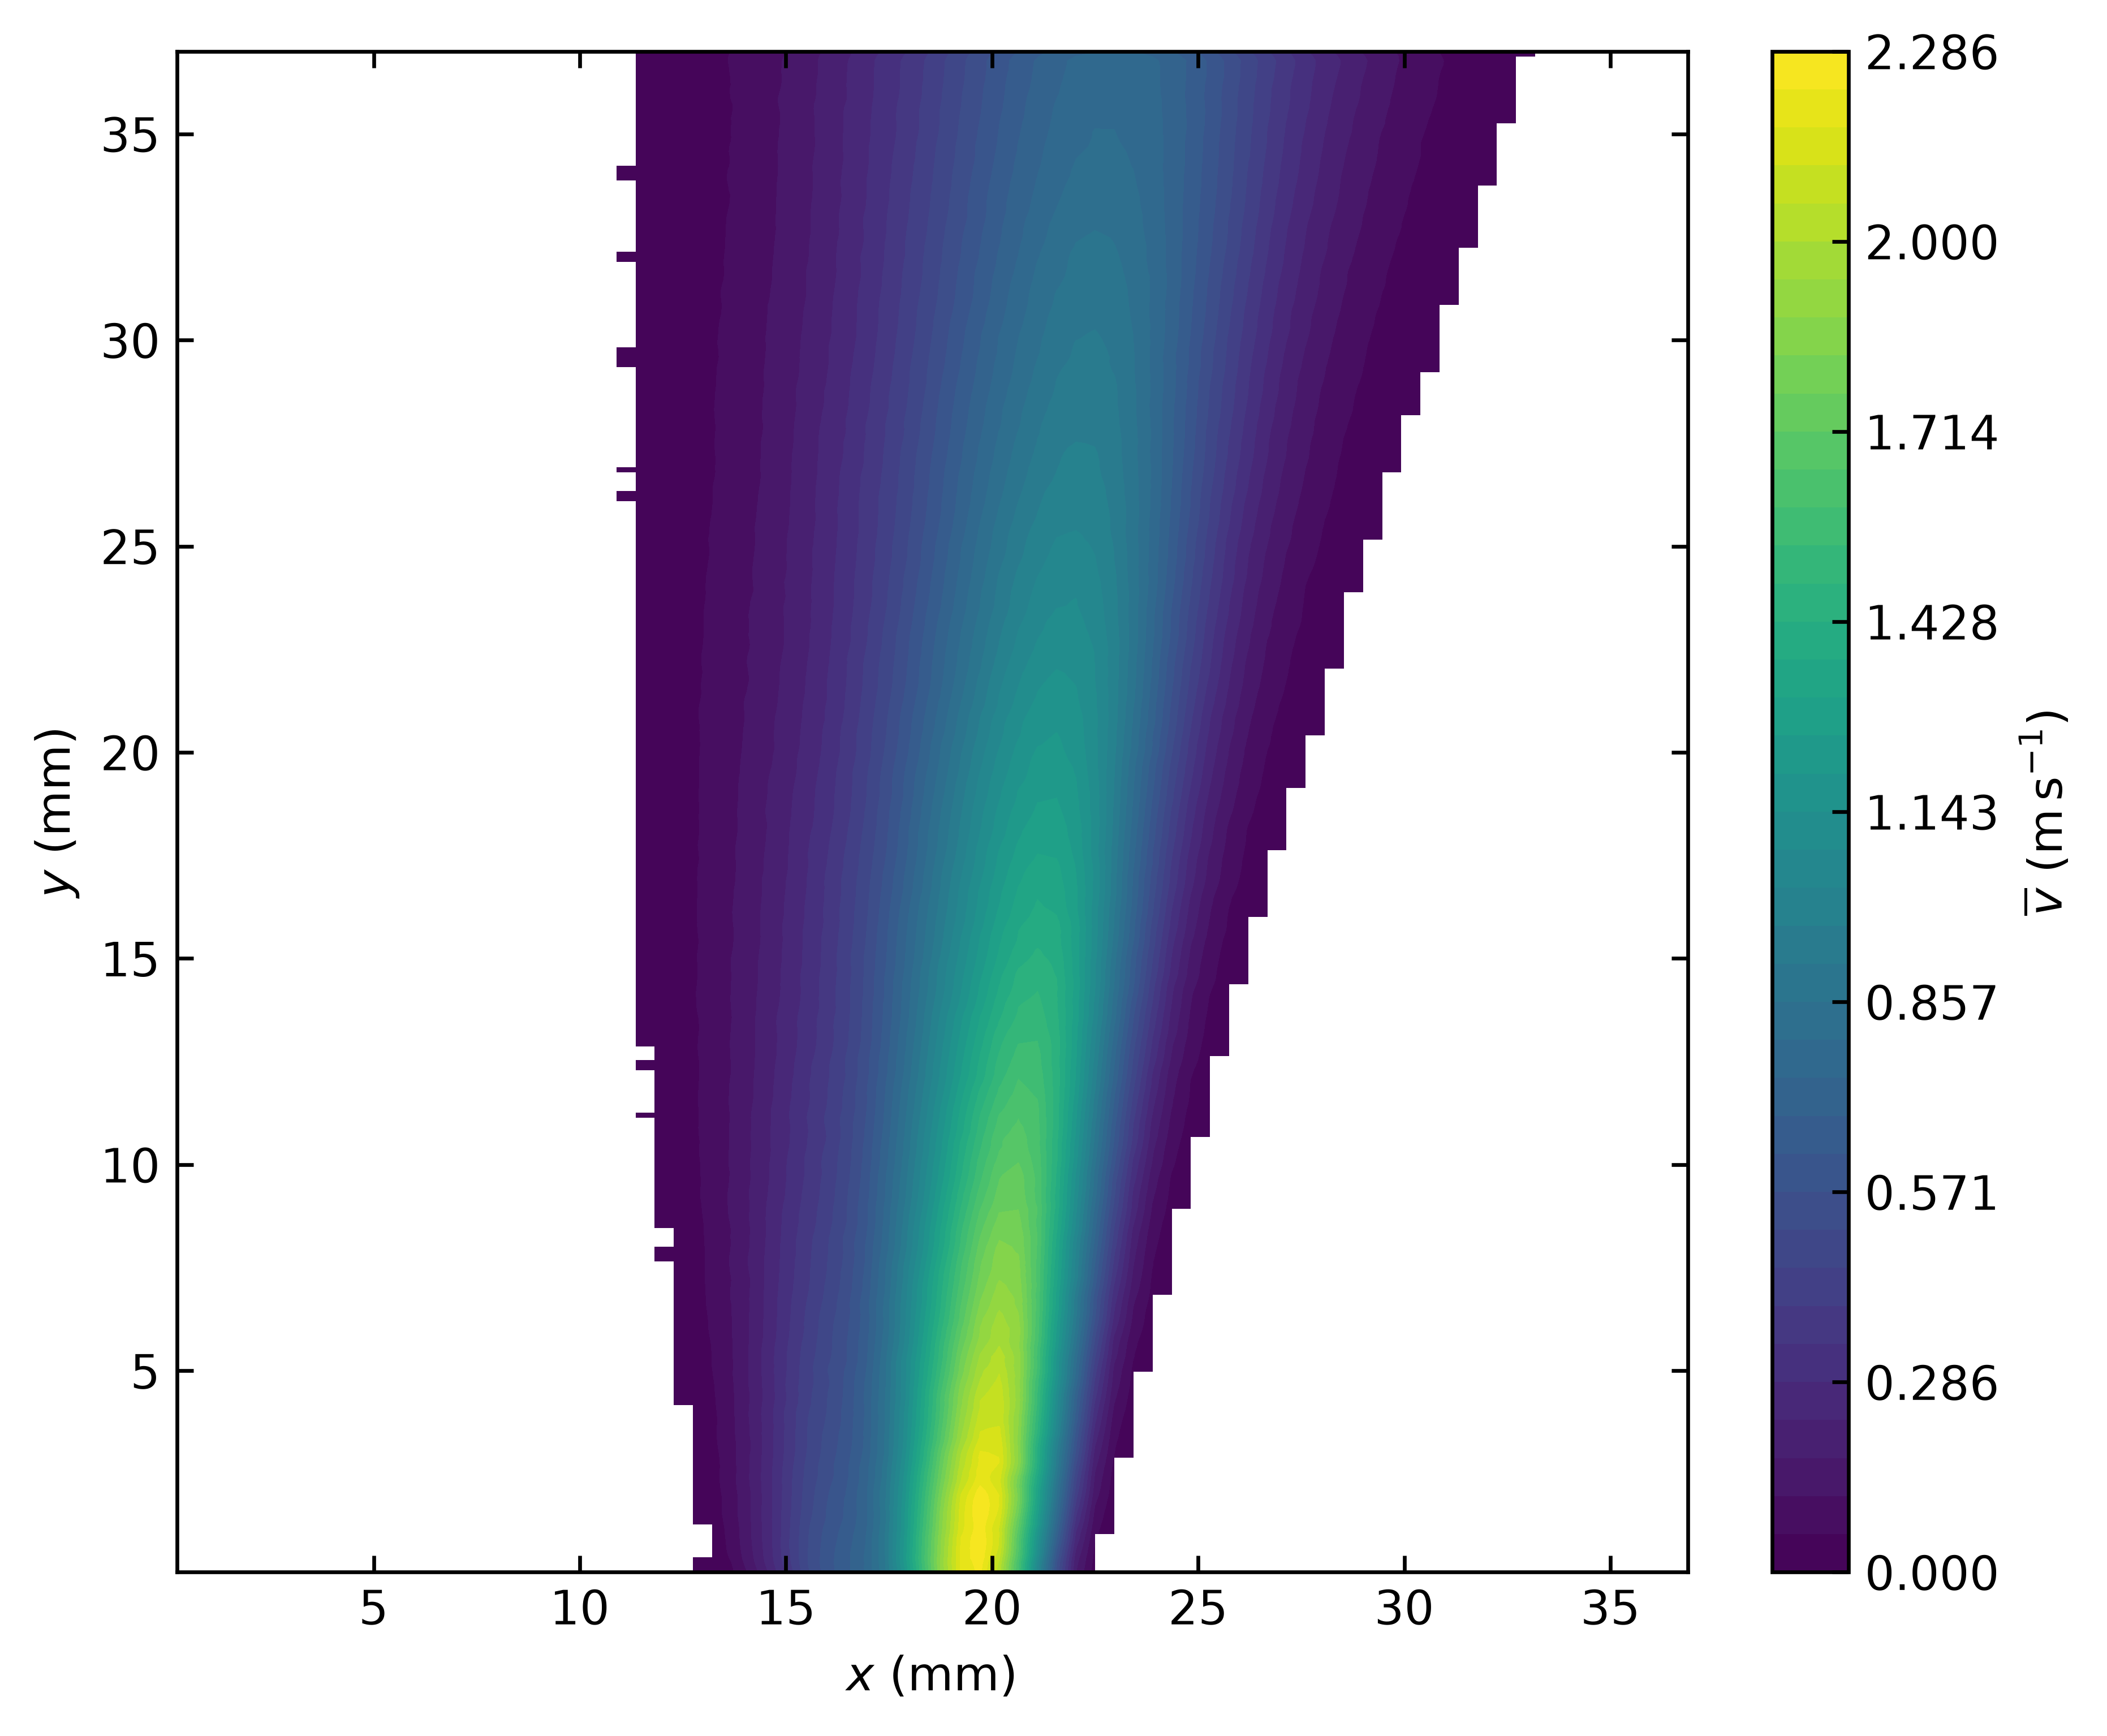

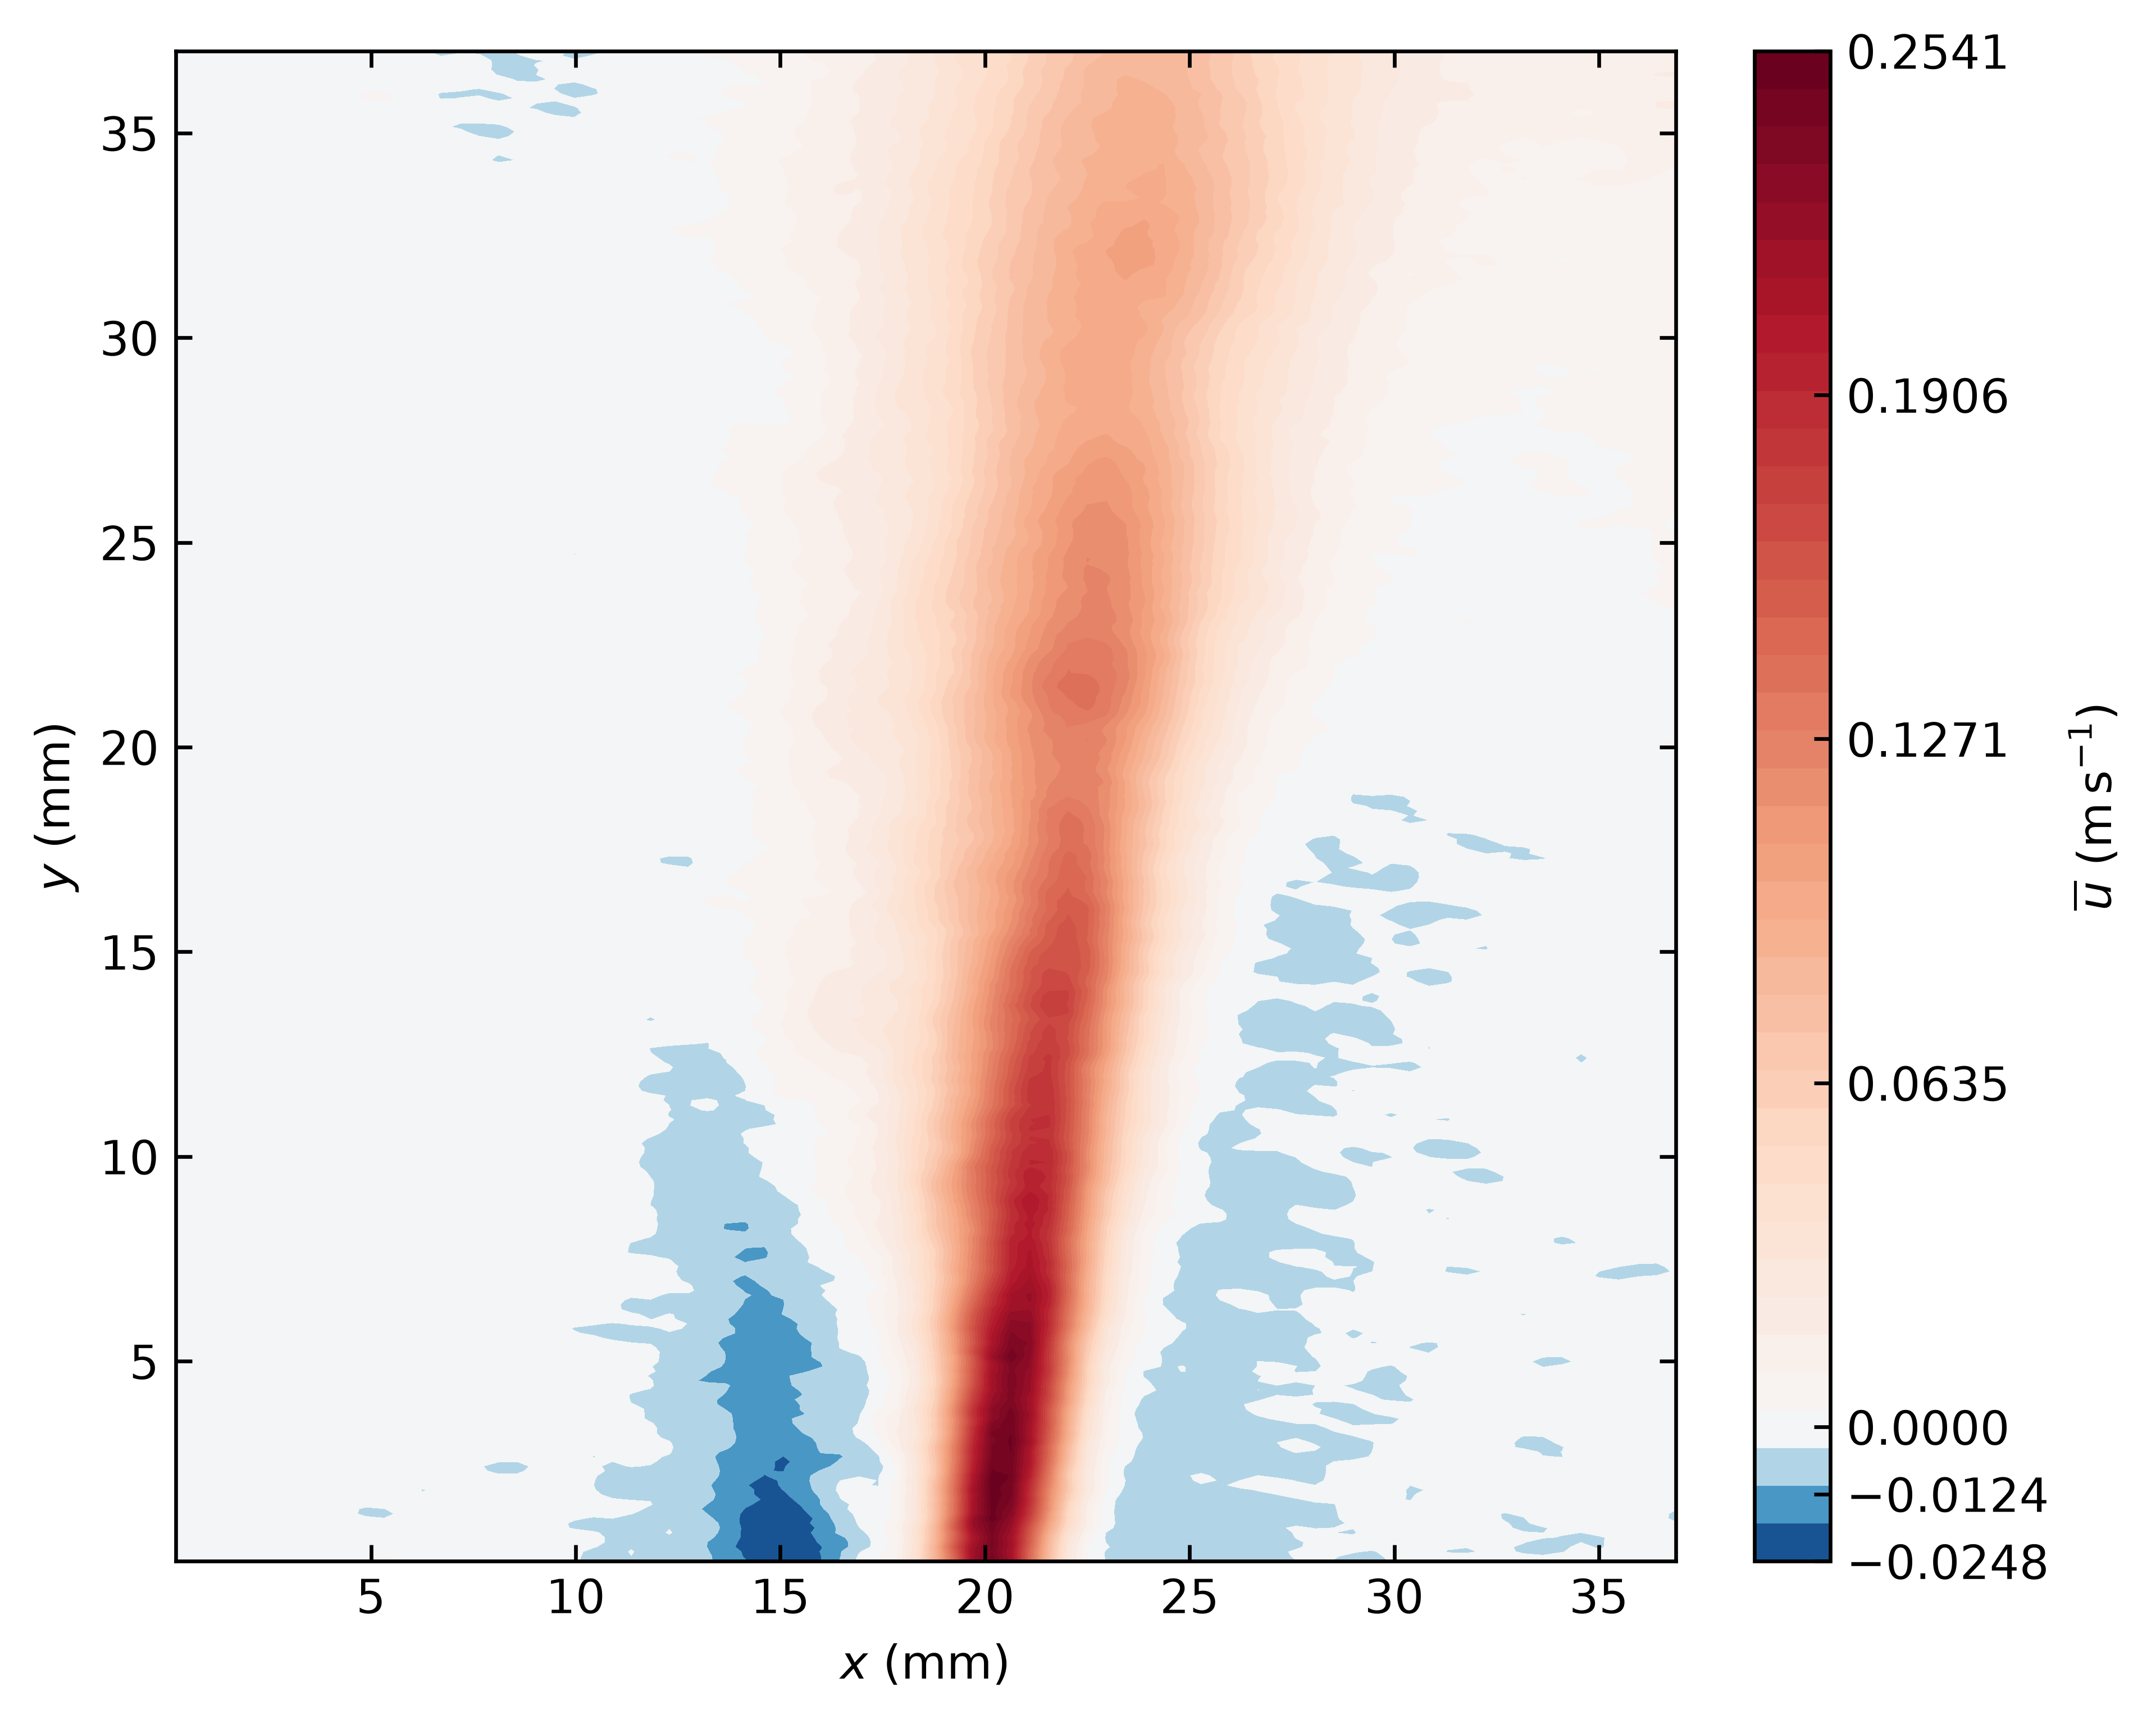

## Component fluctuations, profiles and distributions

rms_v


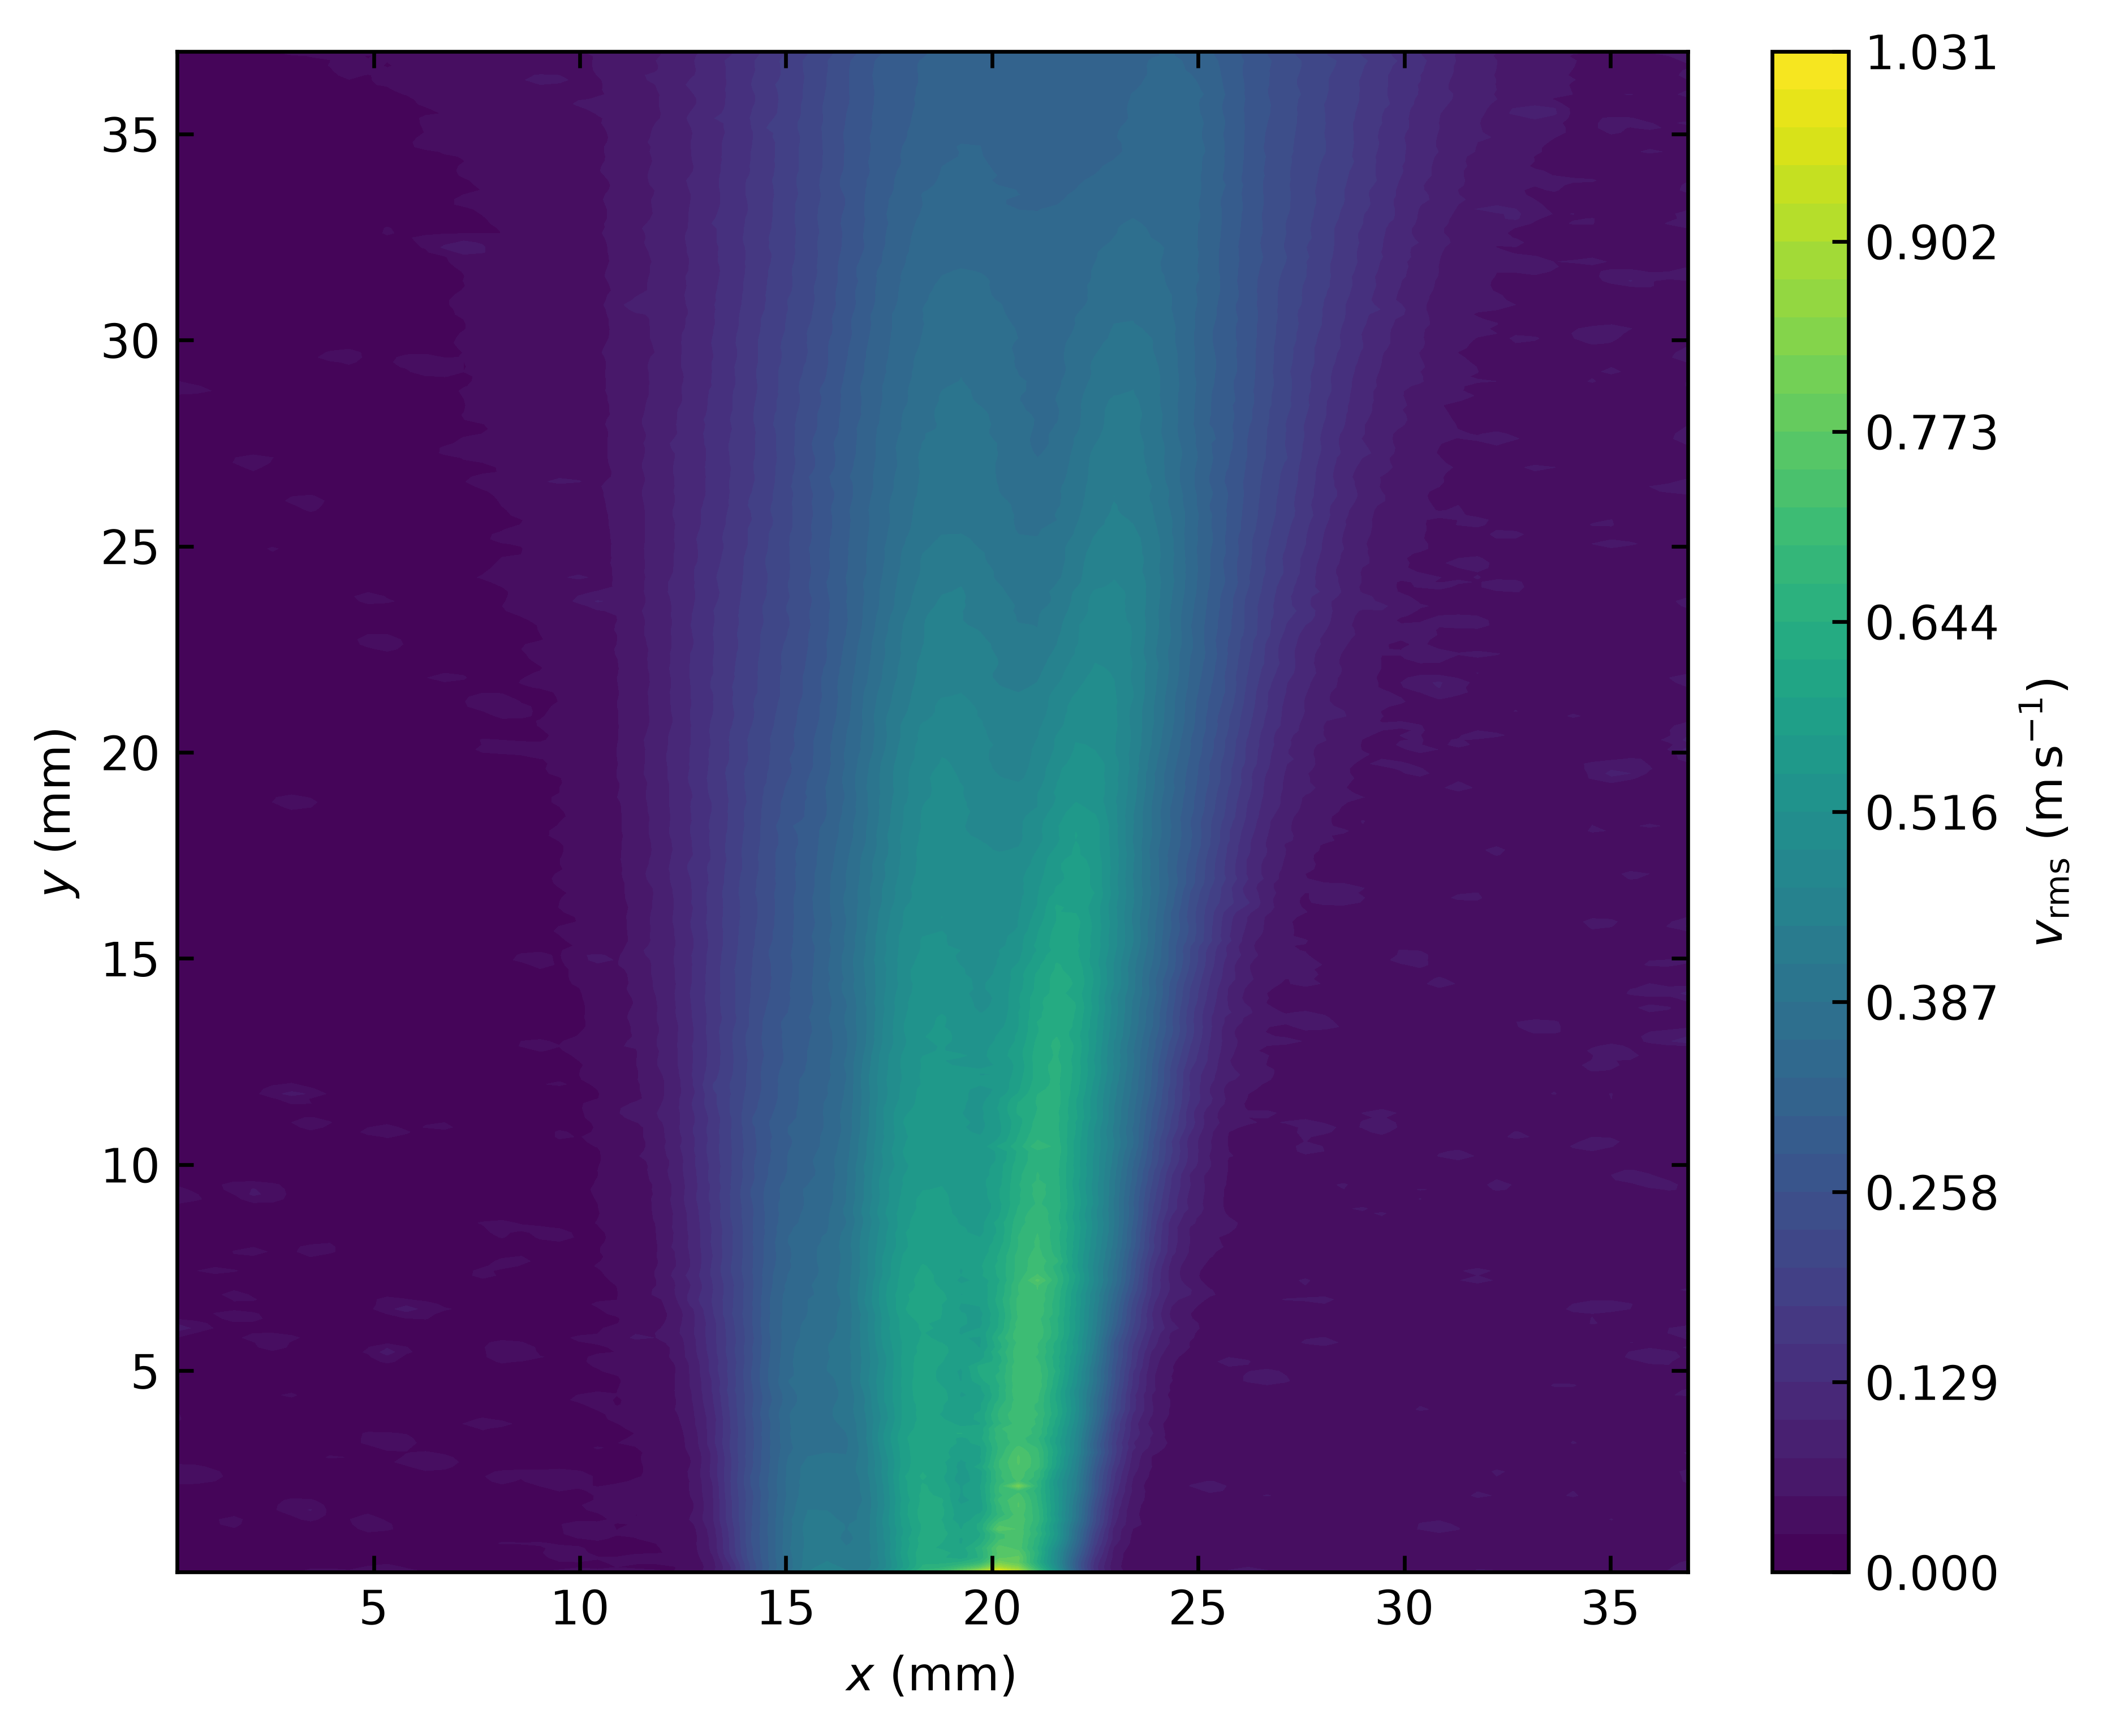

rms_u


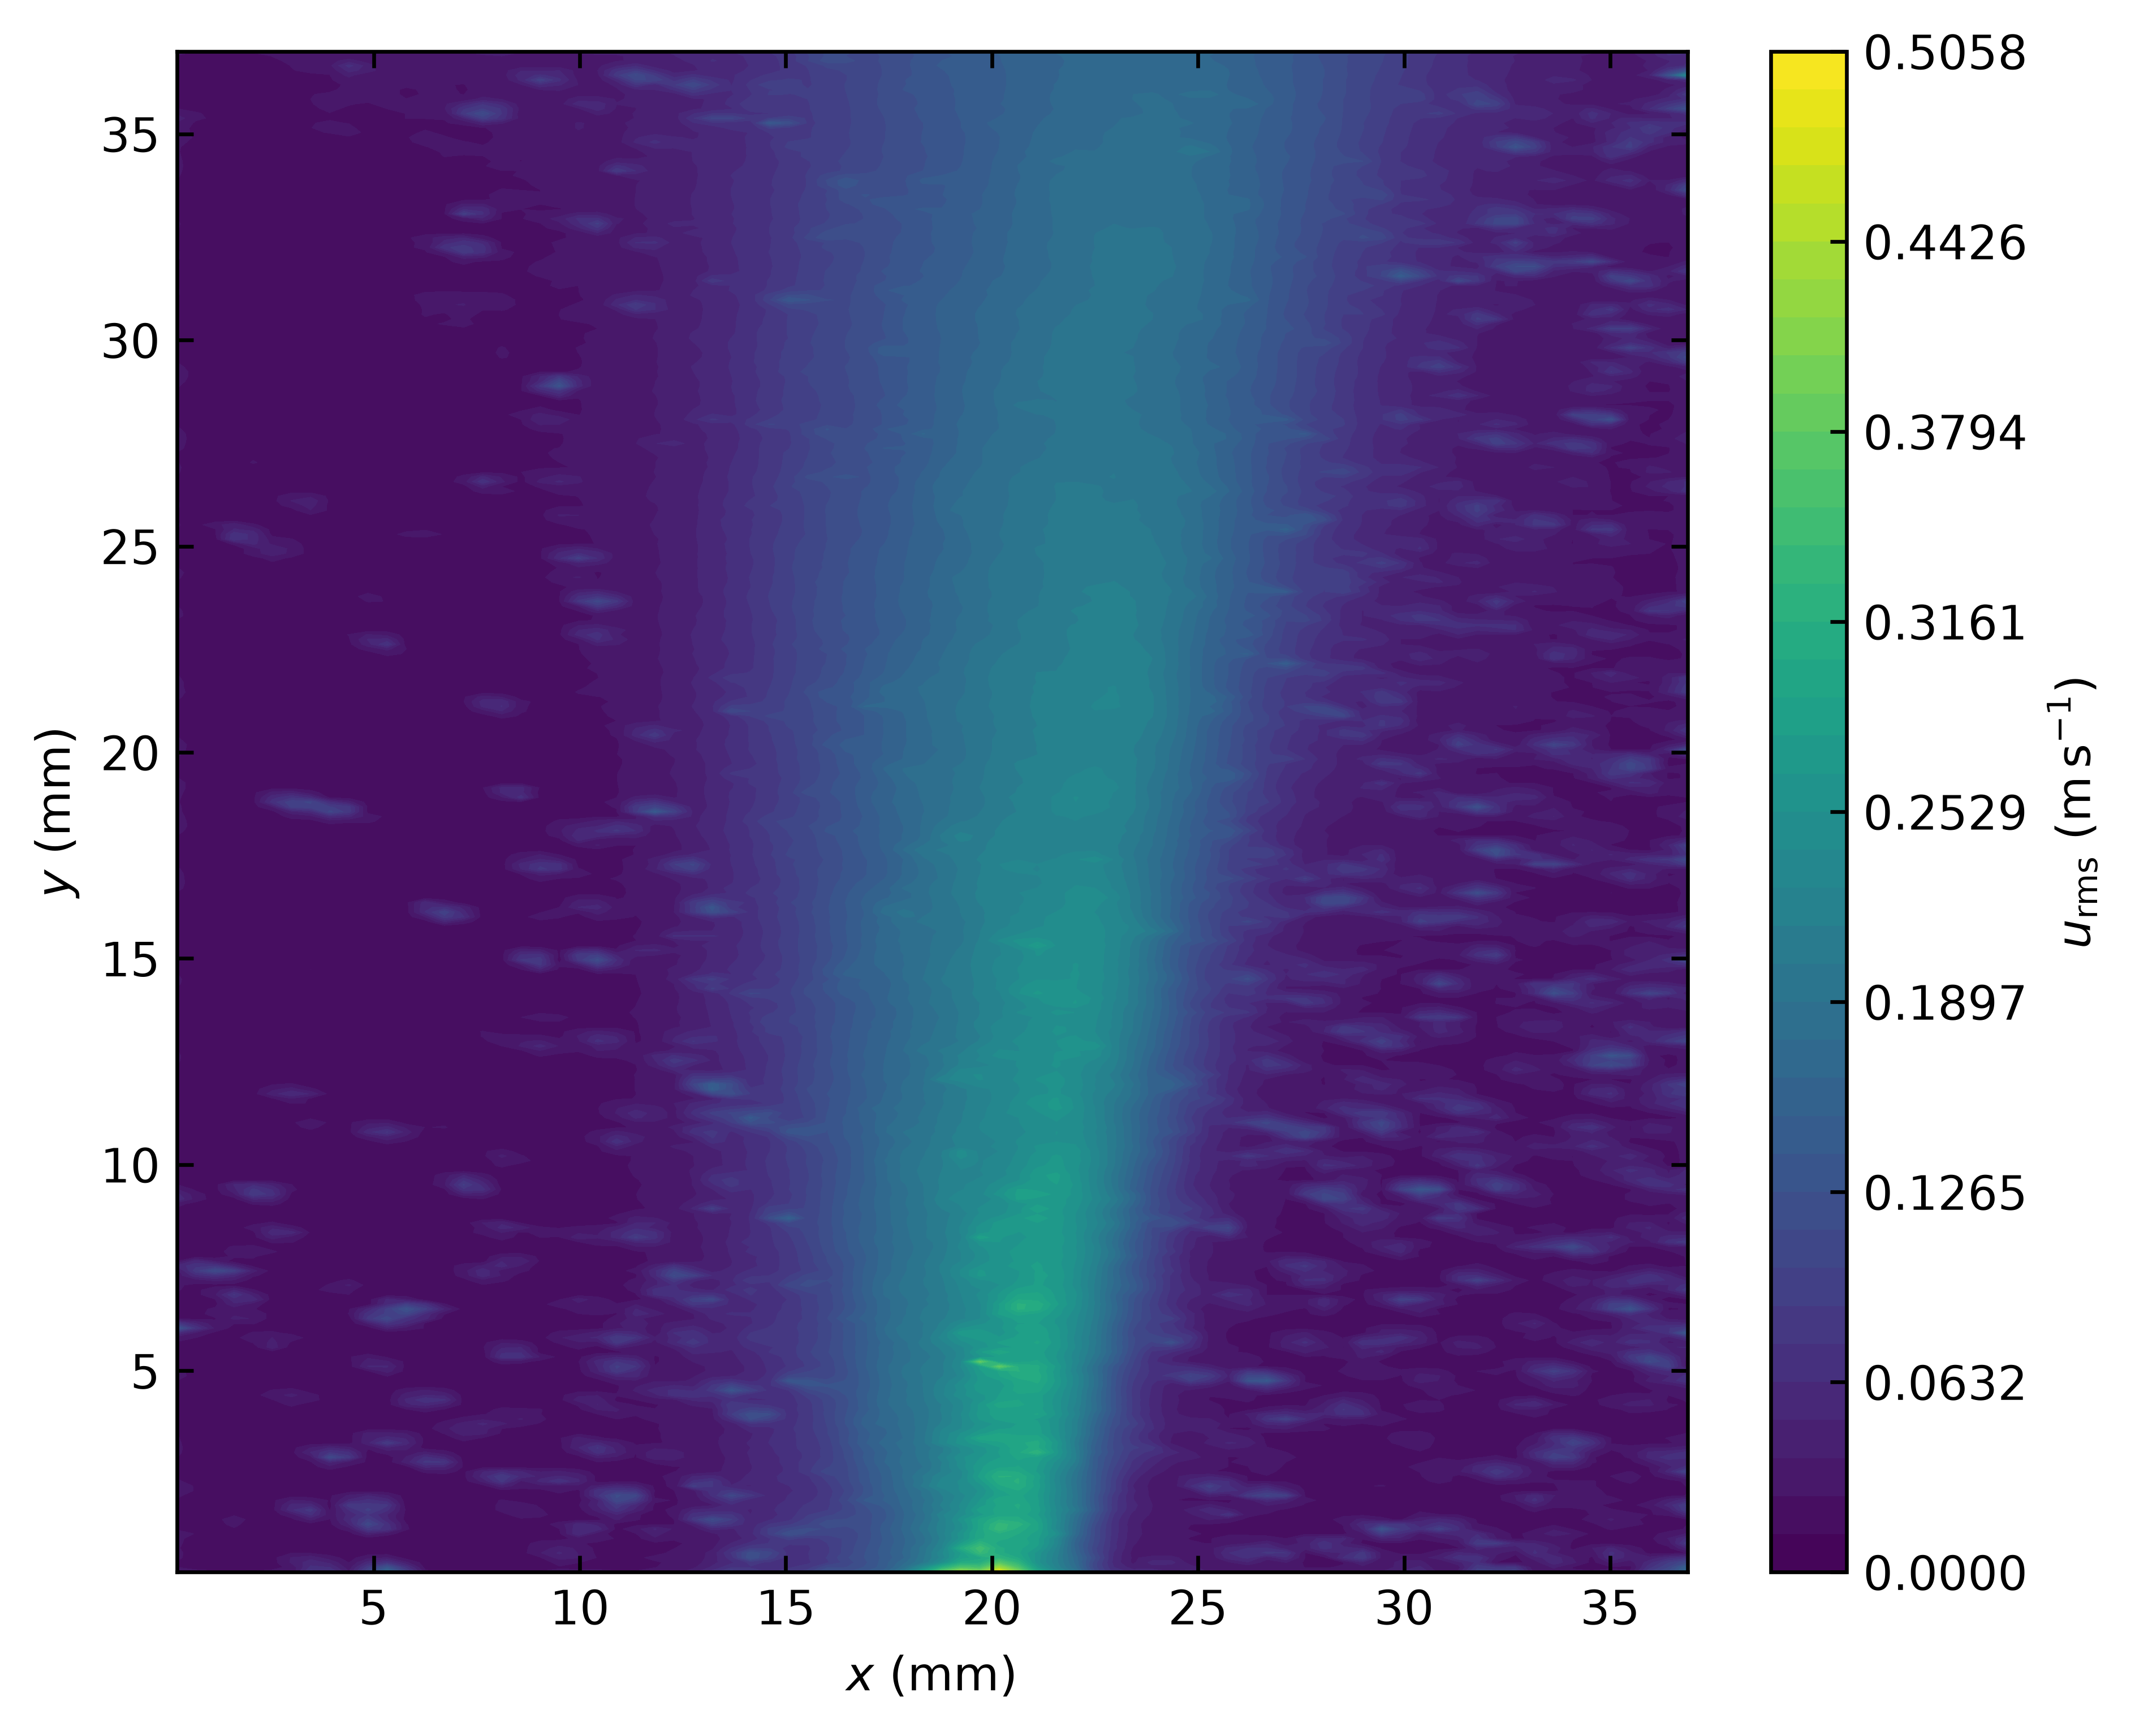

covariance


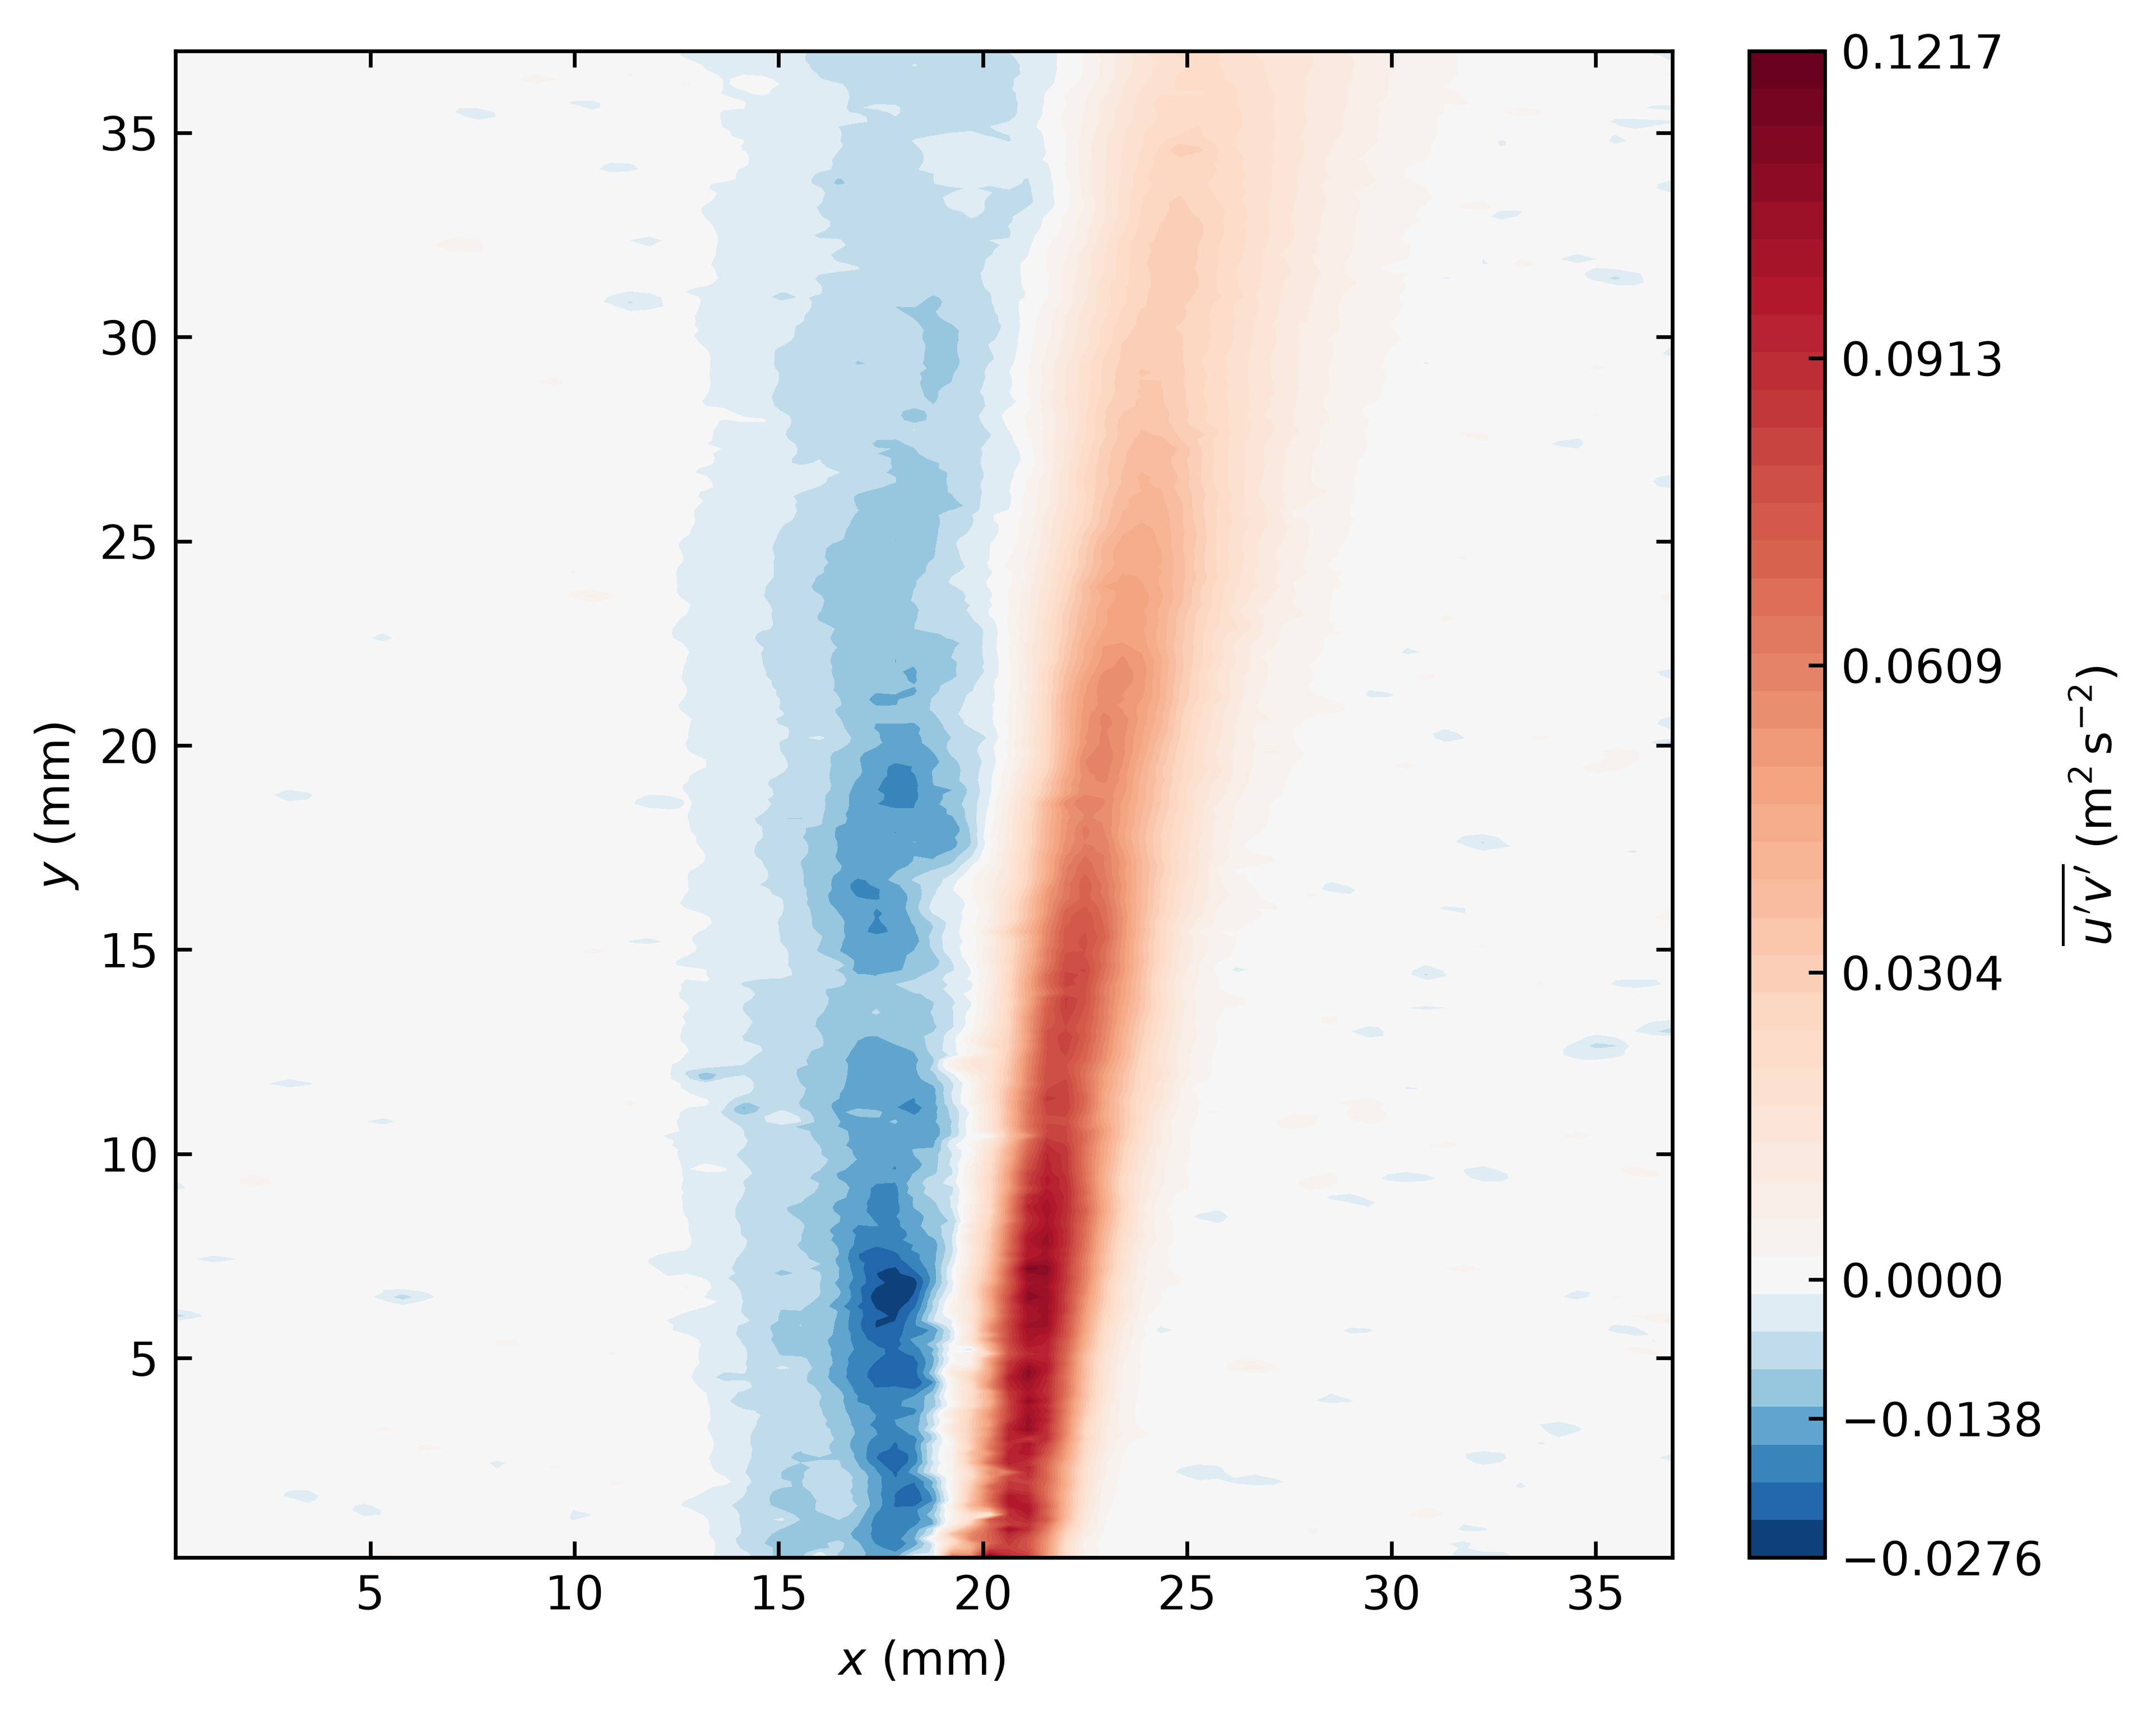

correlation


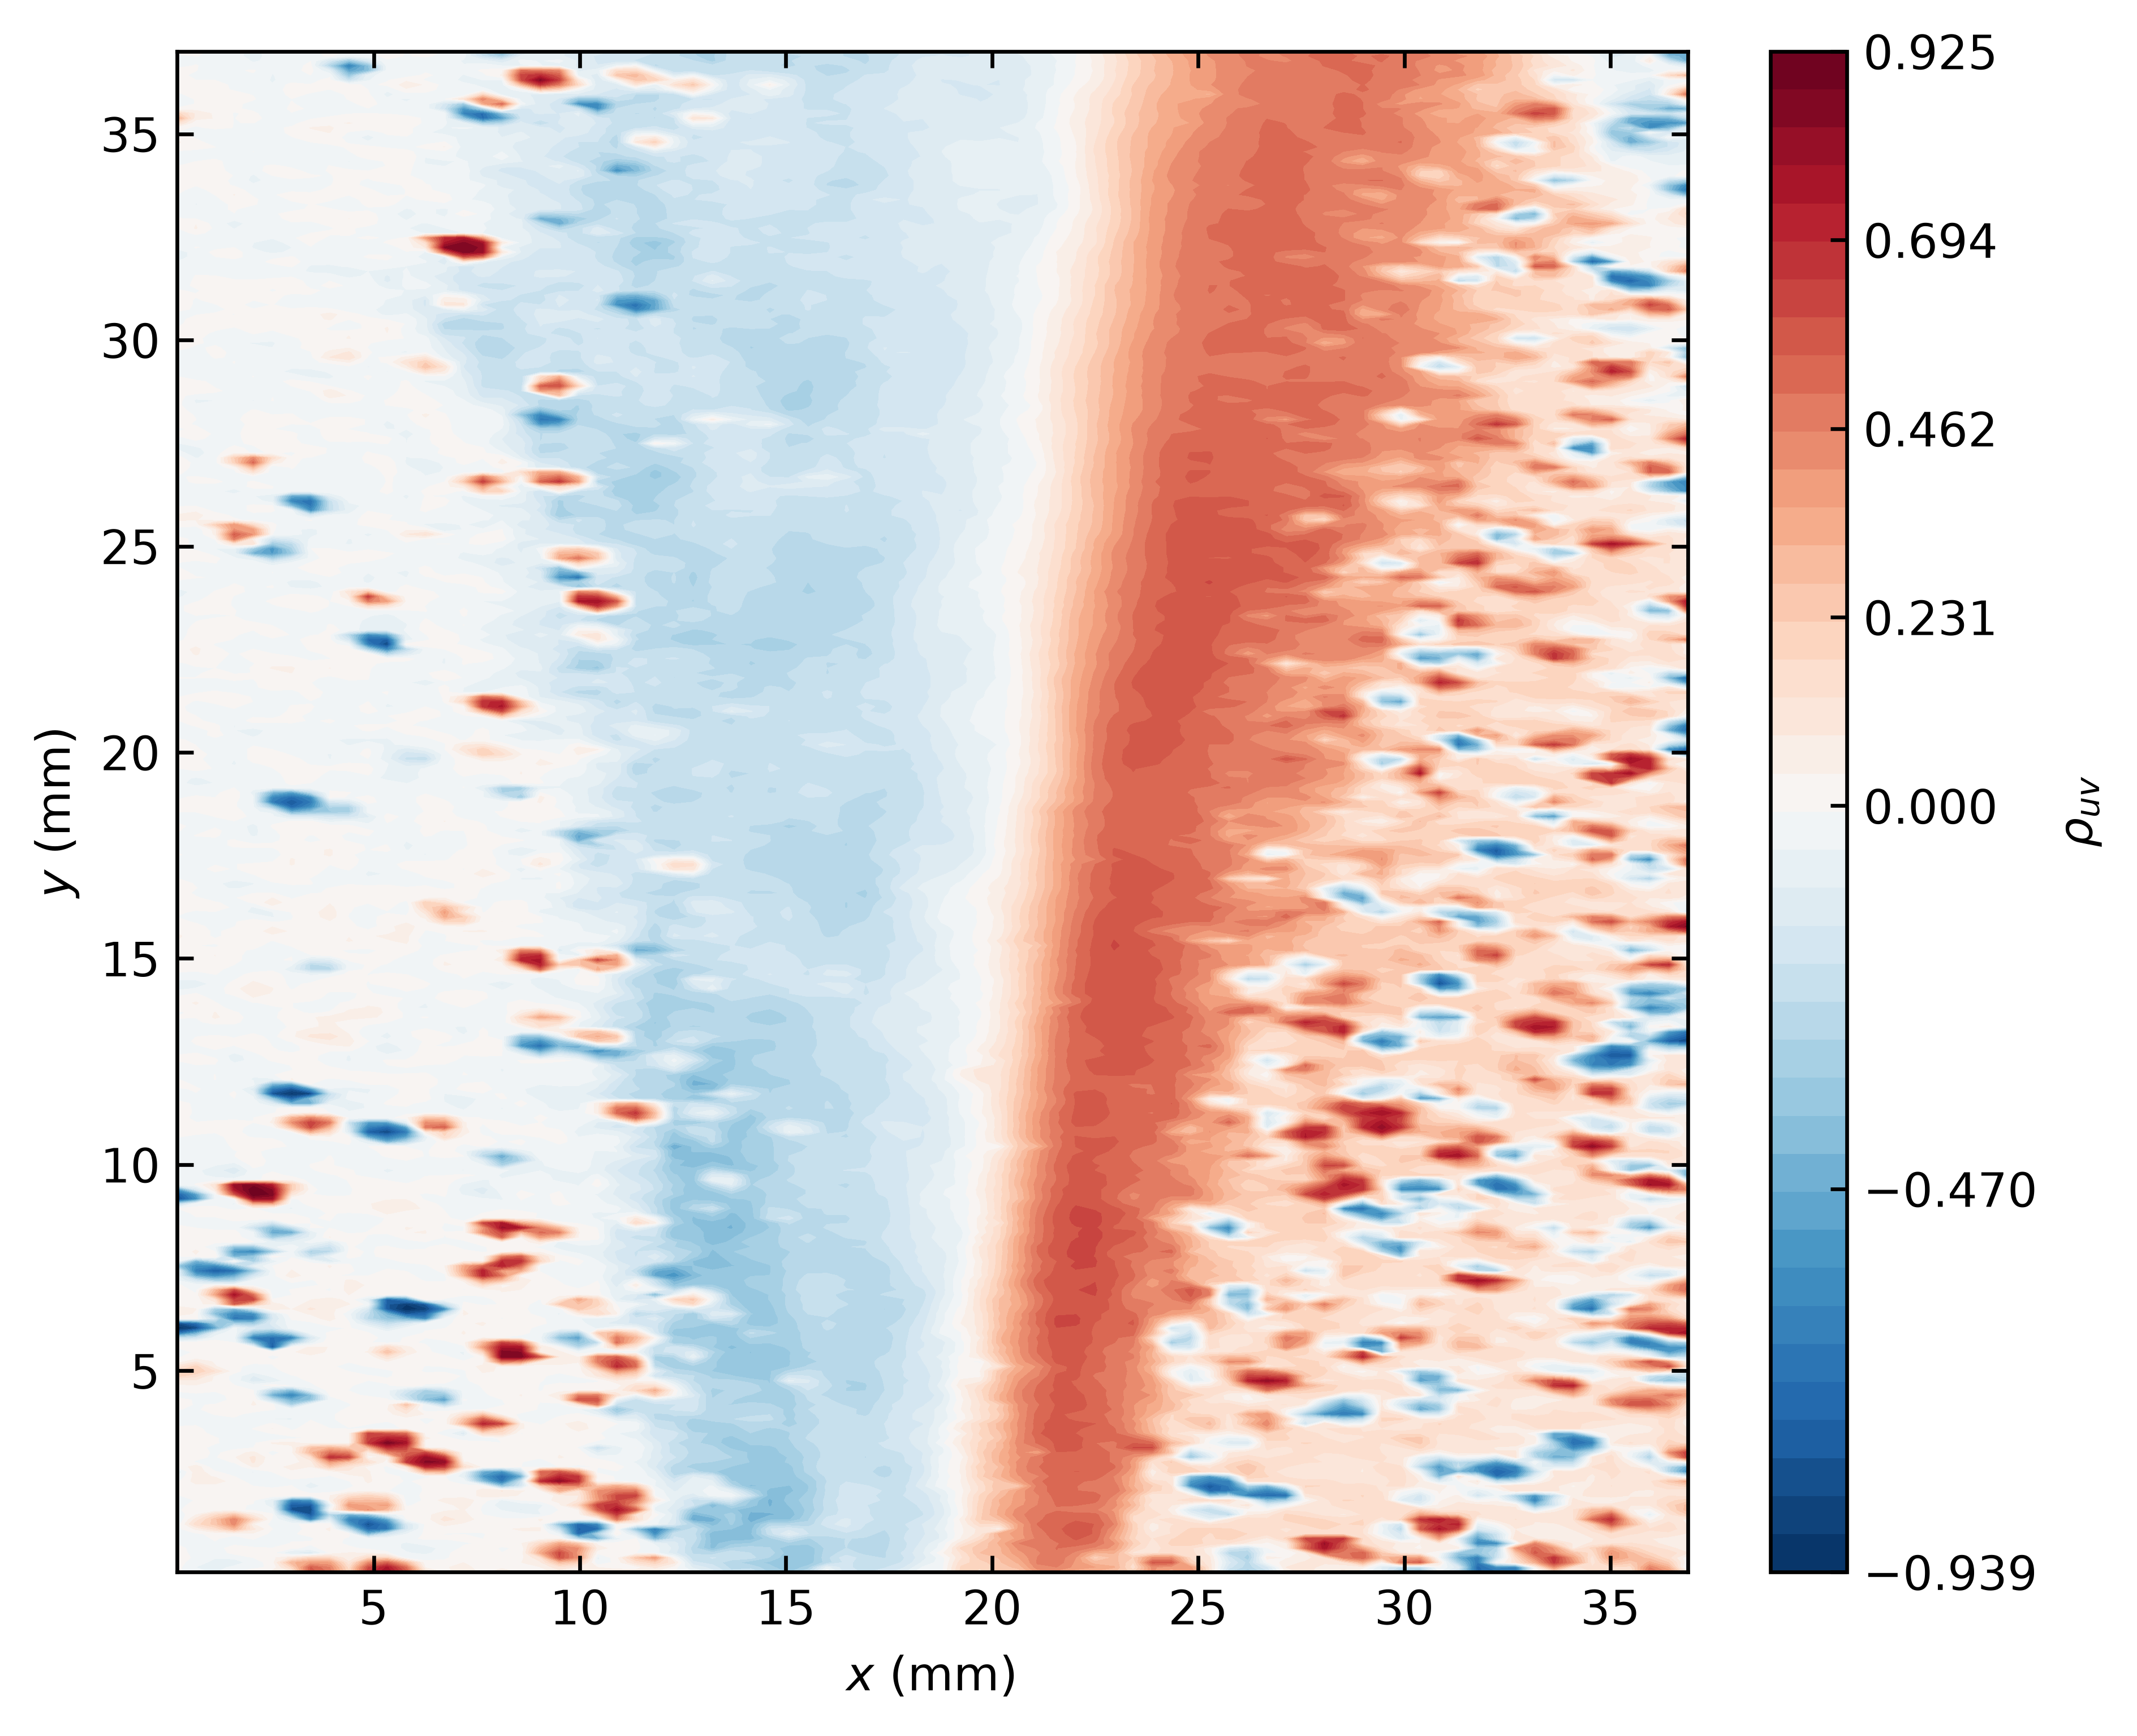

sampling_stations


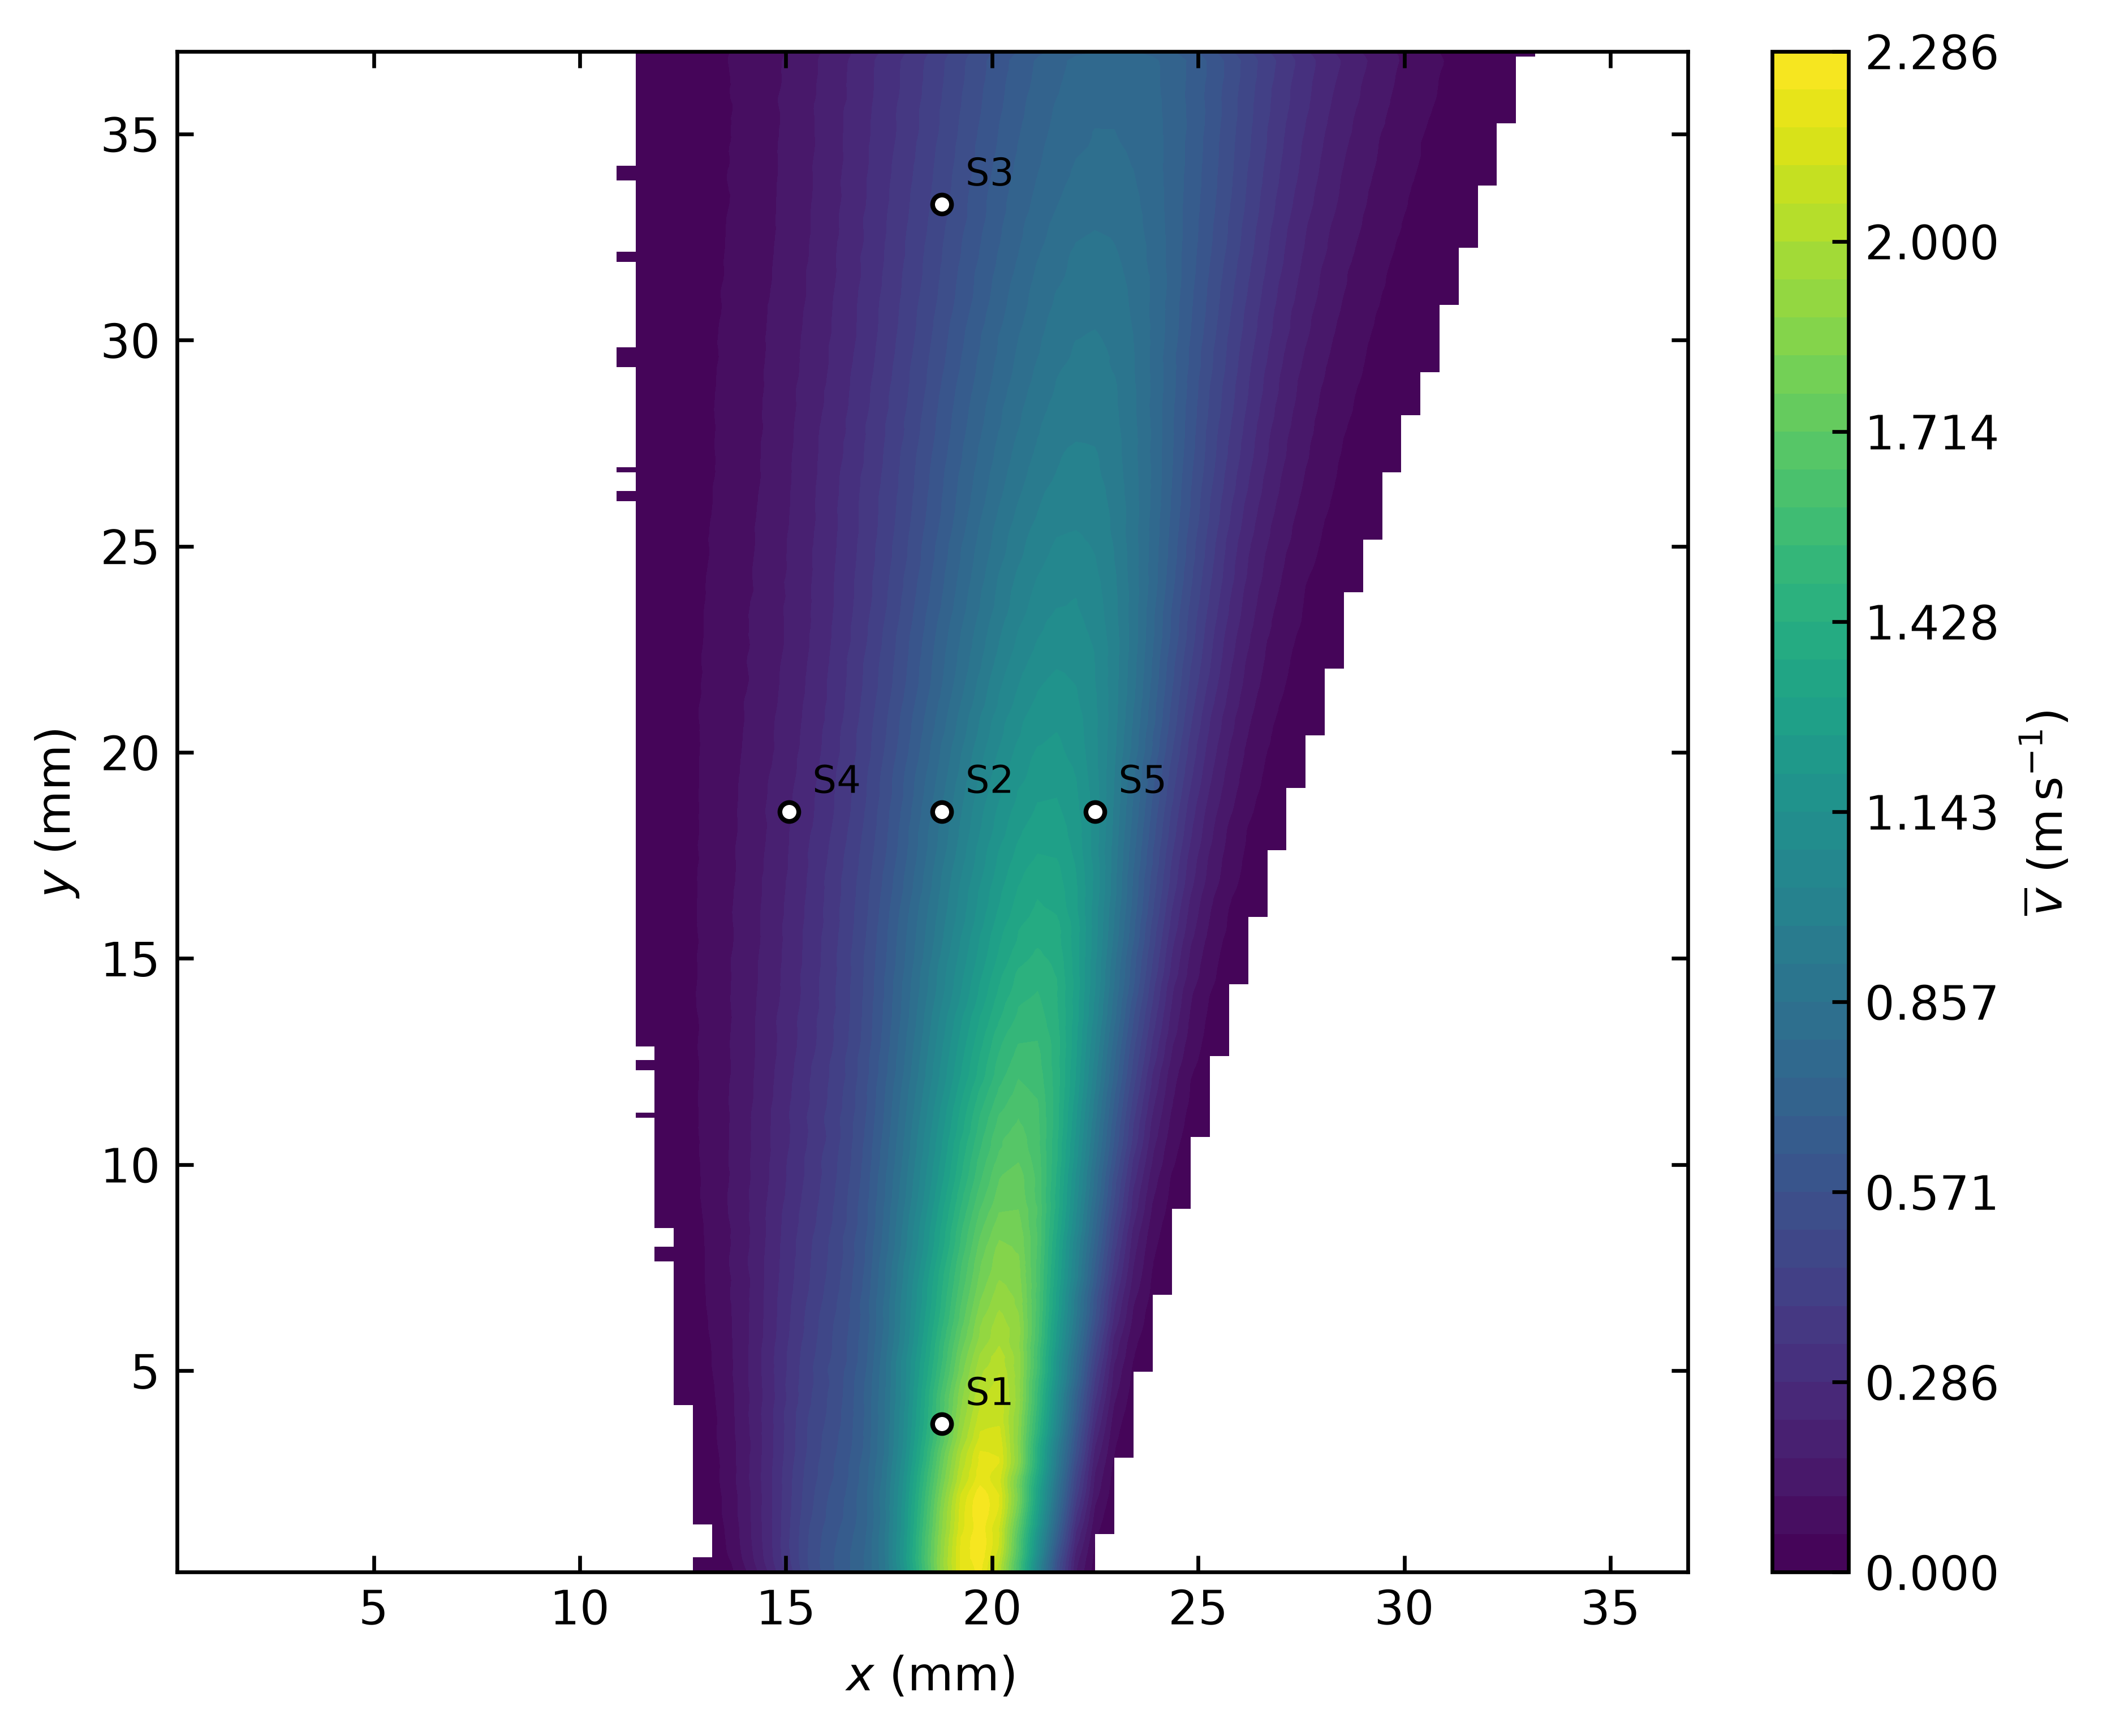

profile_mean_v


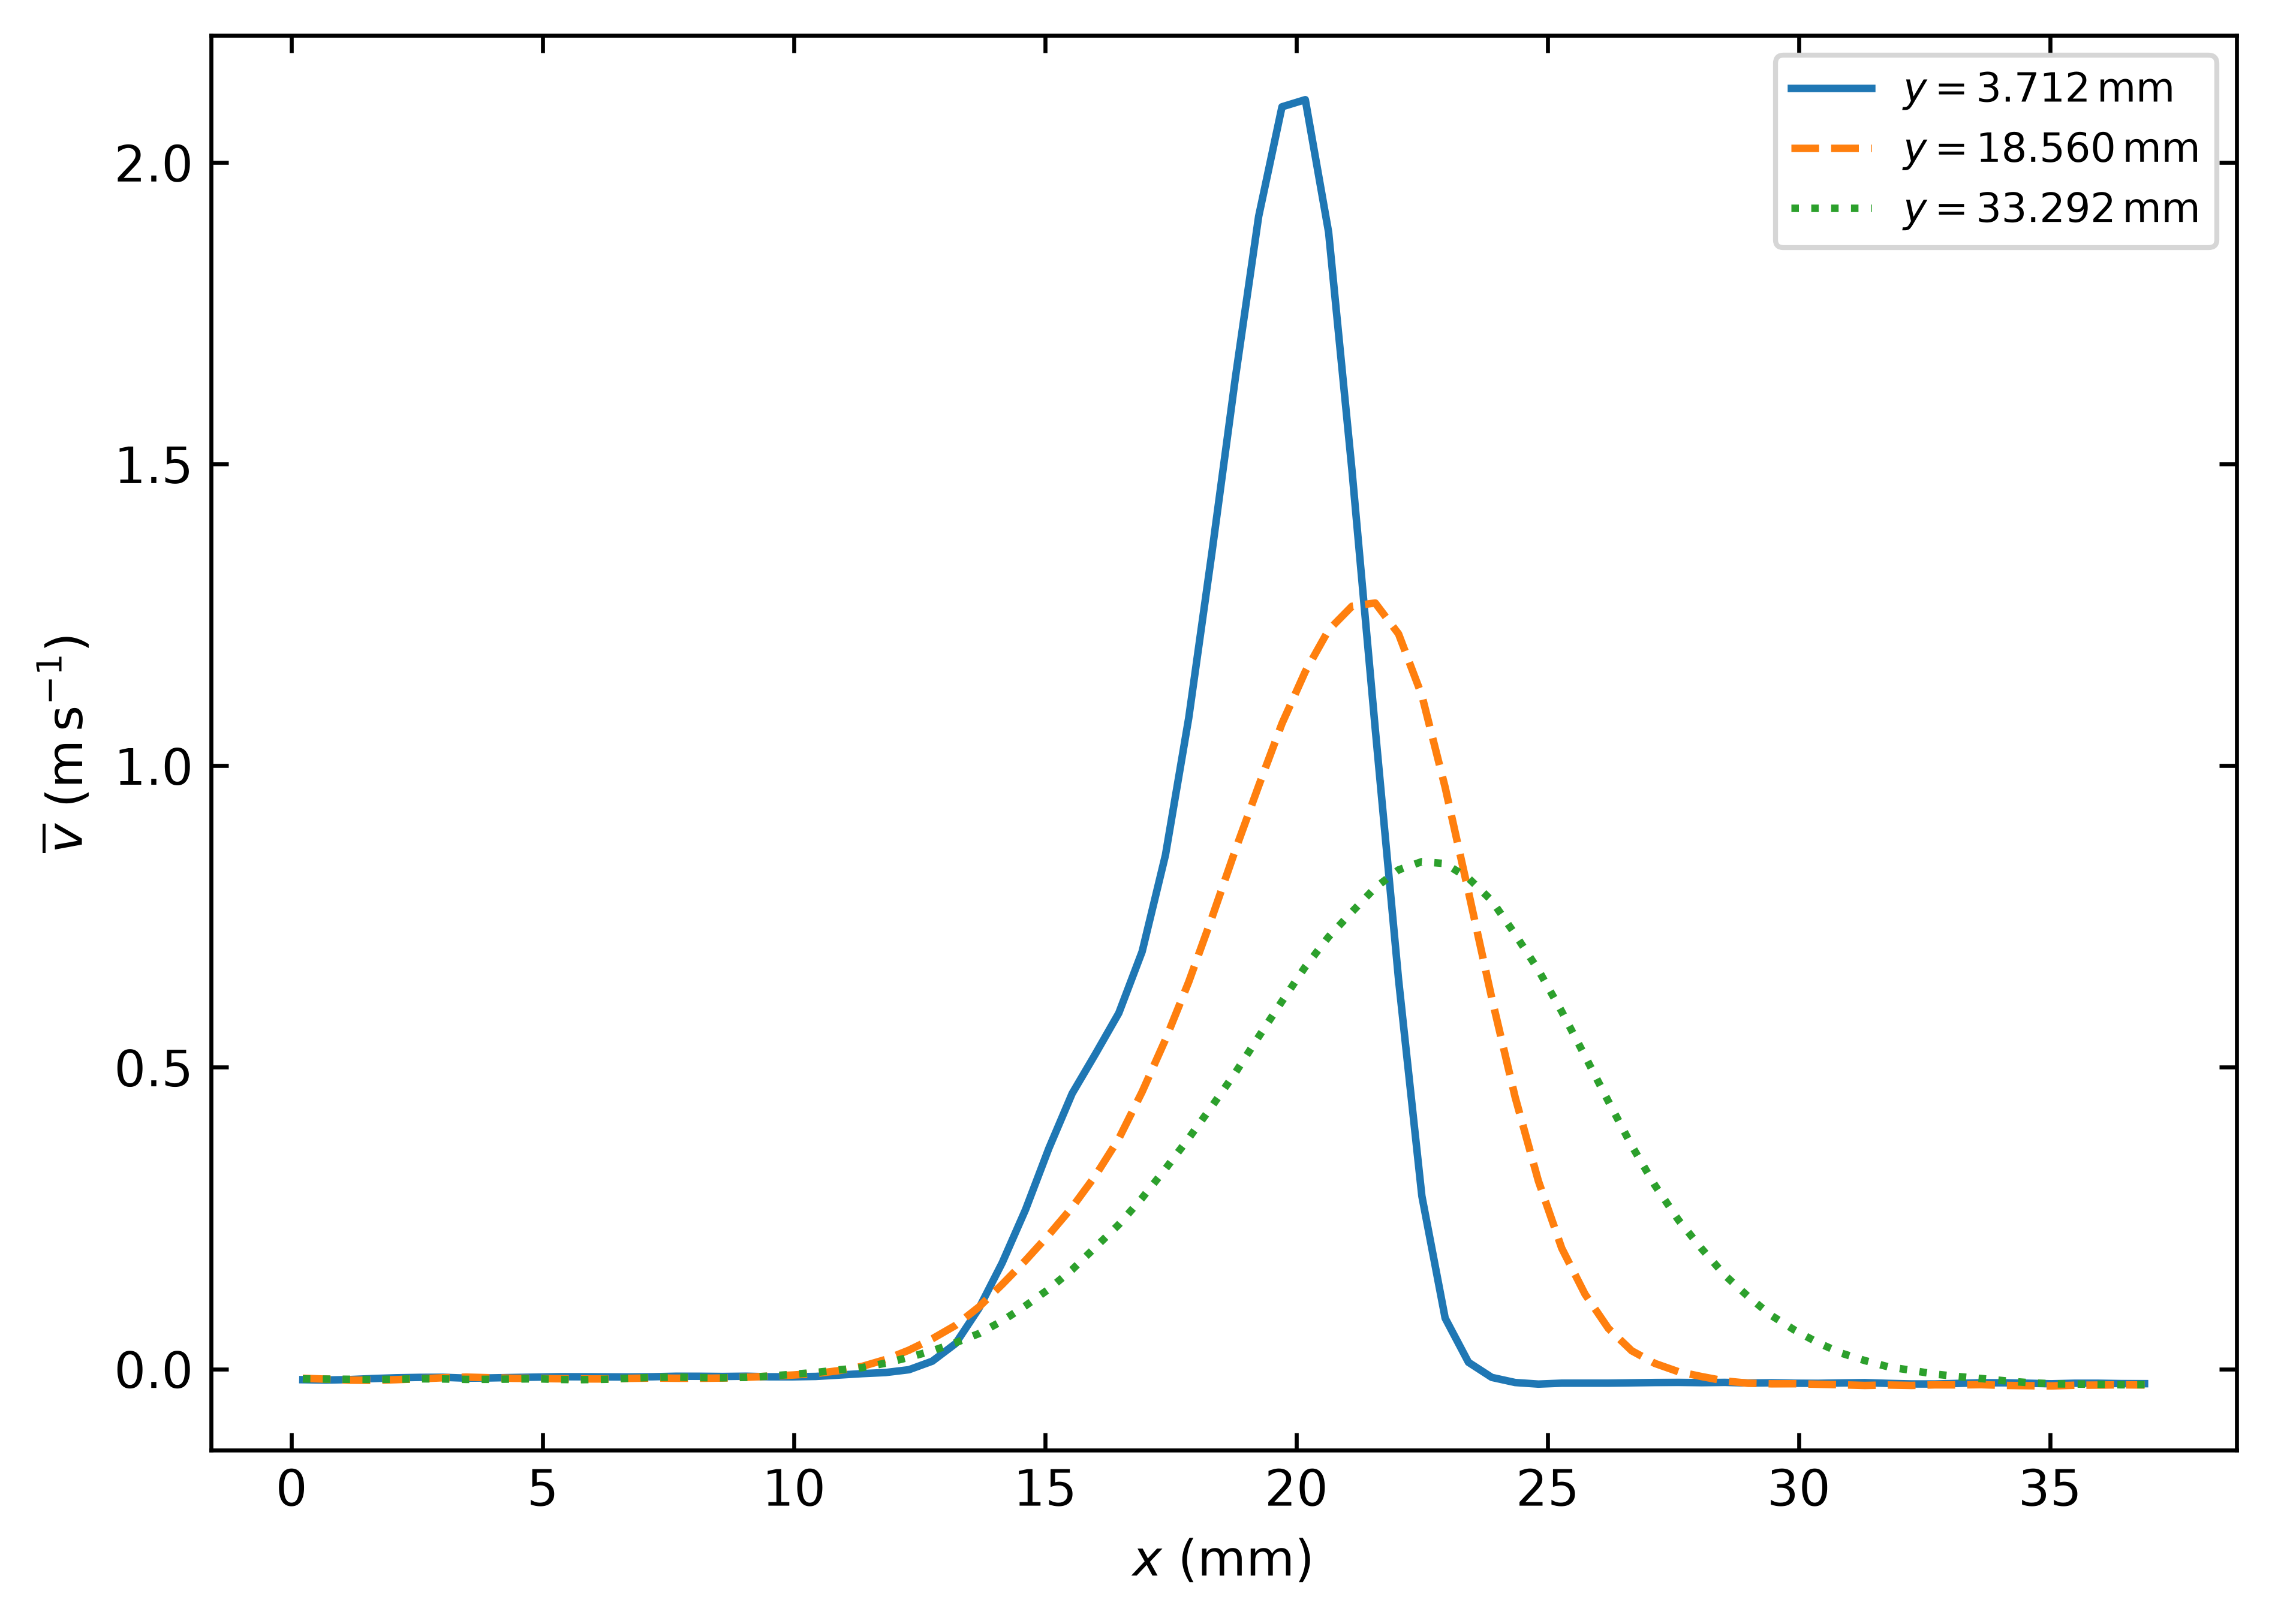

profile_rms_v


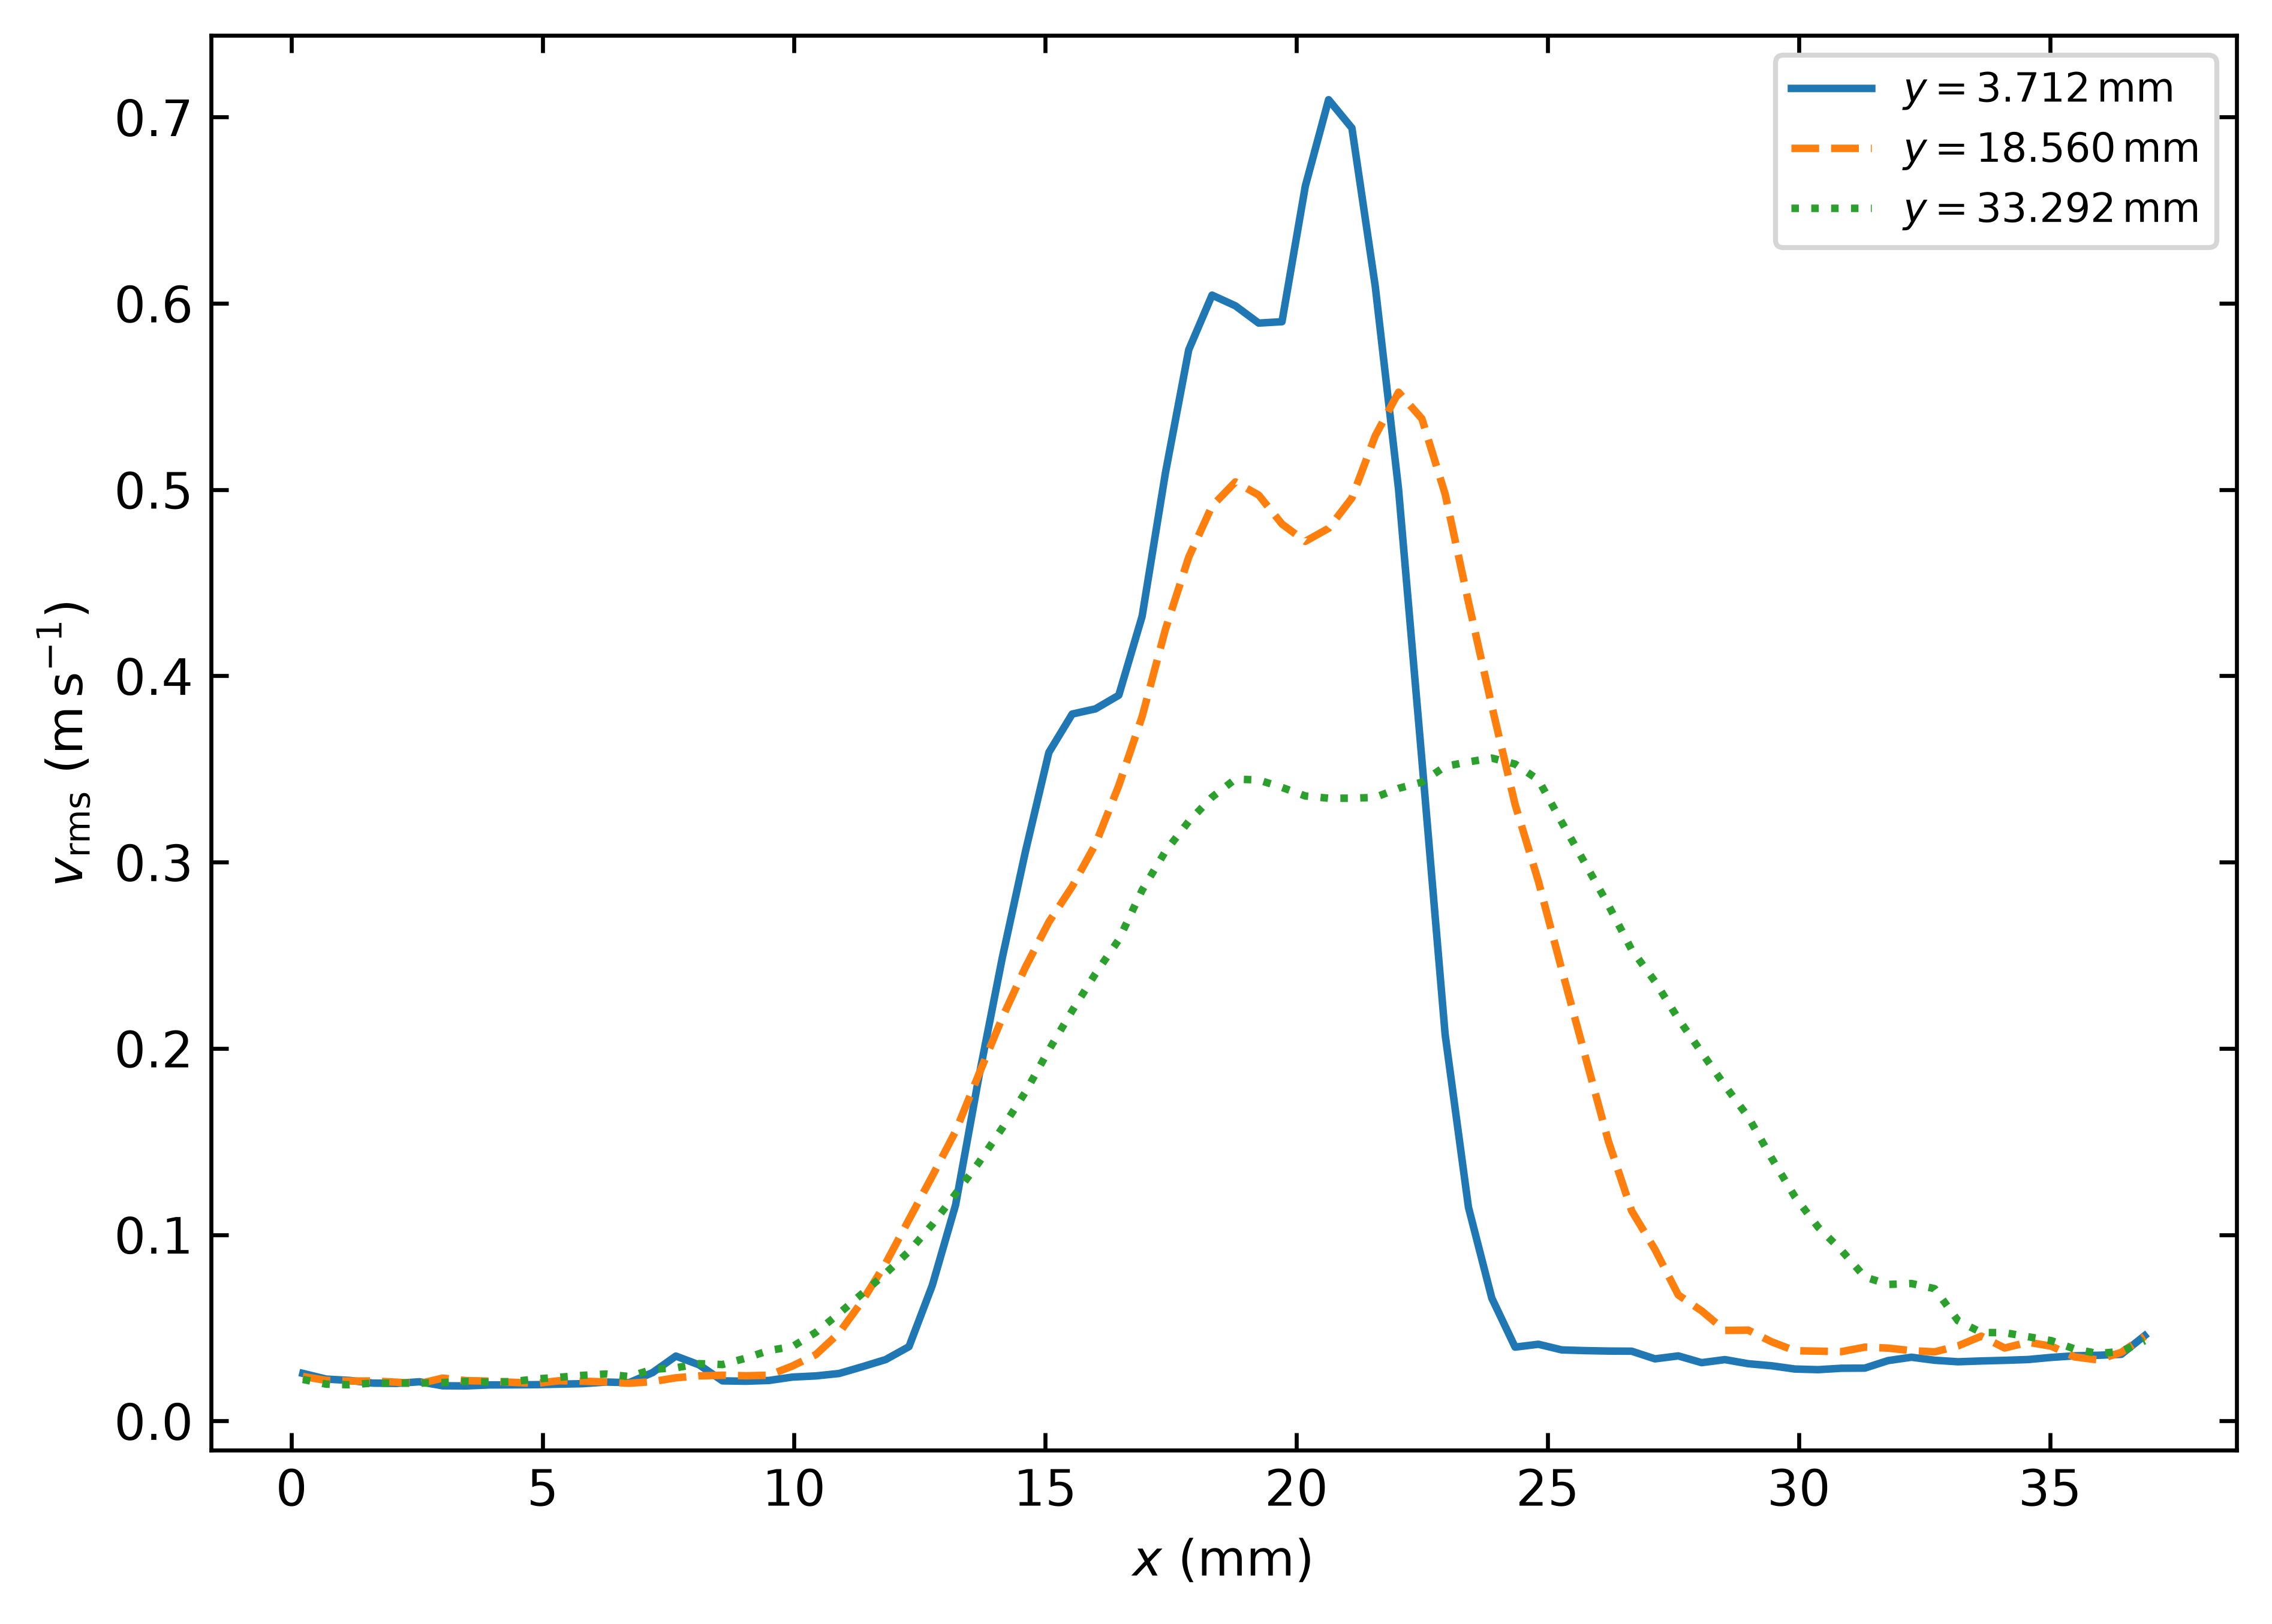

profile_rms_u


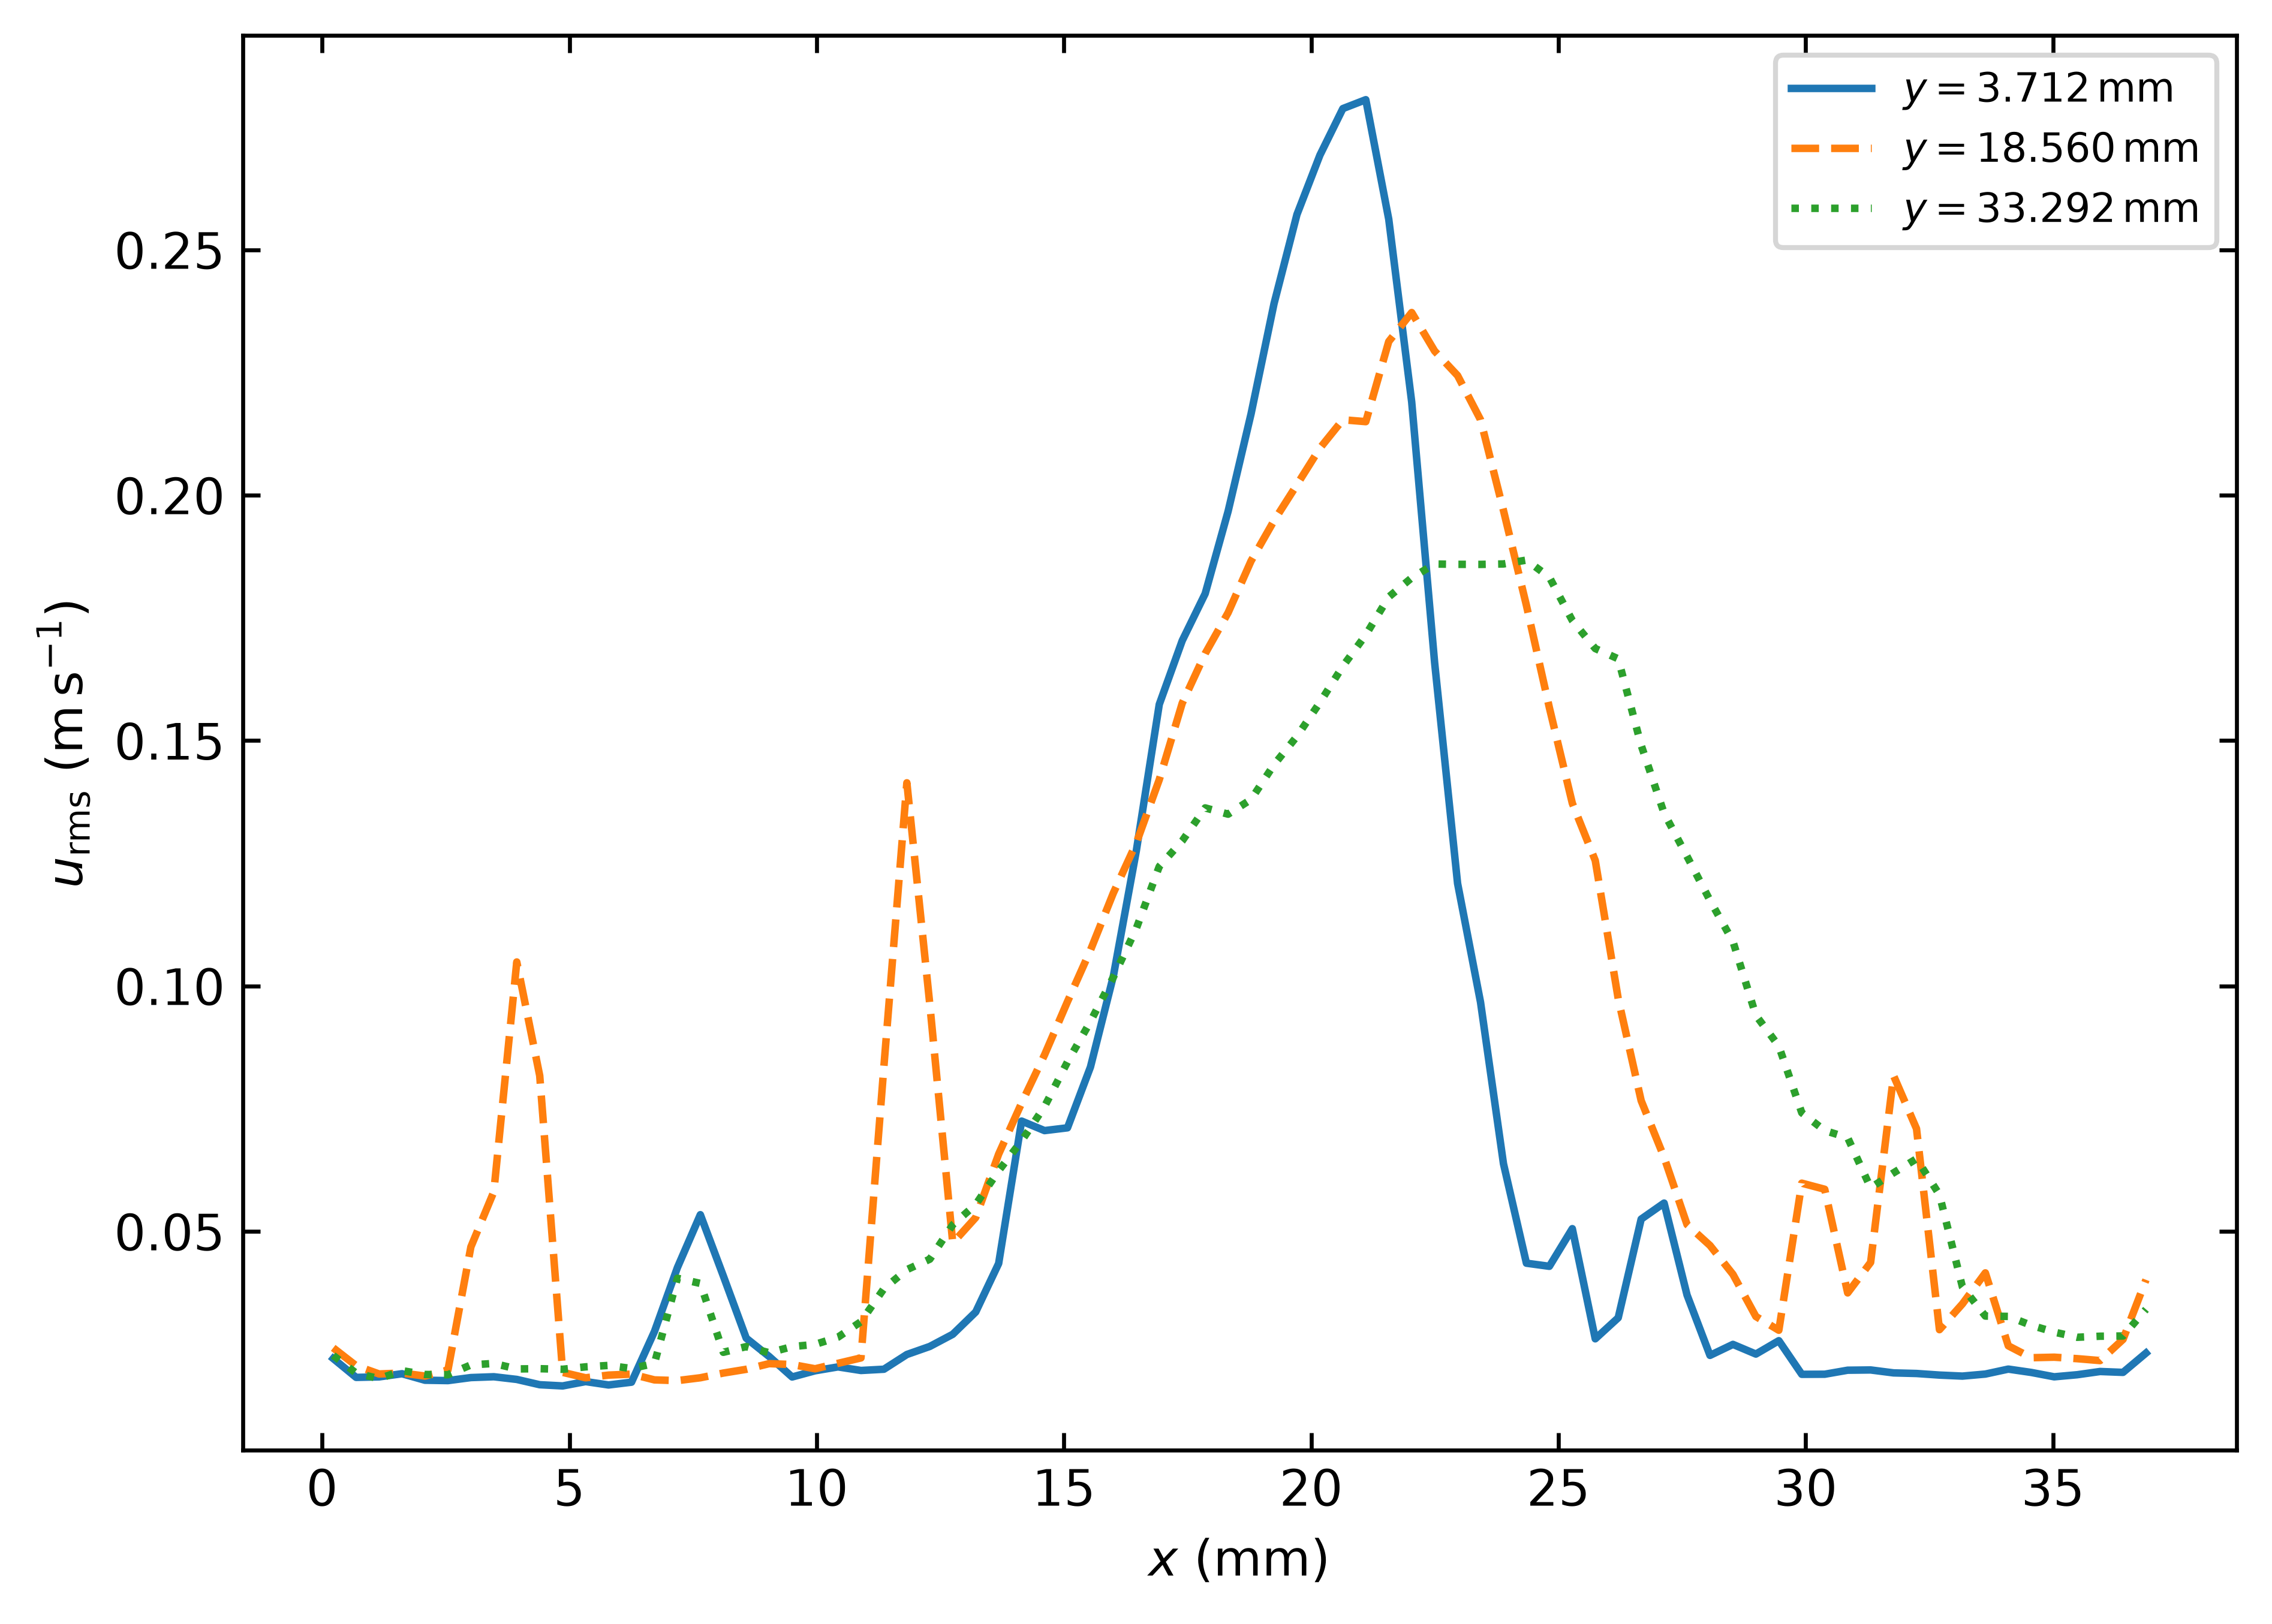

profile_covariance


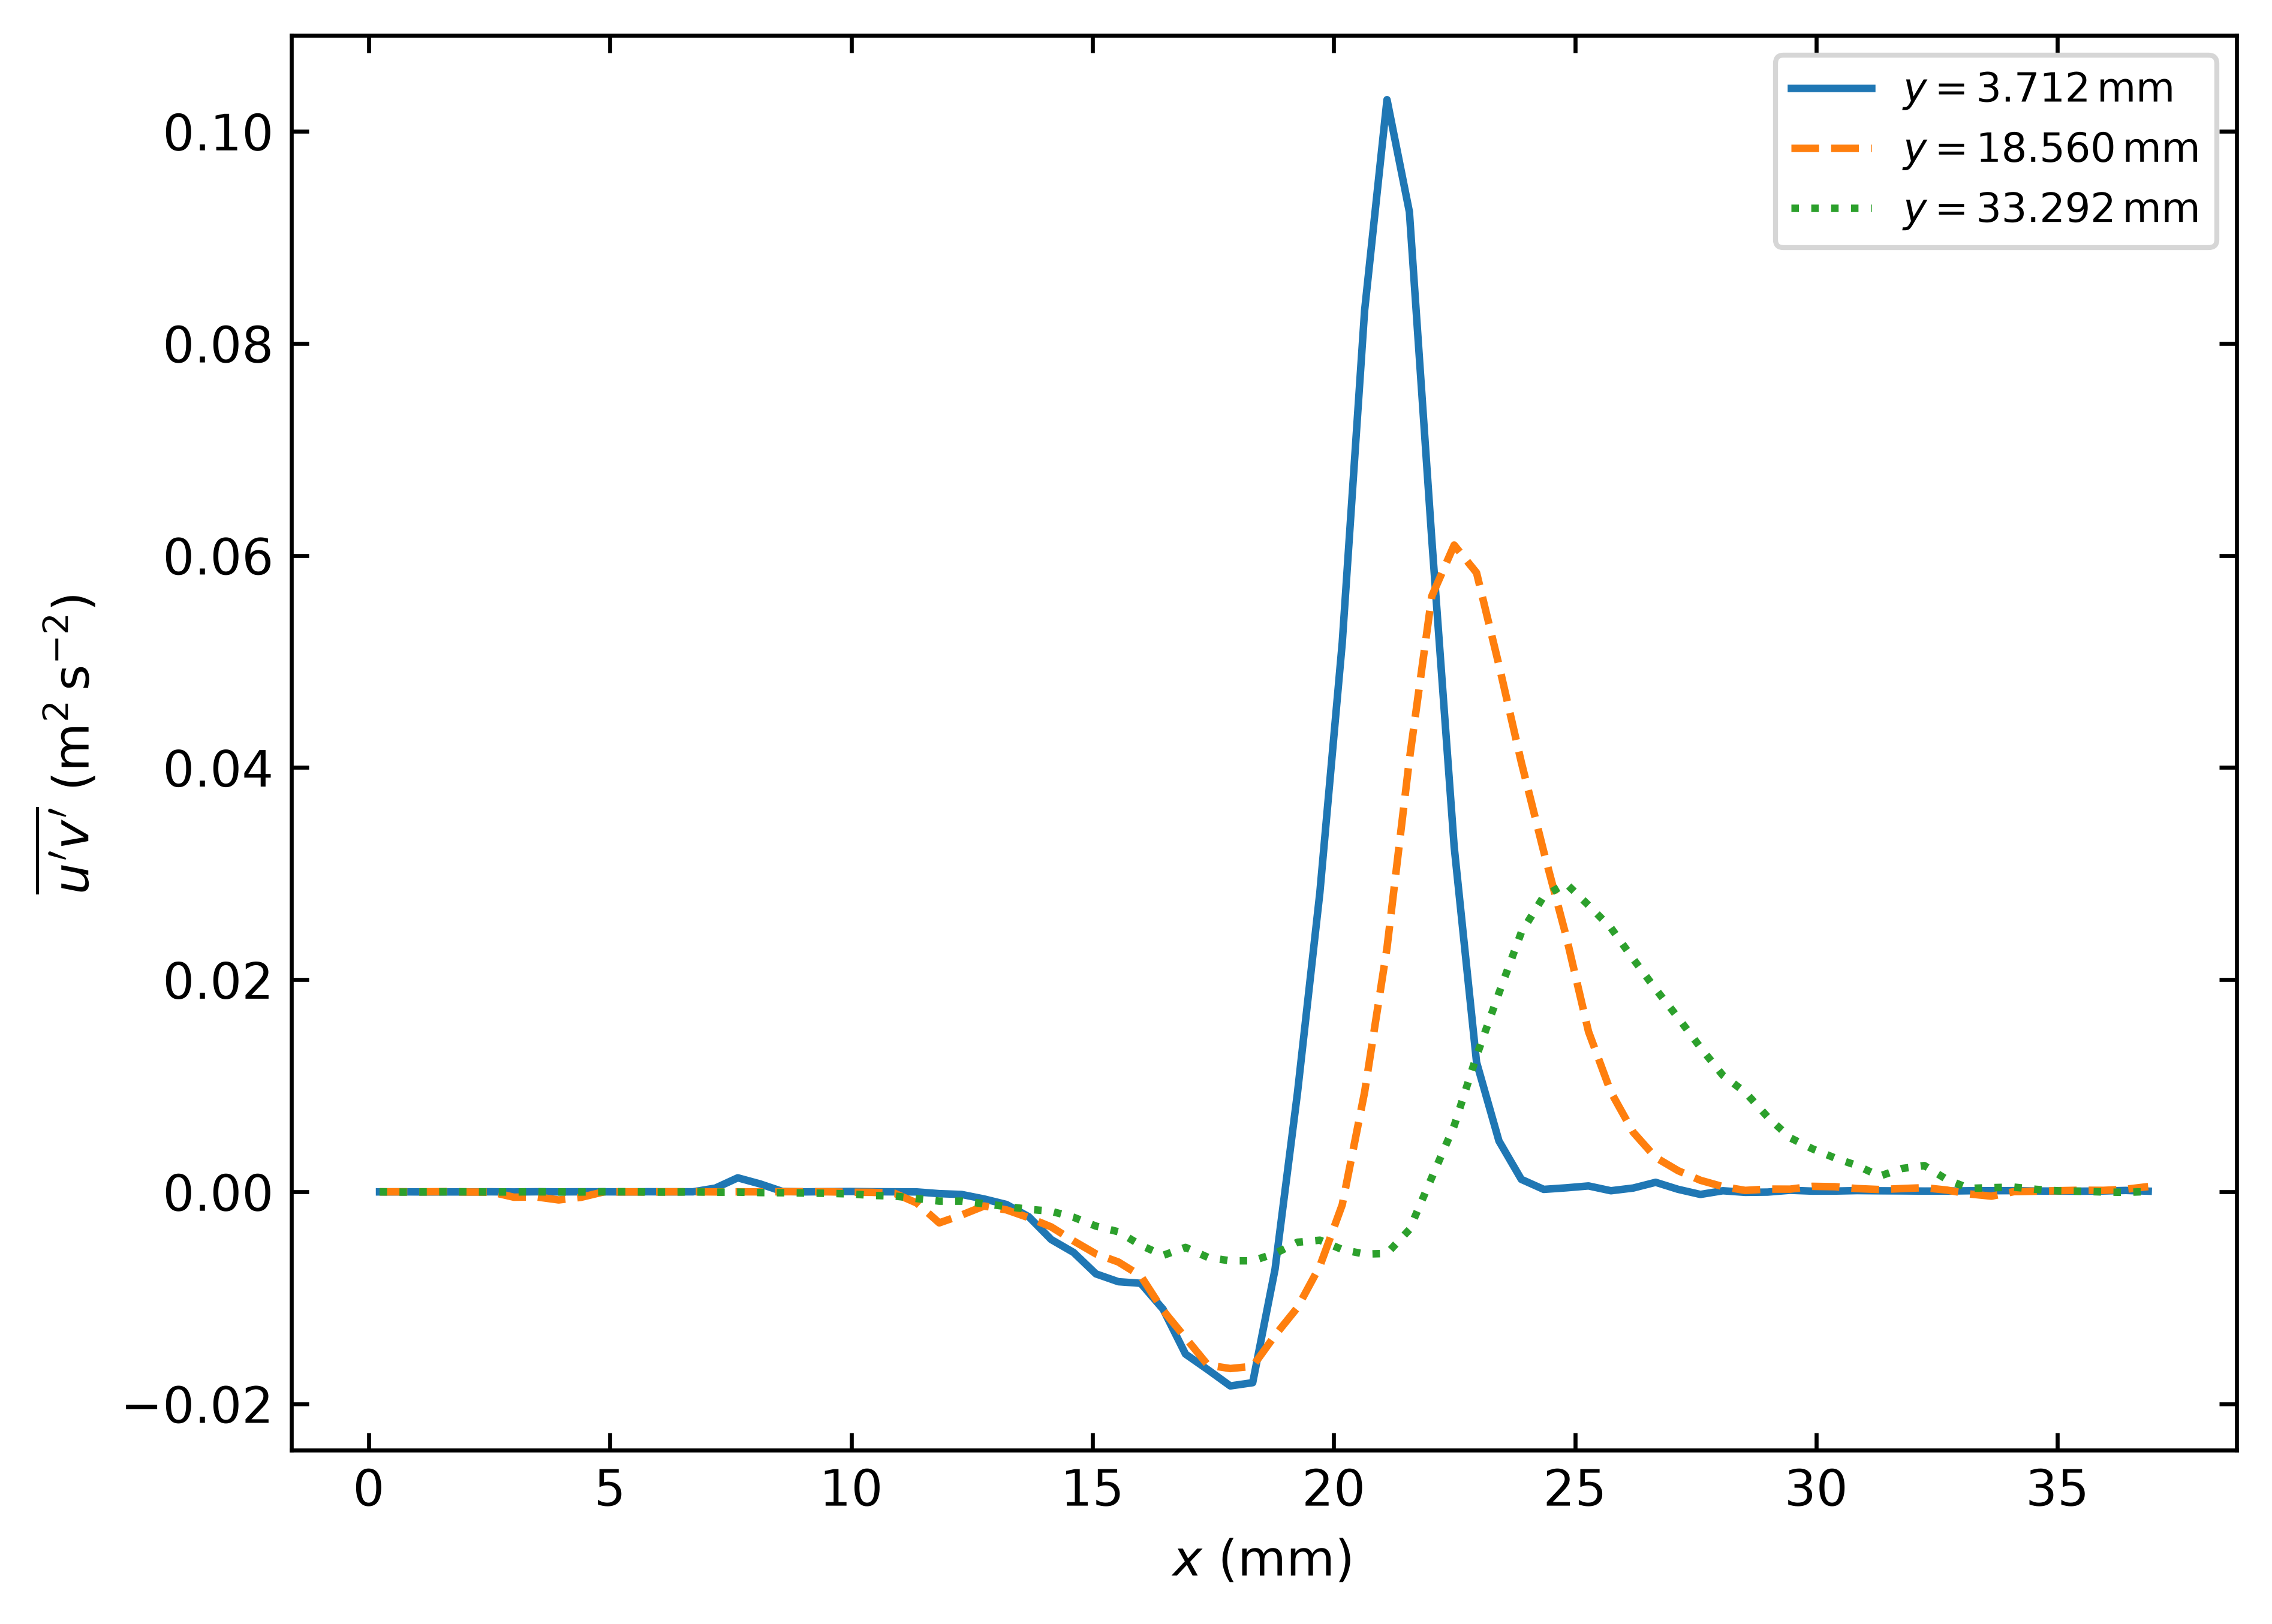

v_pdf


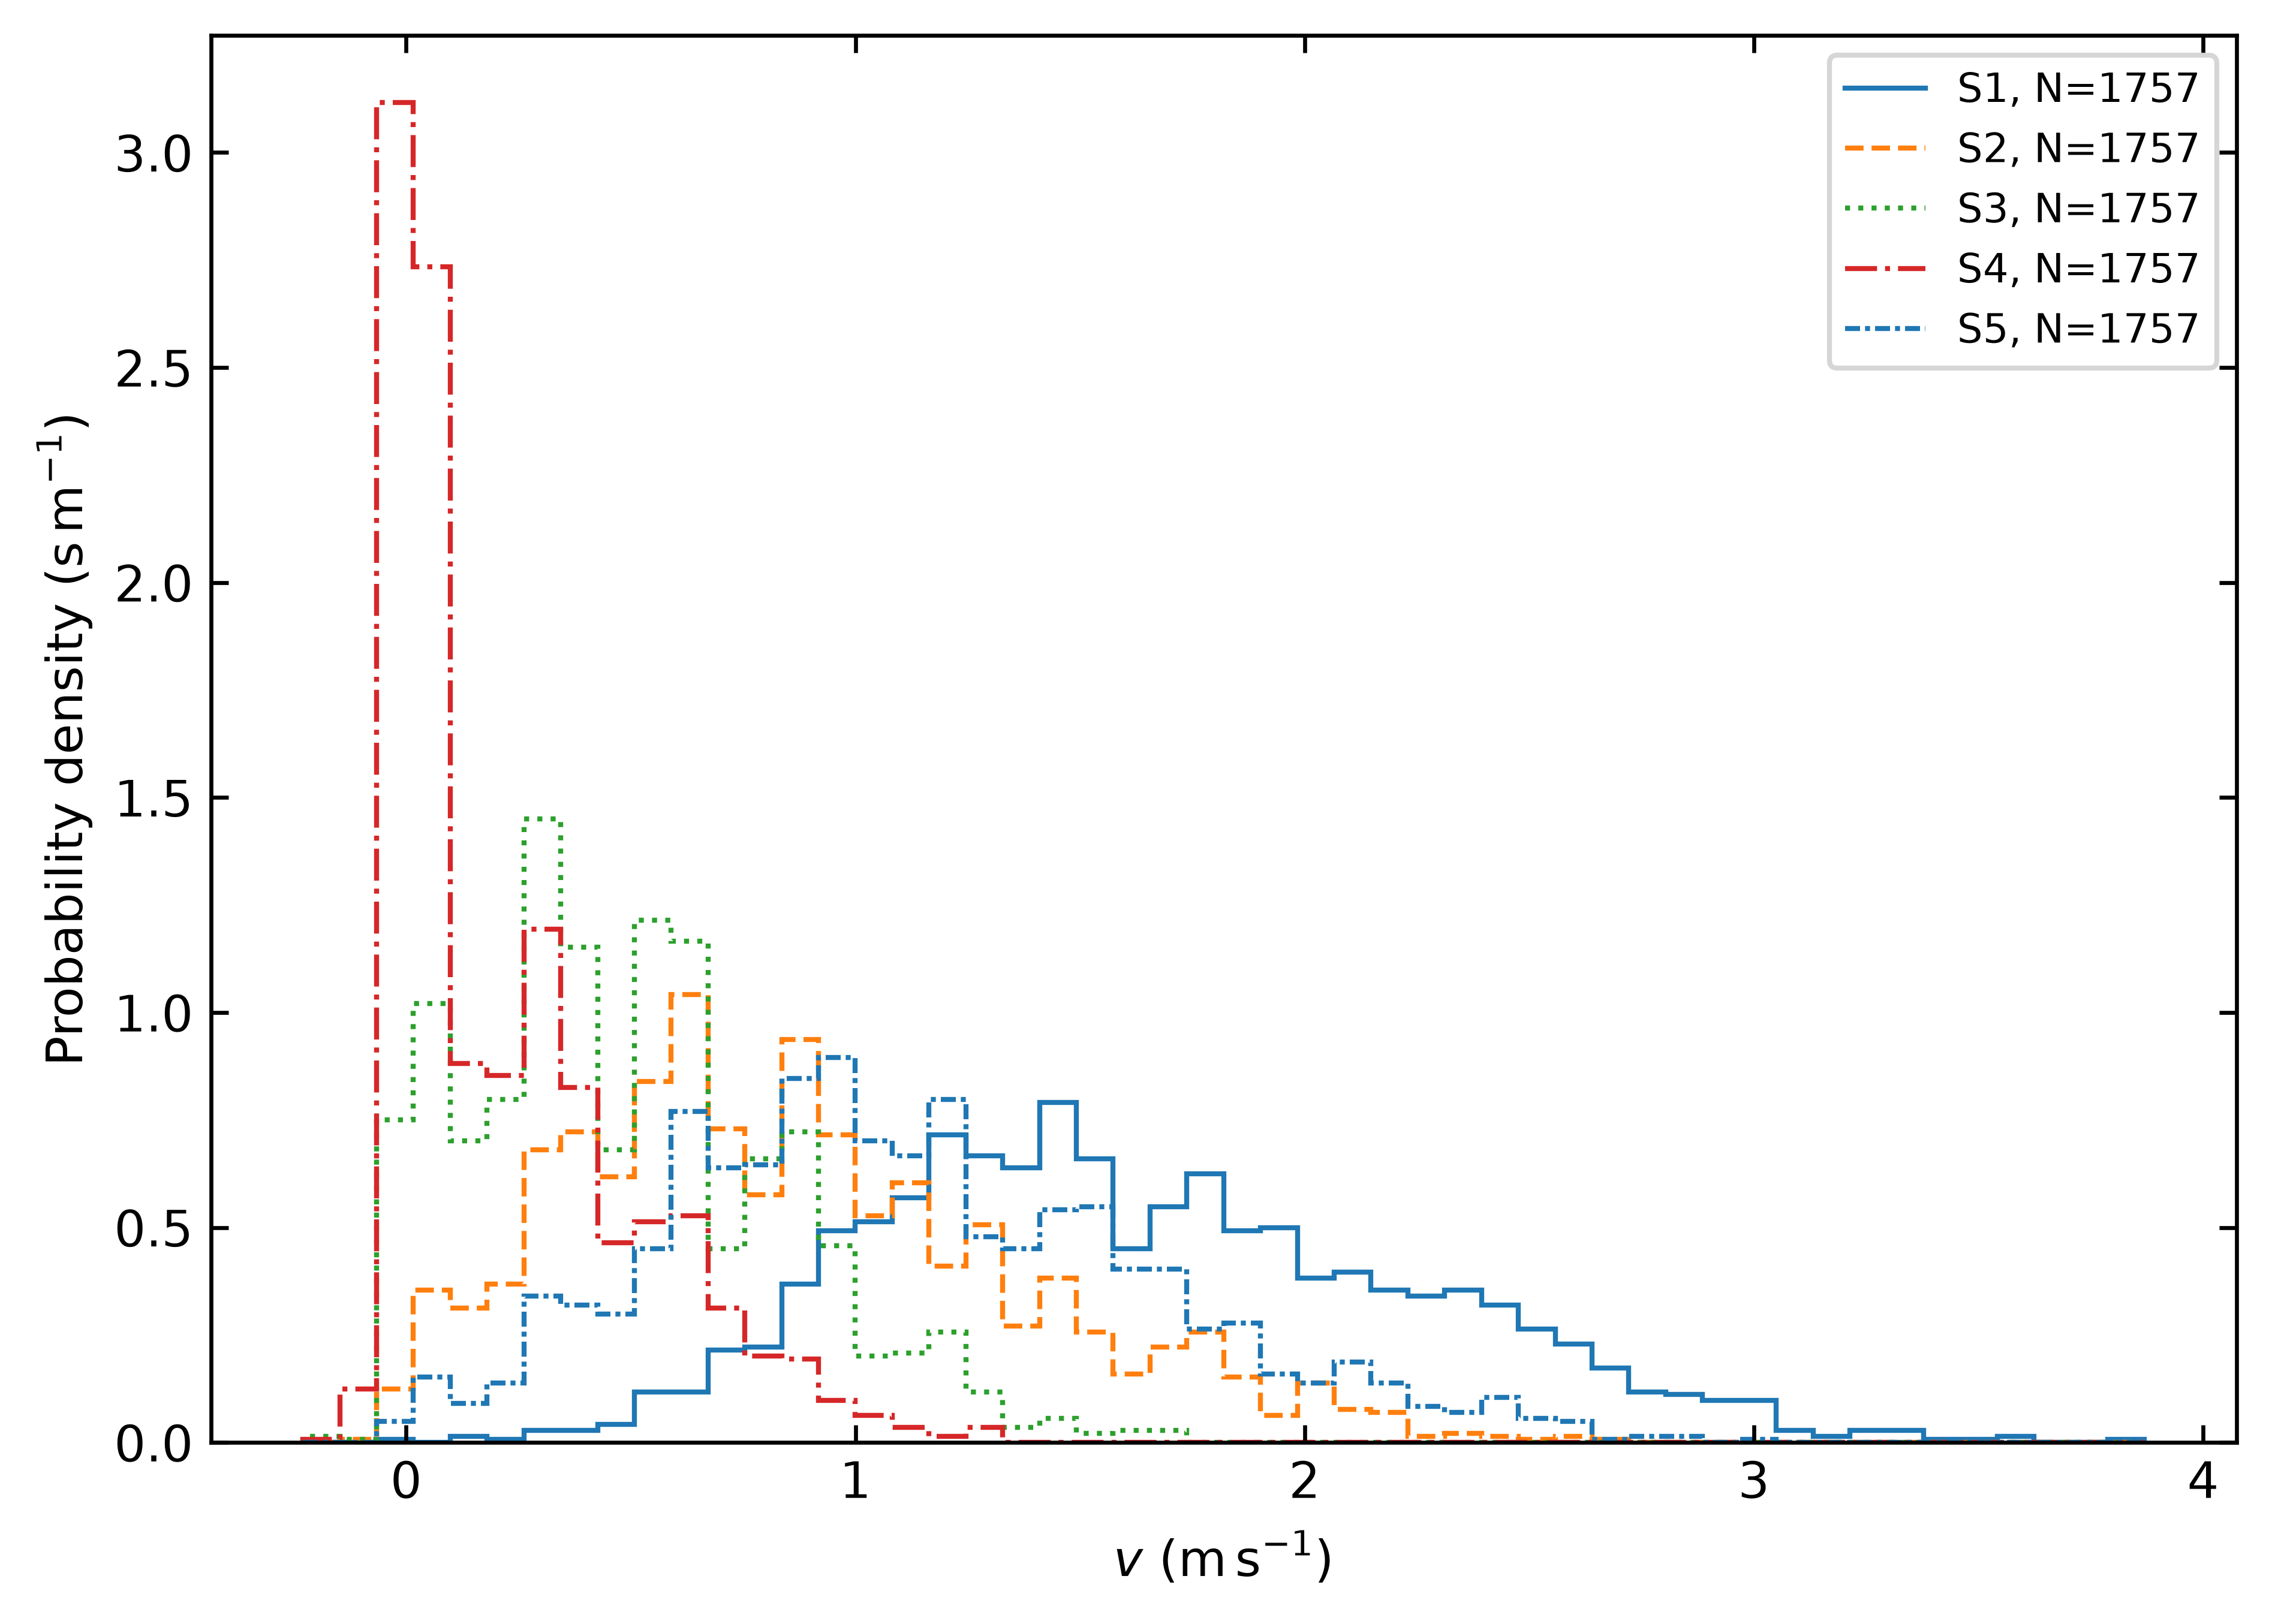

u_pdf


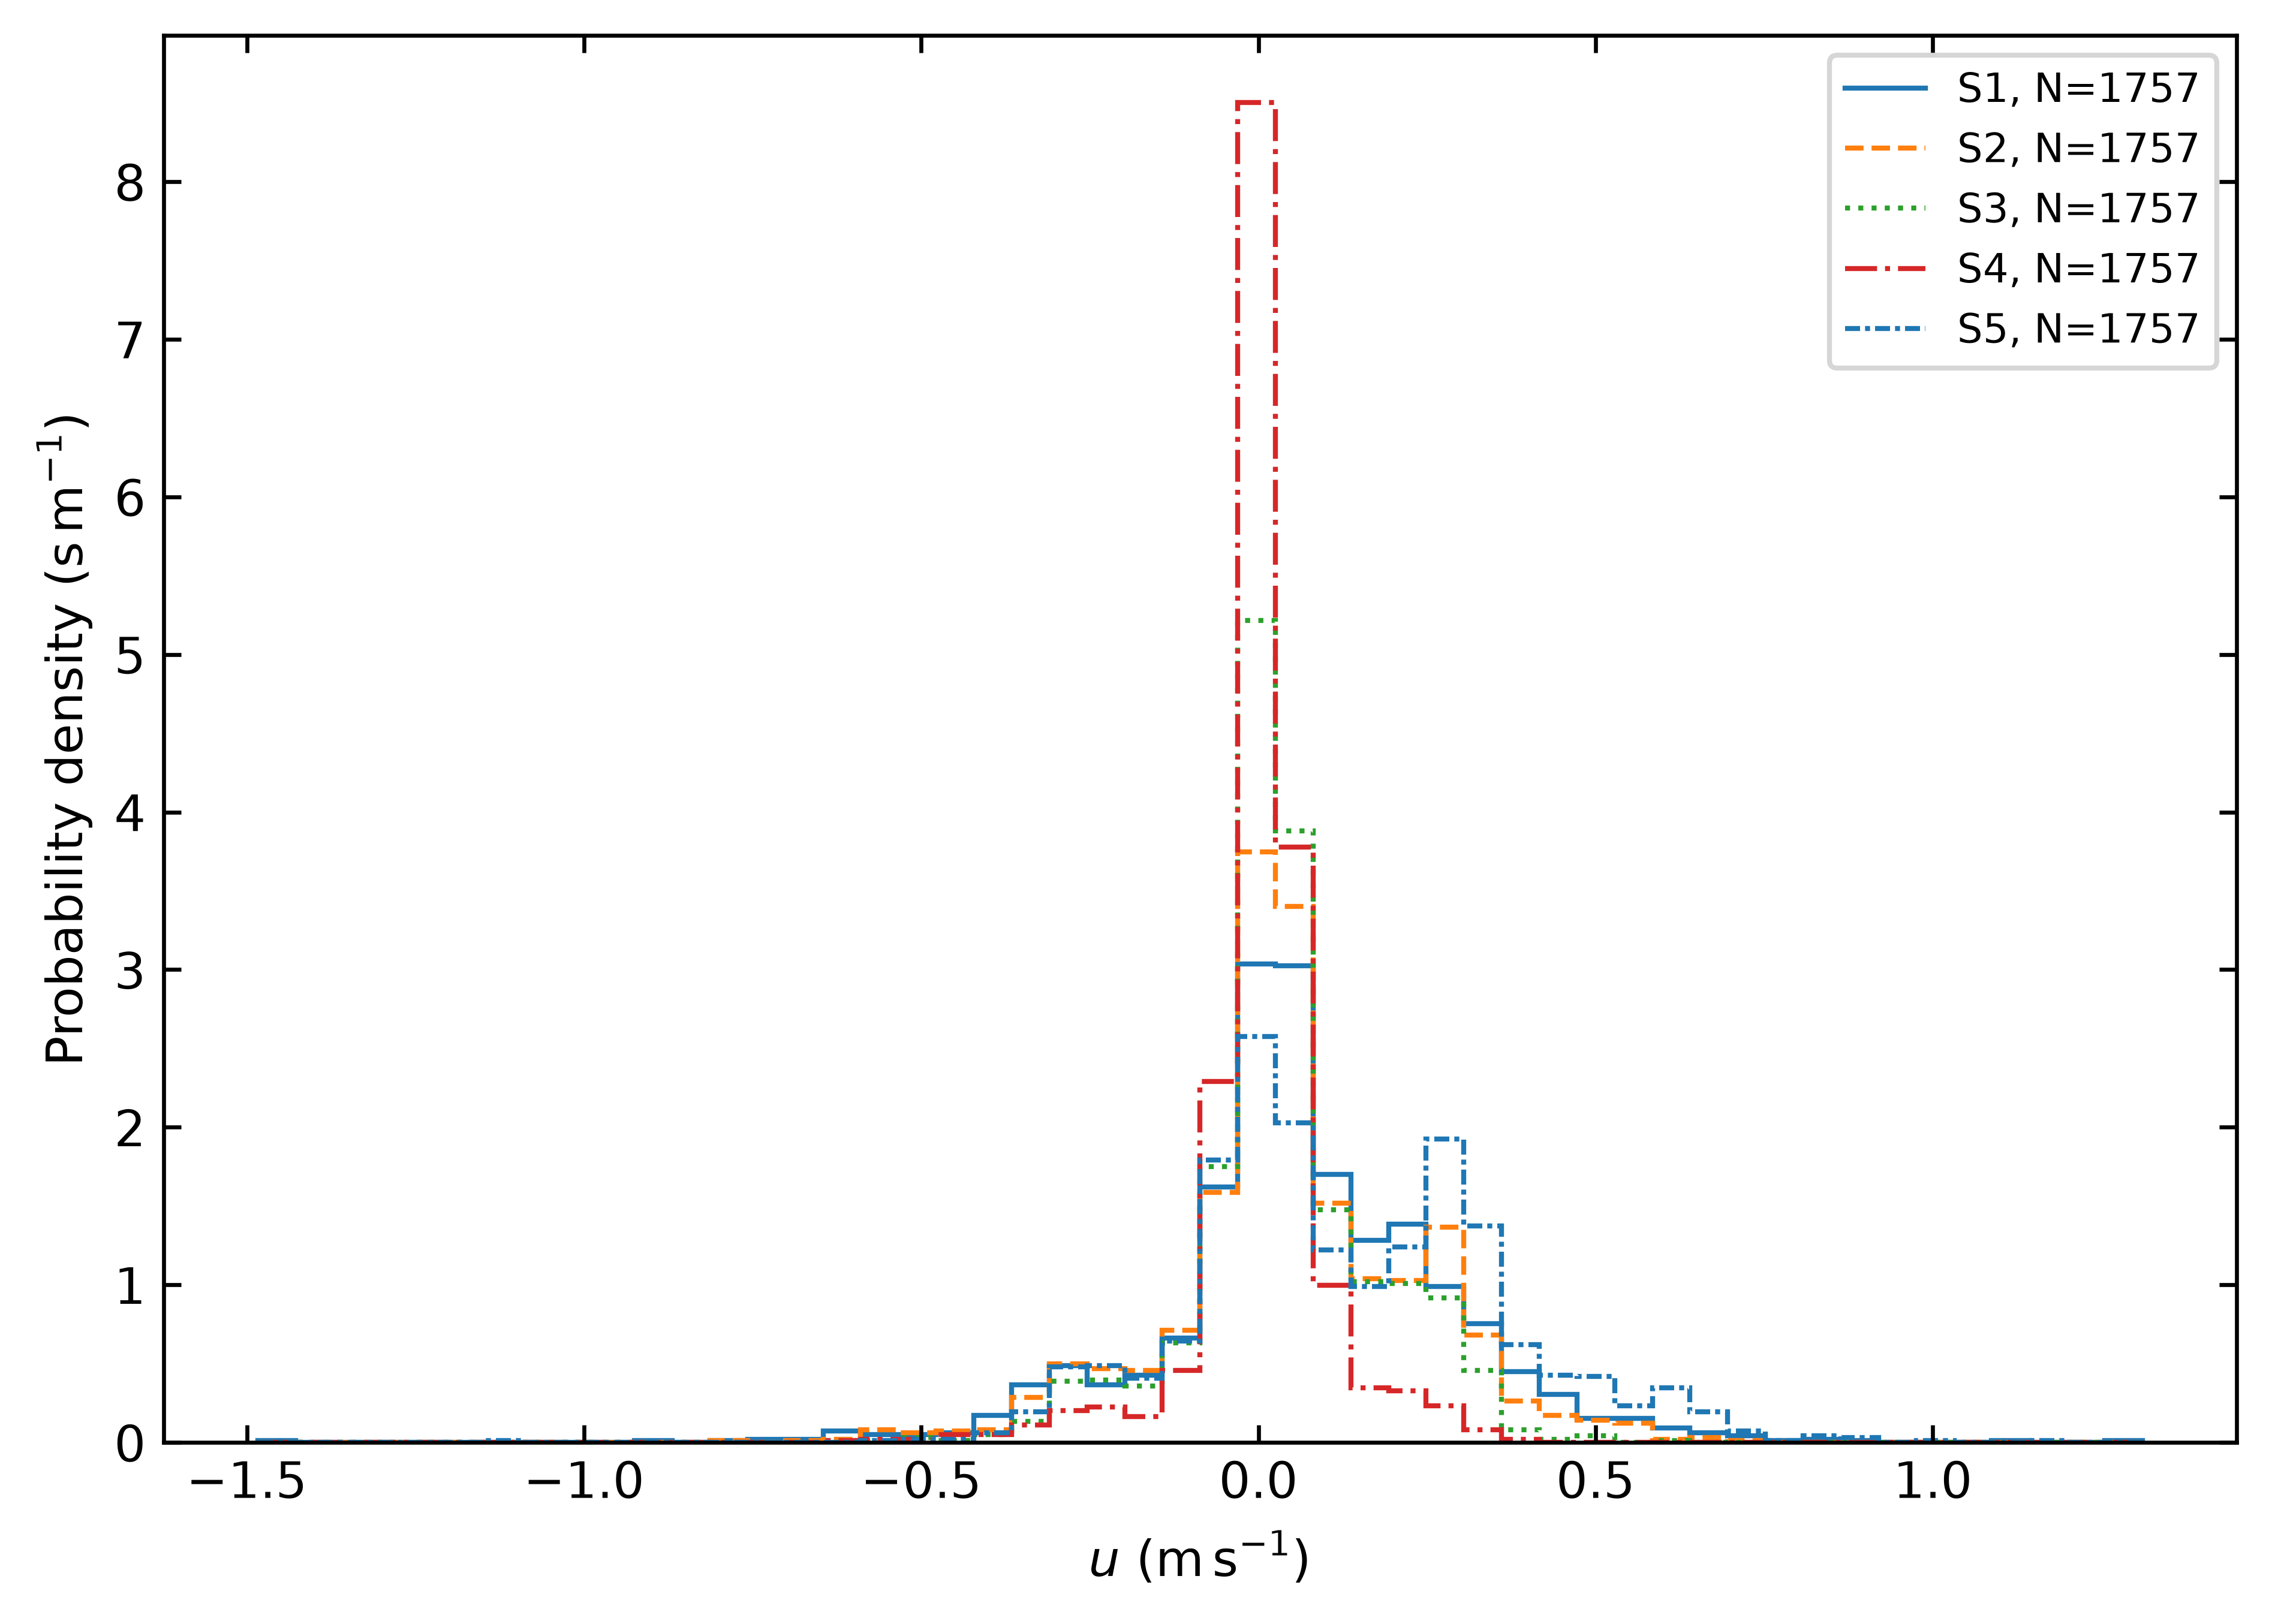

v_cdf


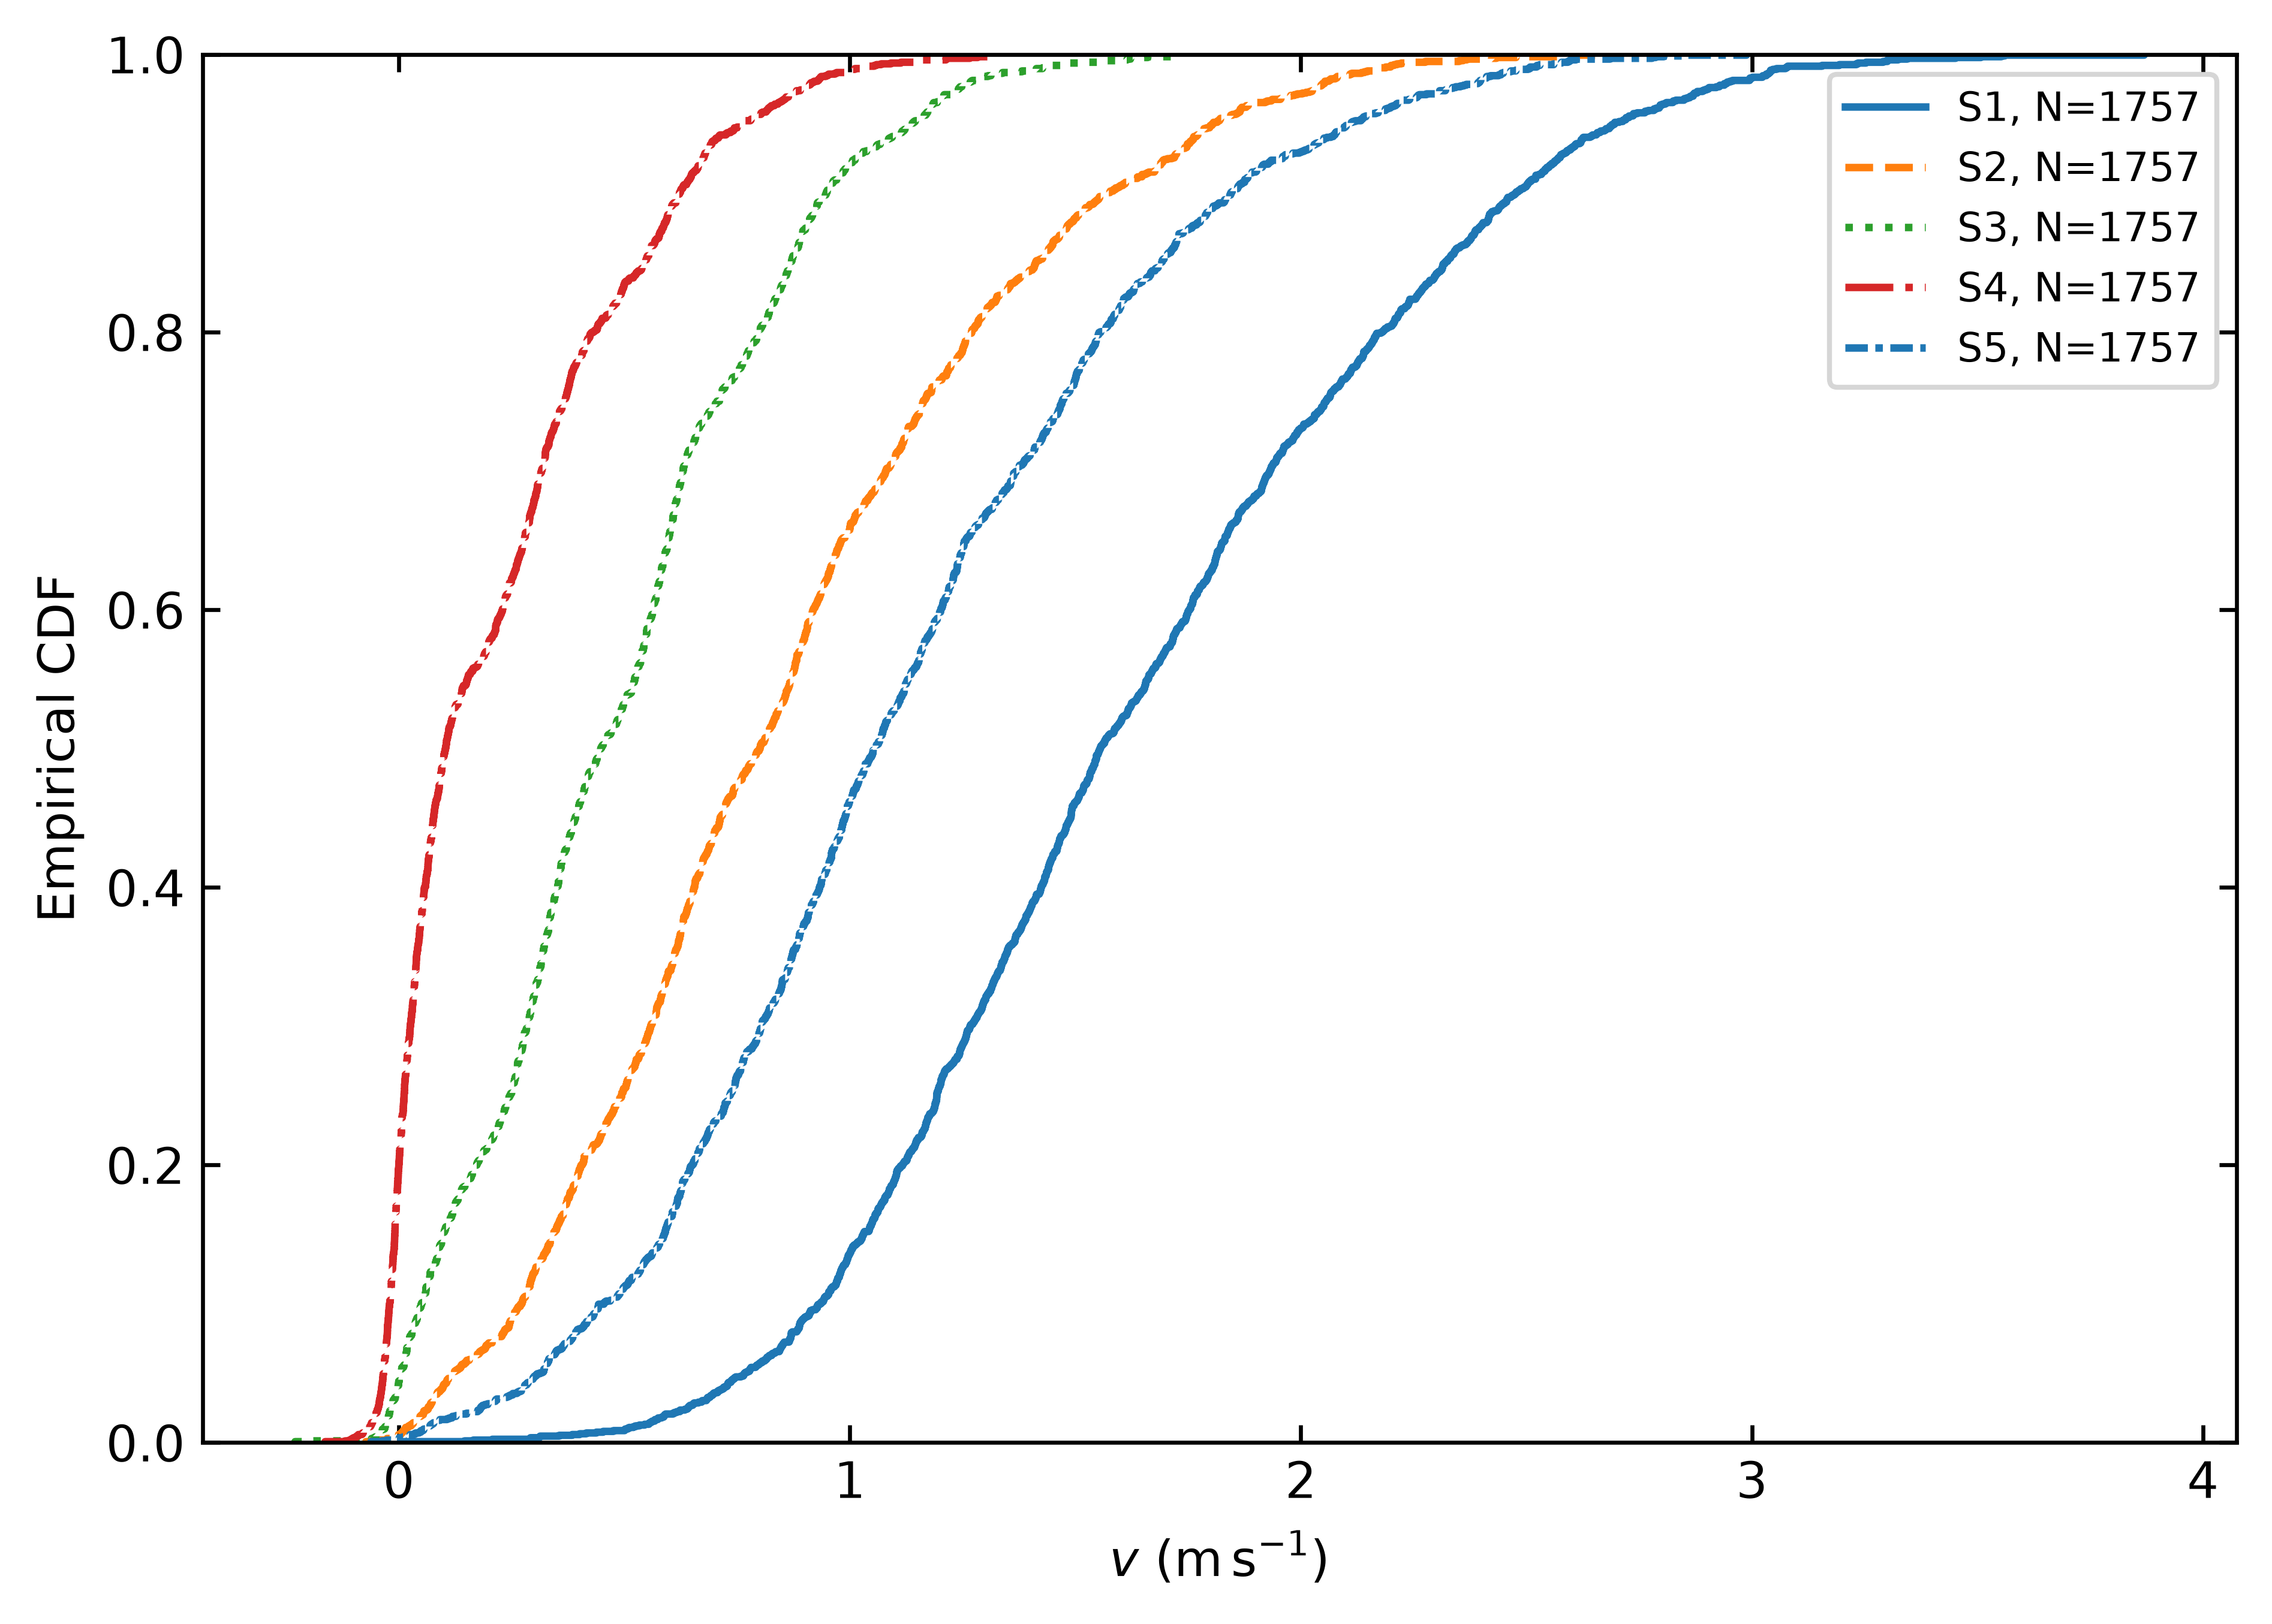

u_cdf


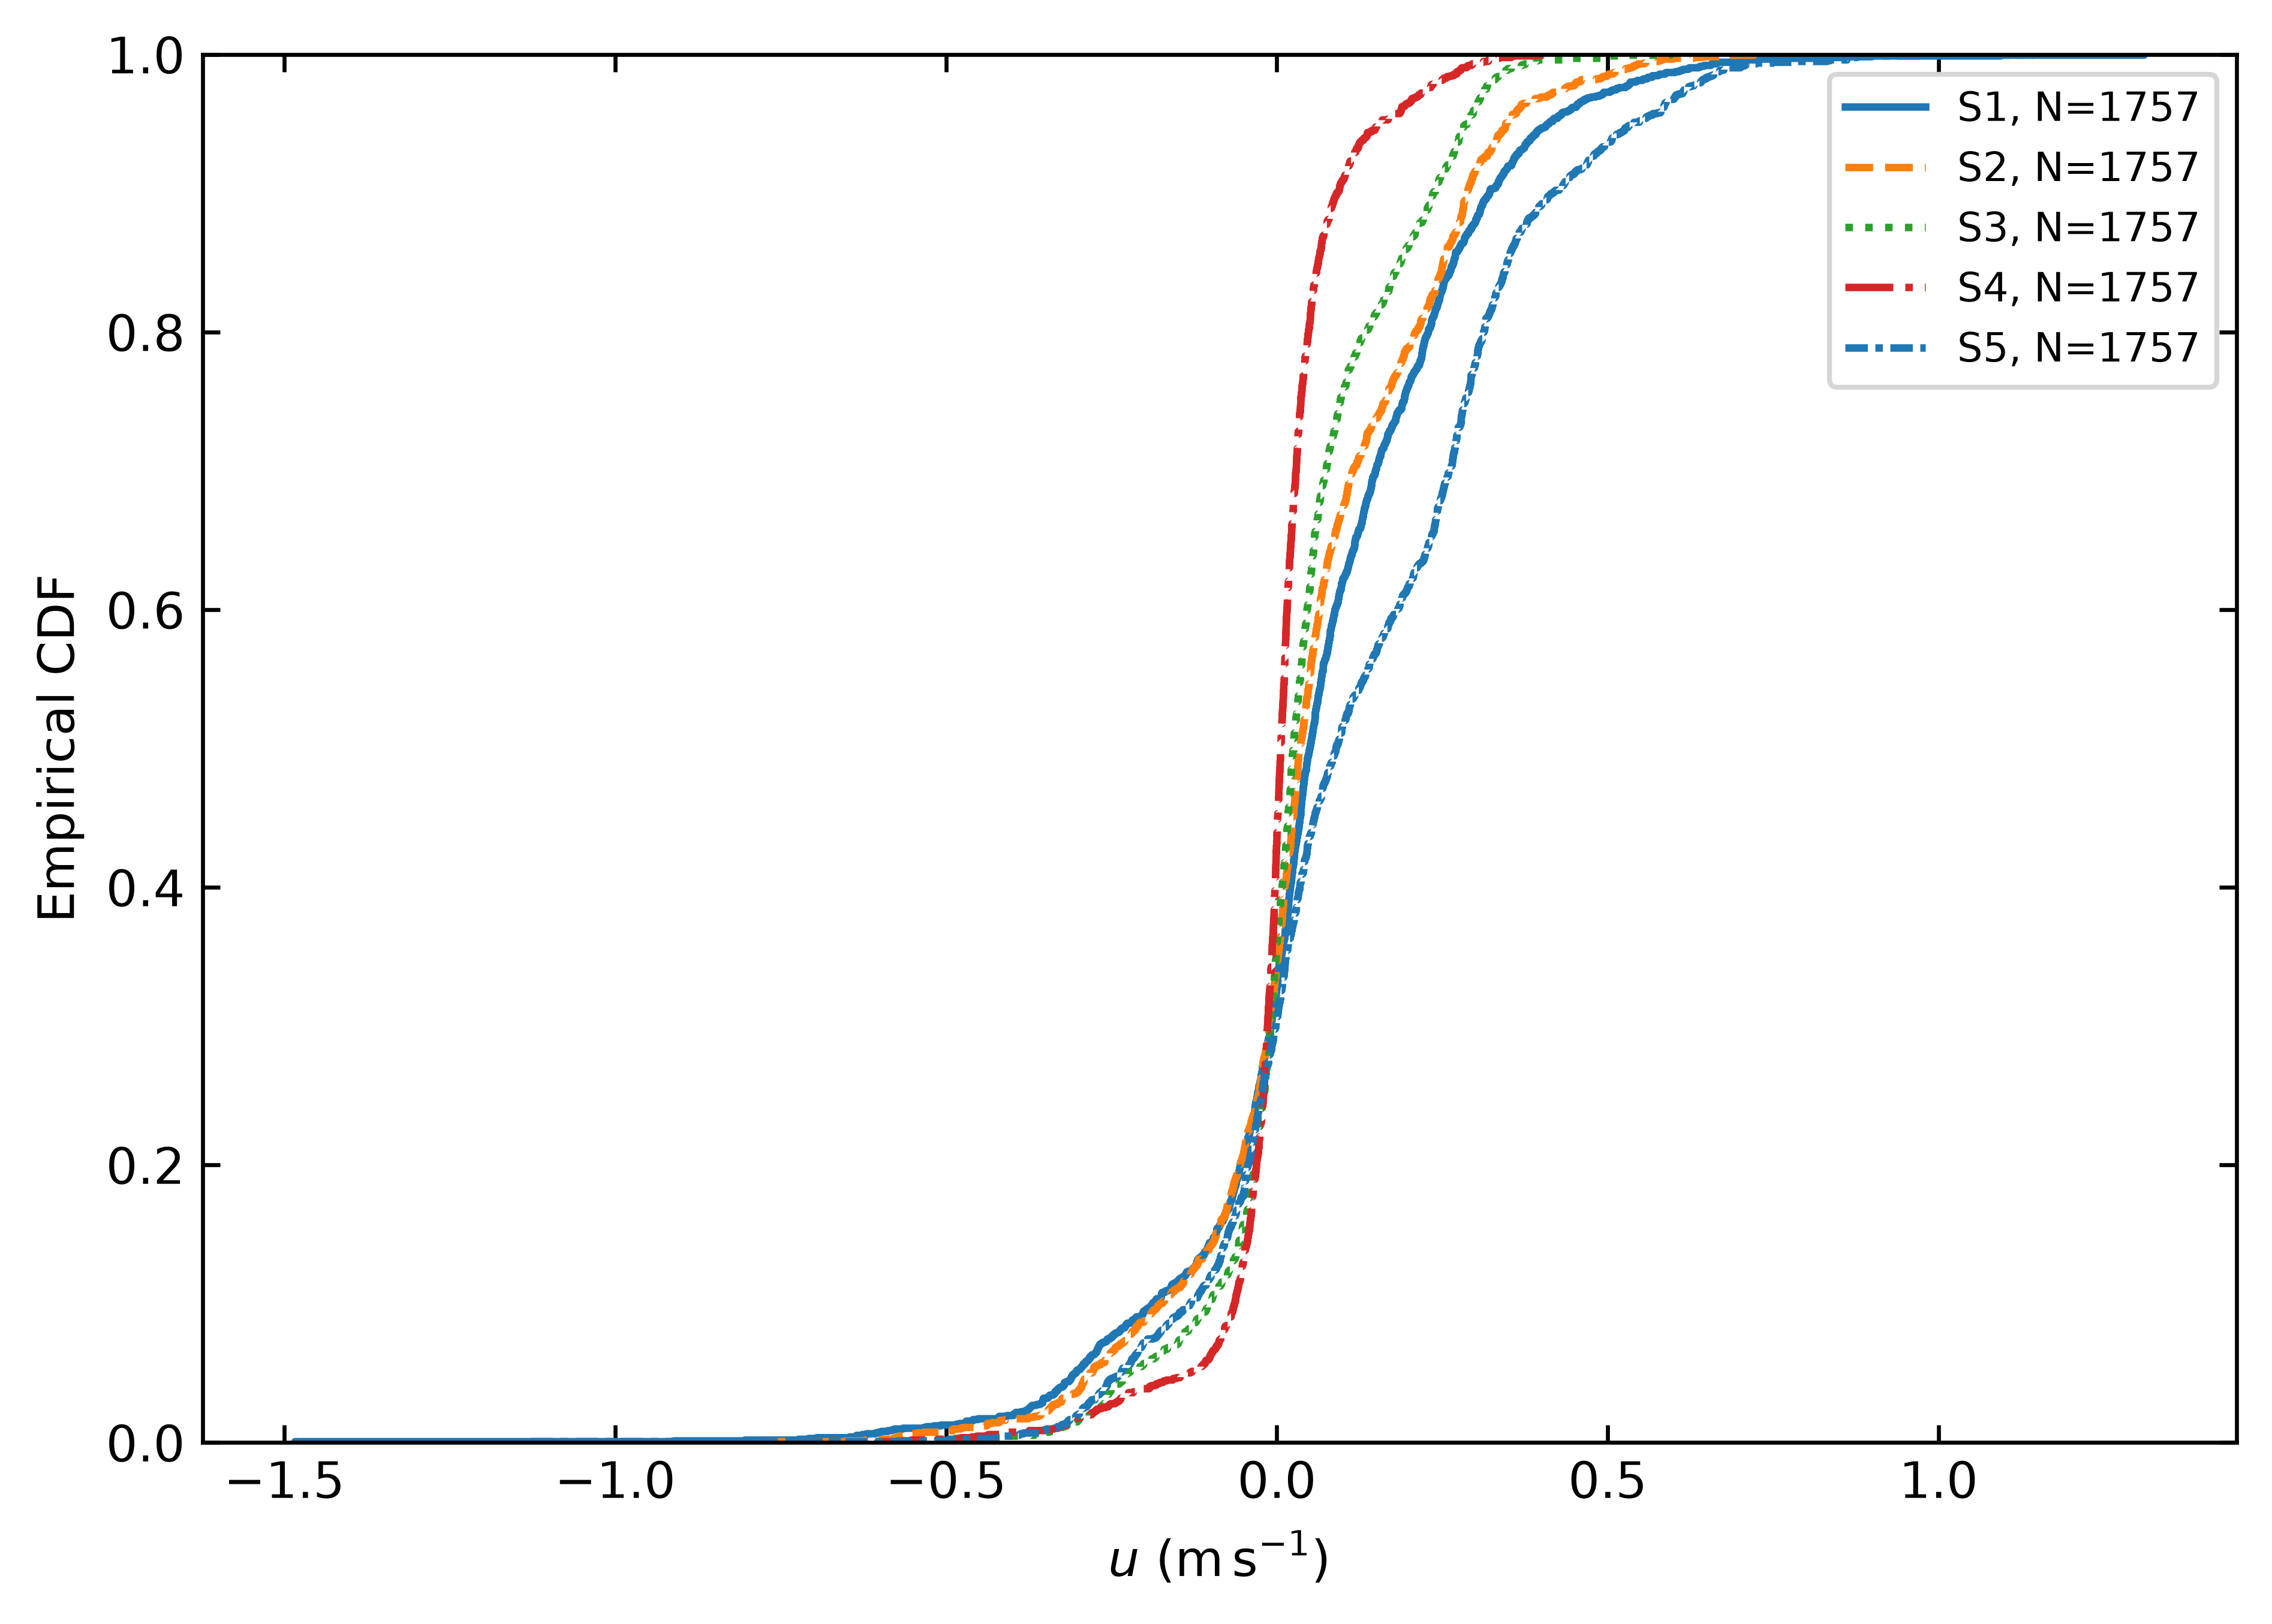

frame_879_v


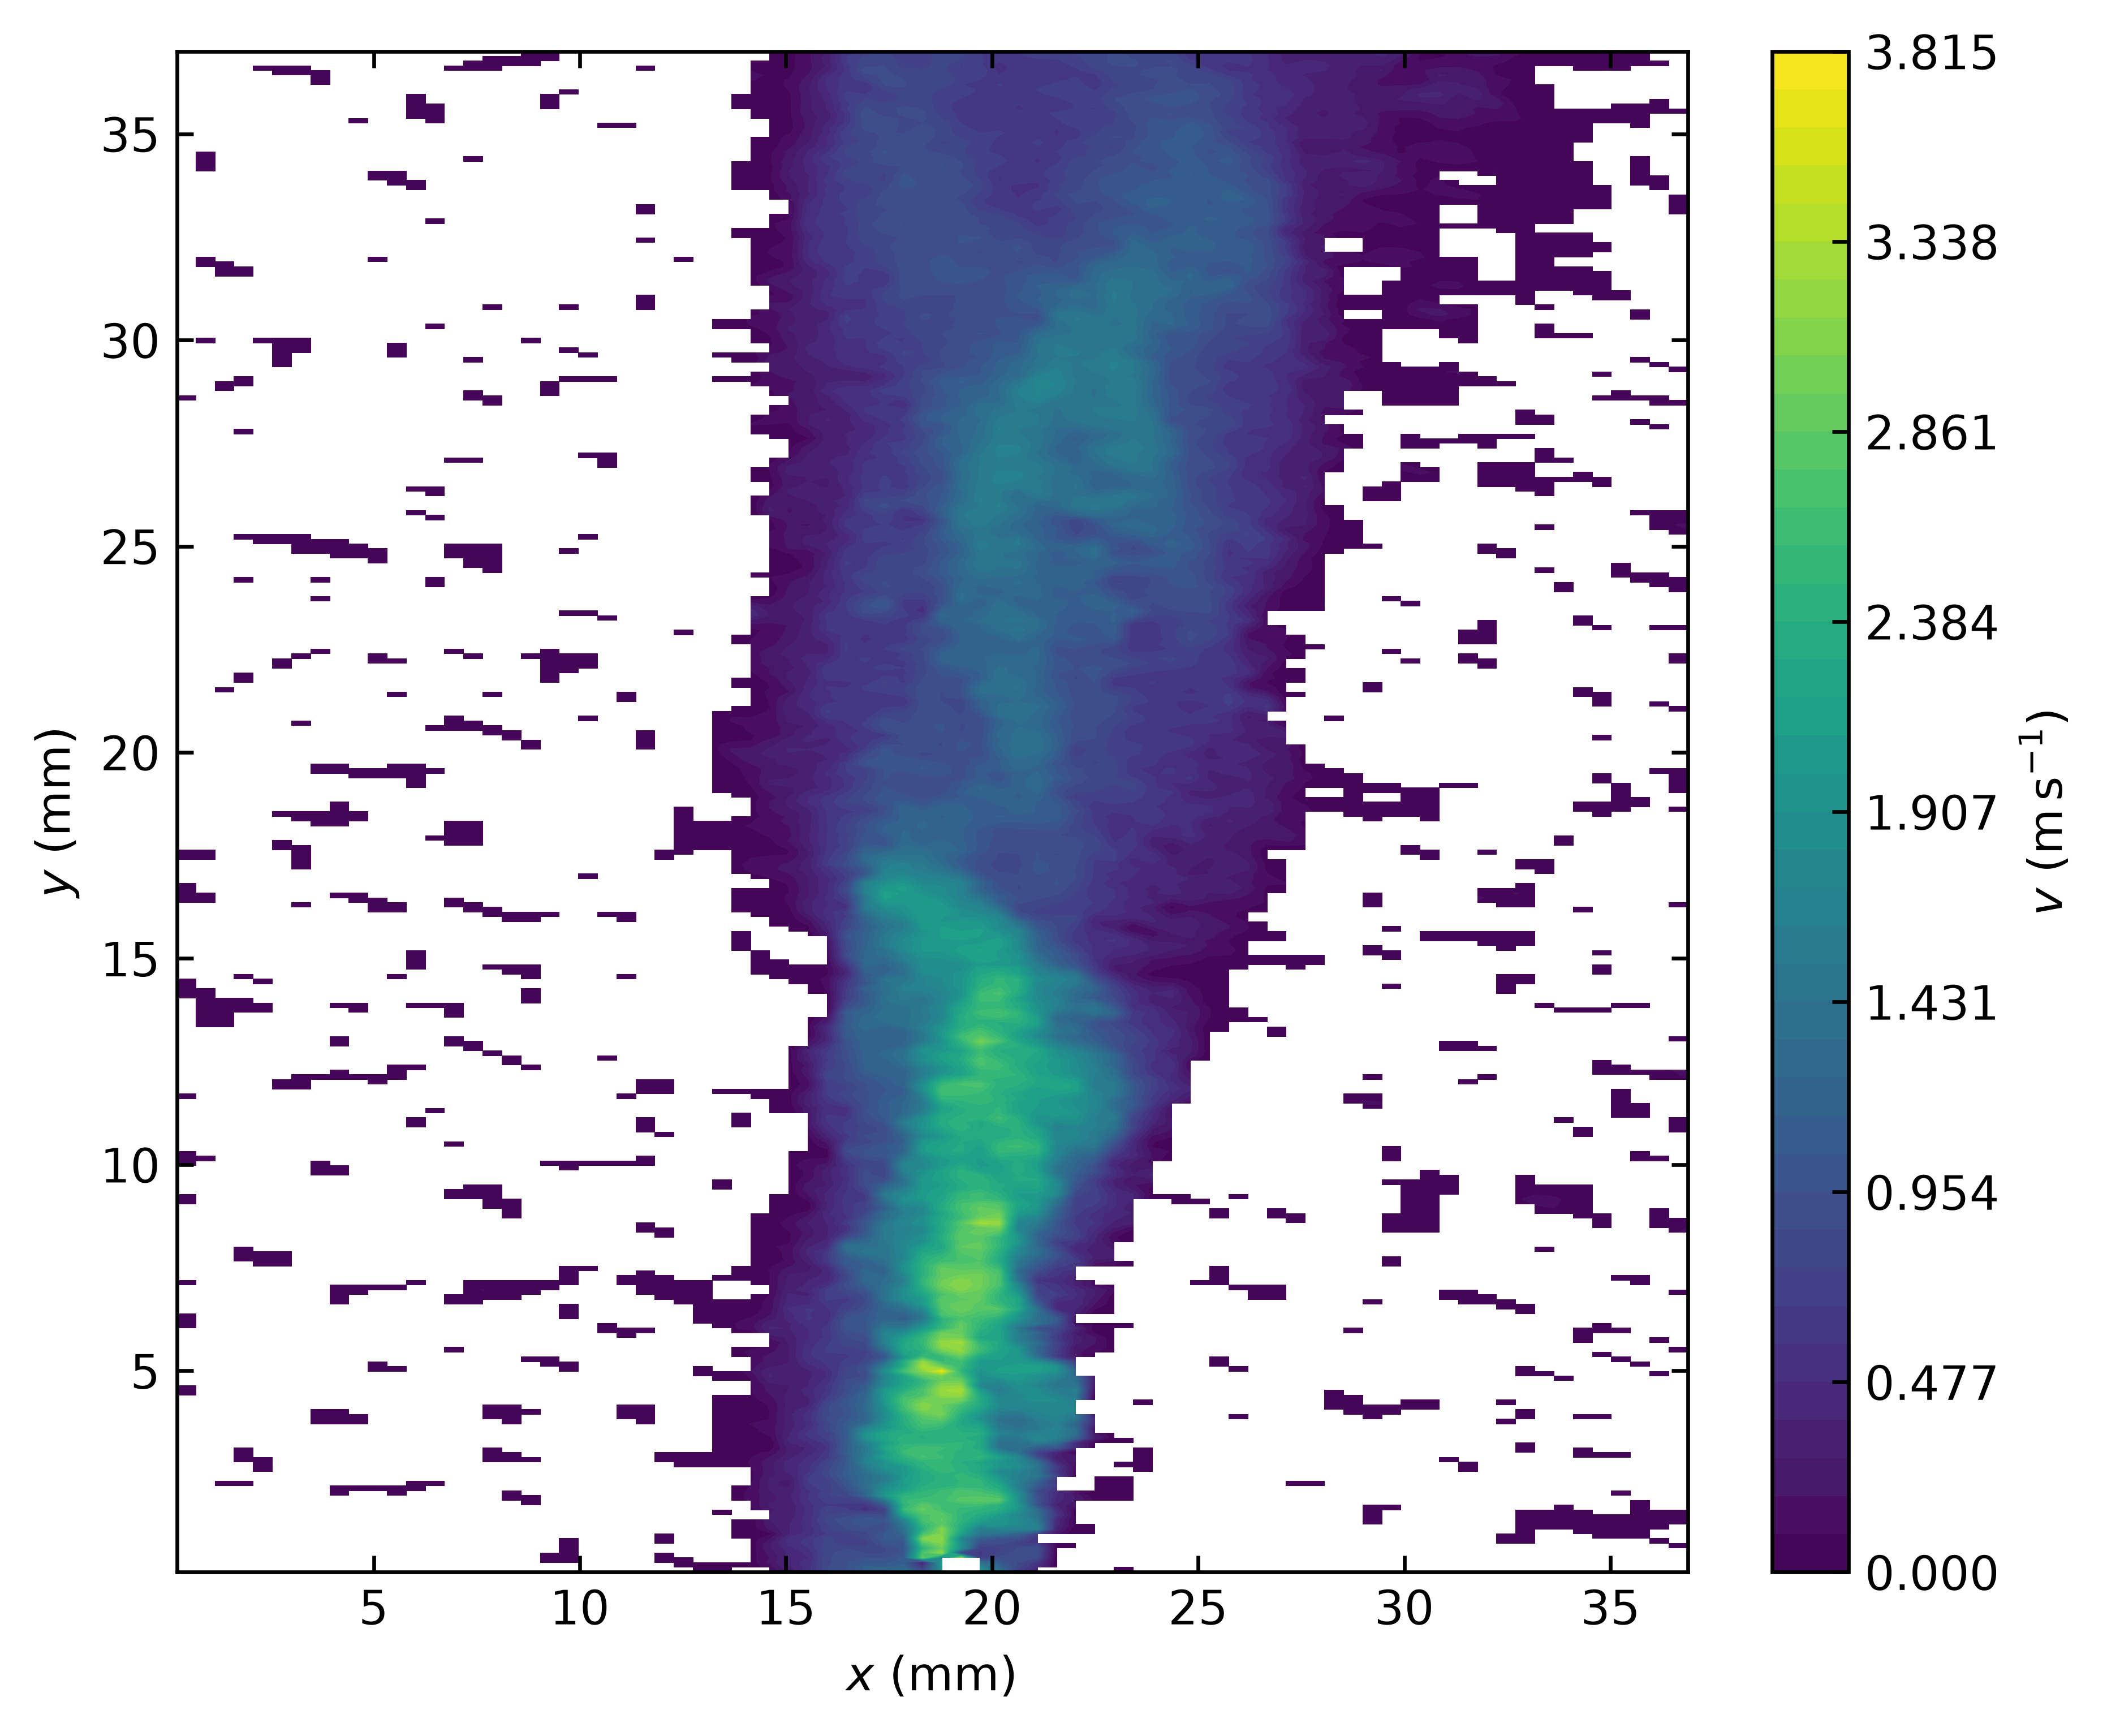

frame_879_u


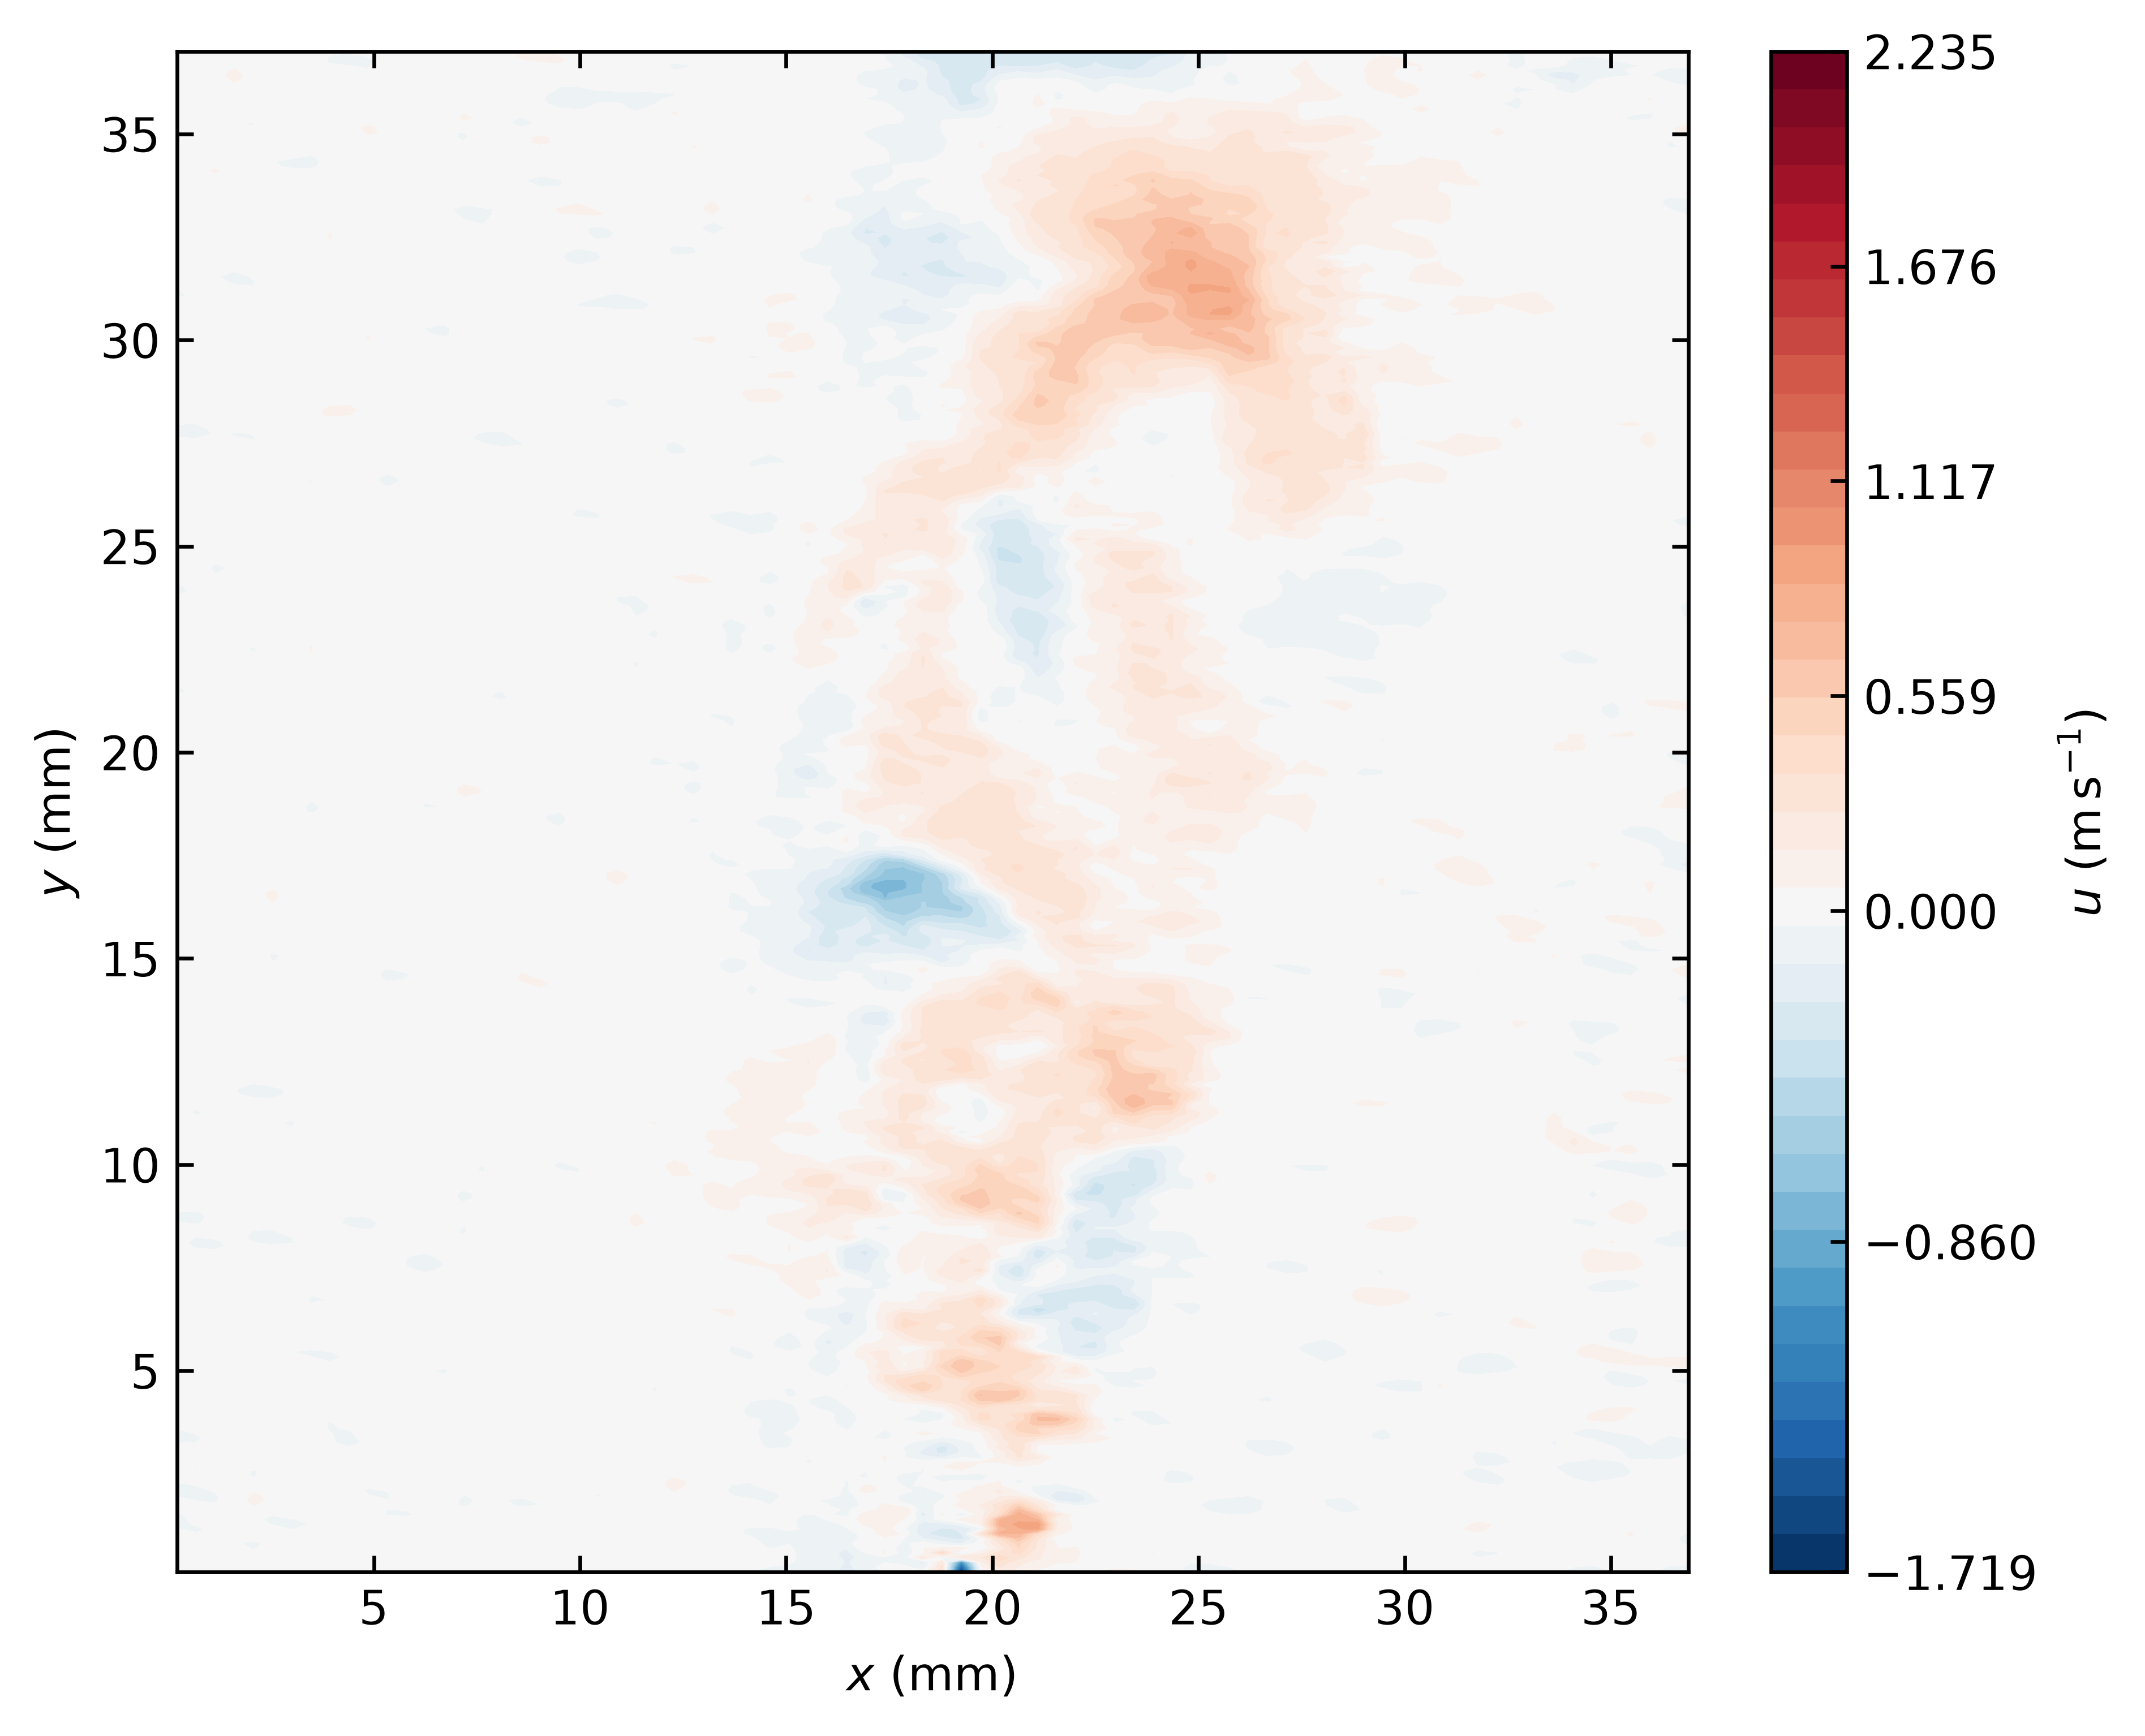

frame_879_quiver


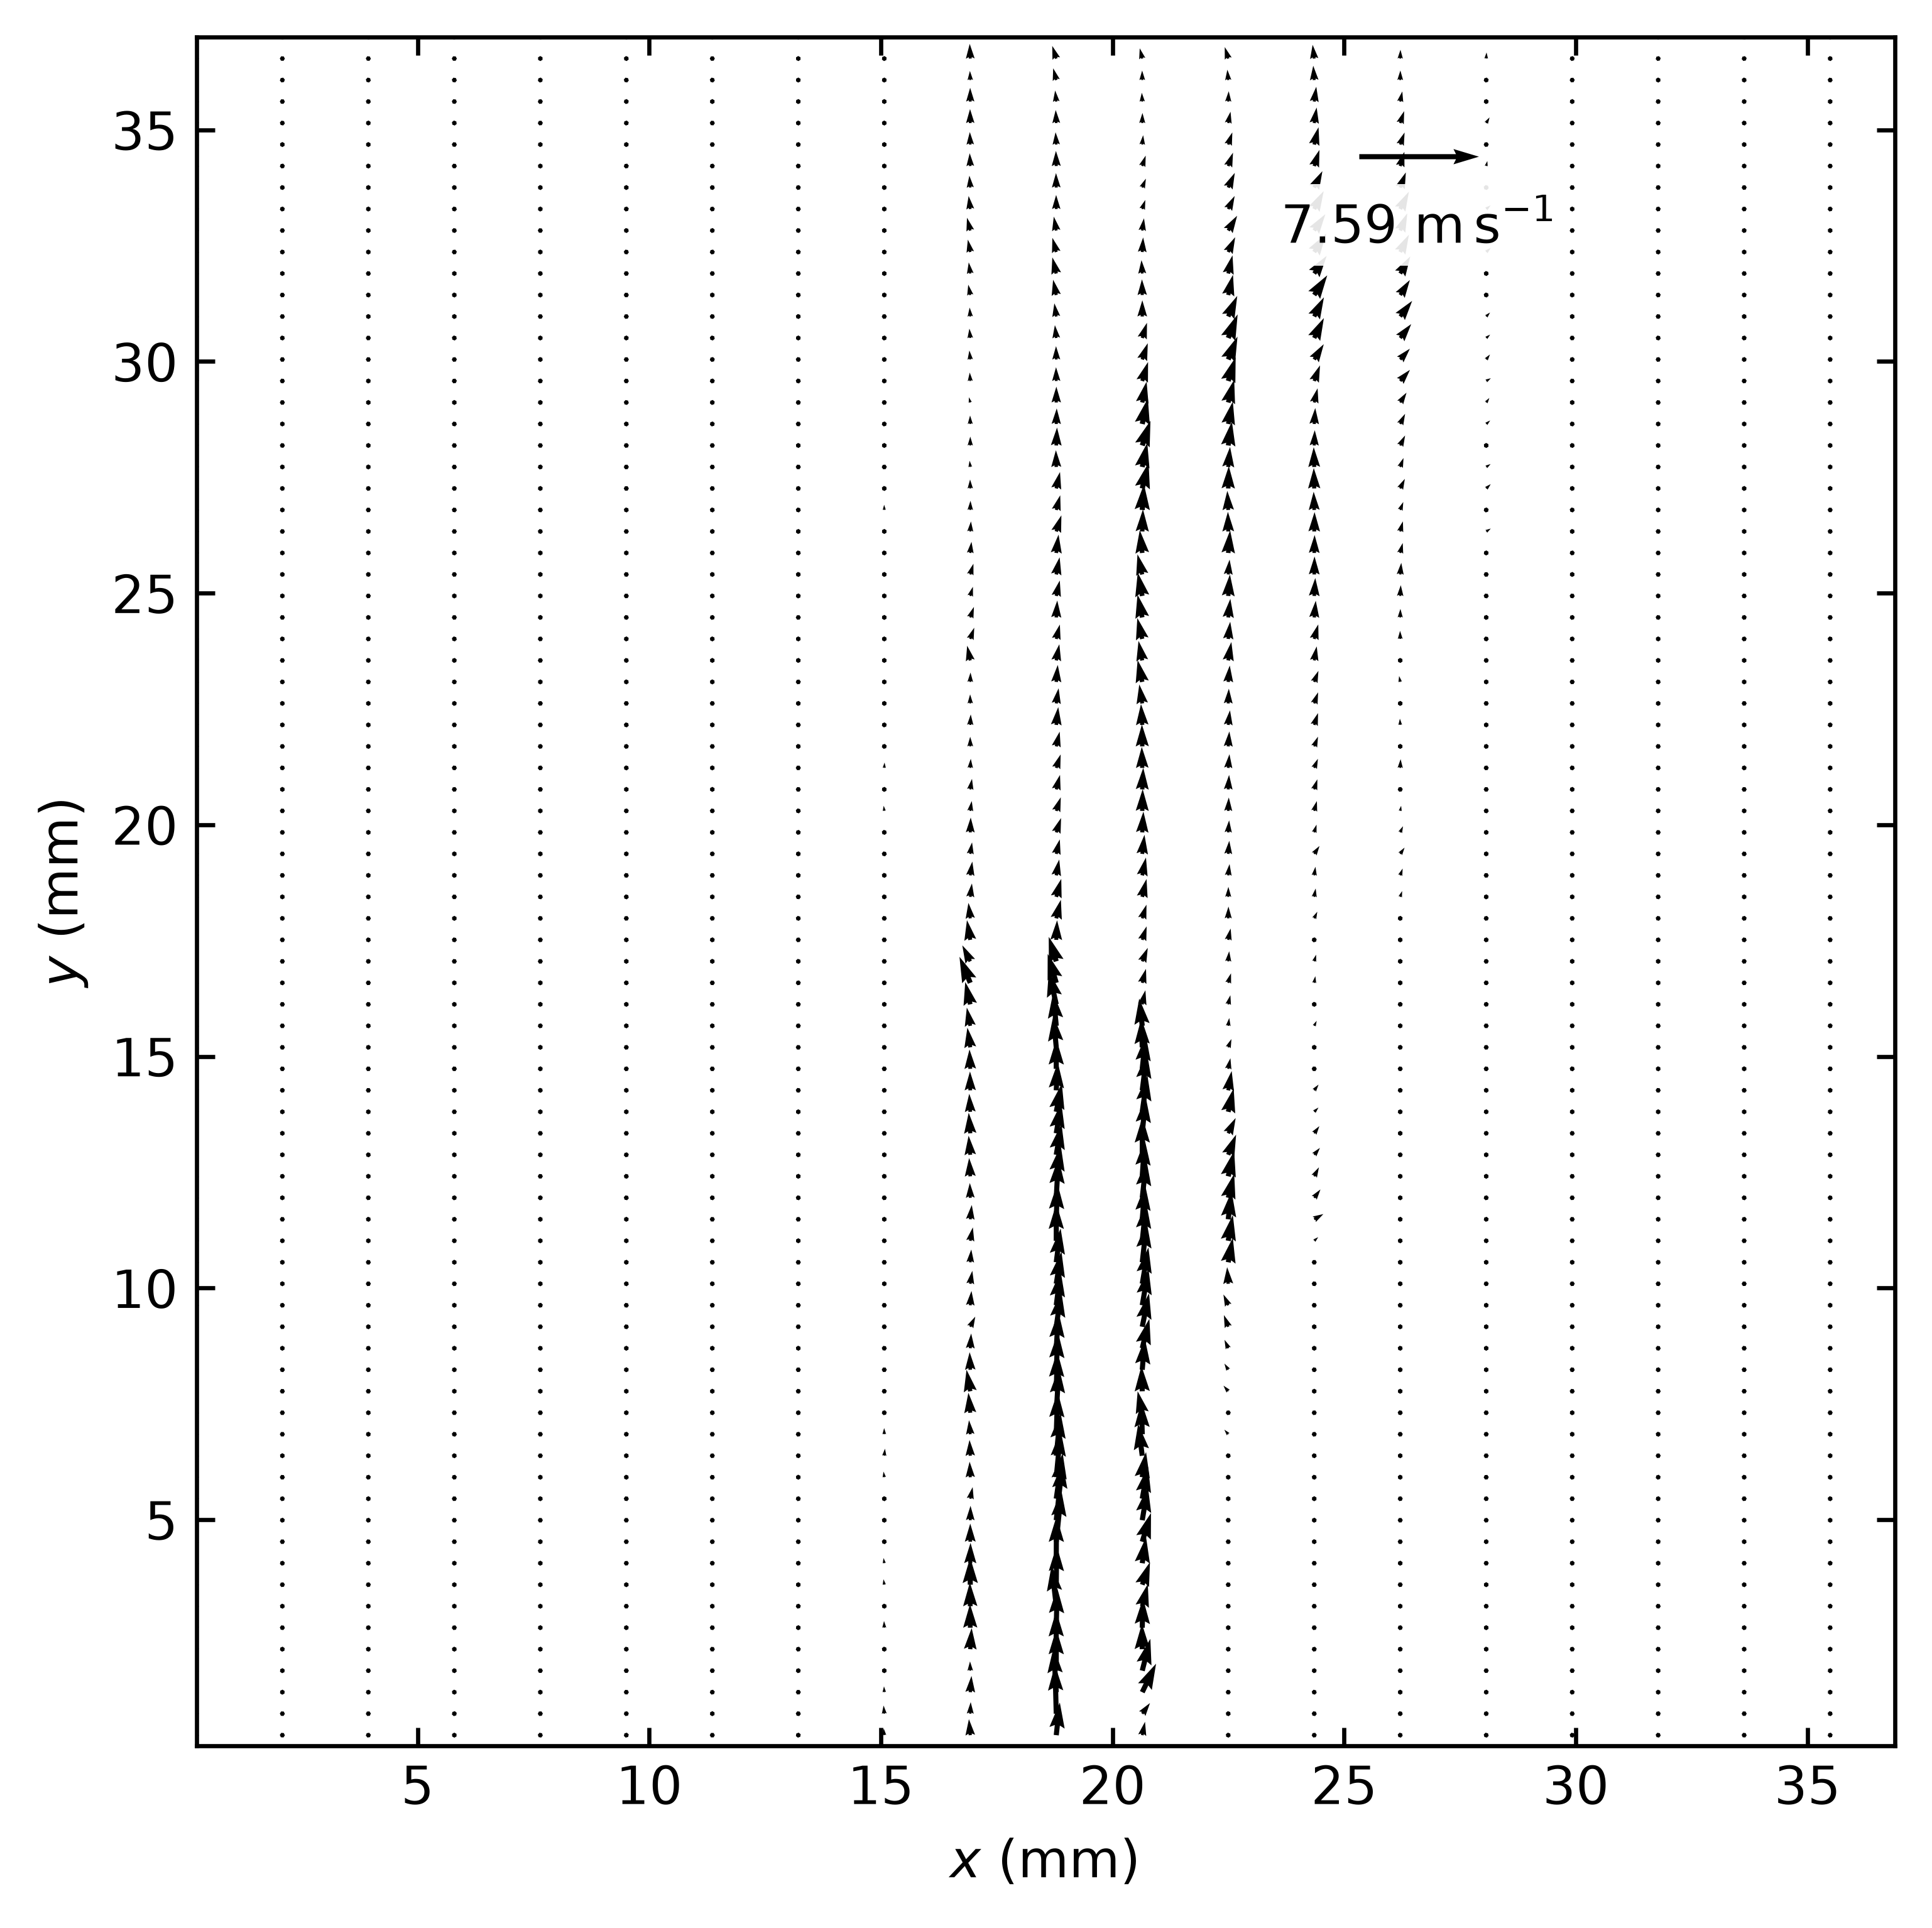

## Supplementary in-plane velocity magnitude

magnitude_mean_vector


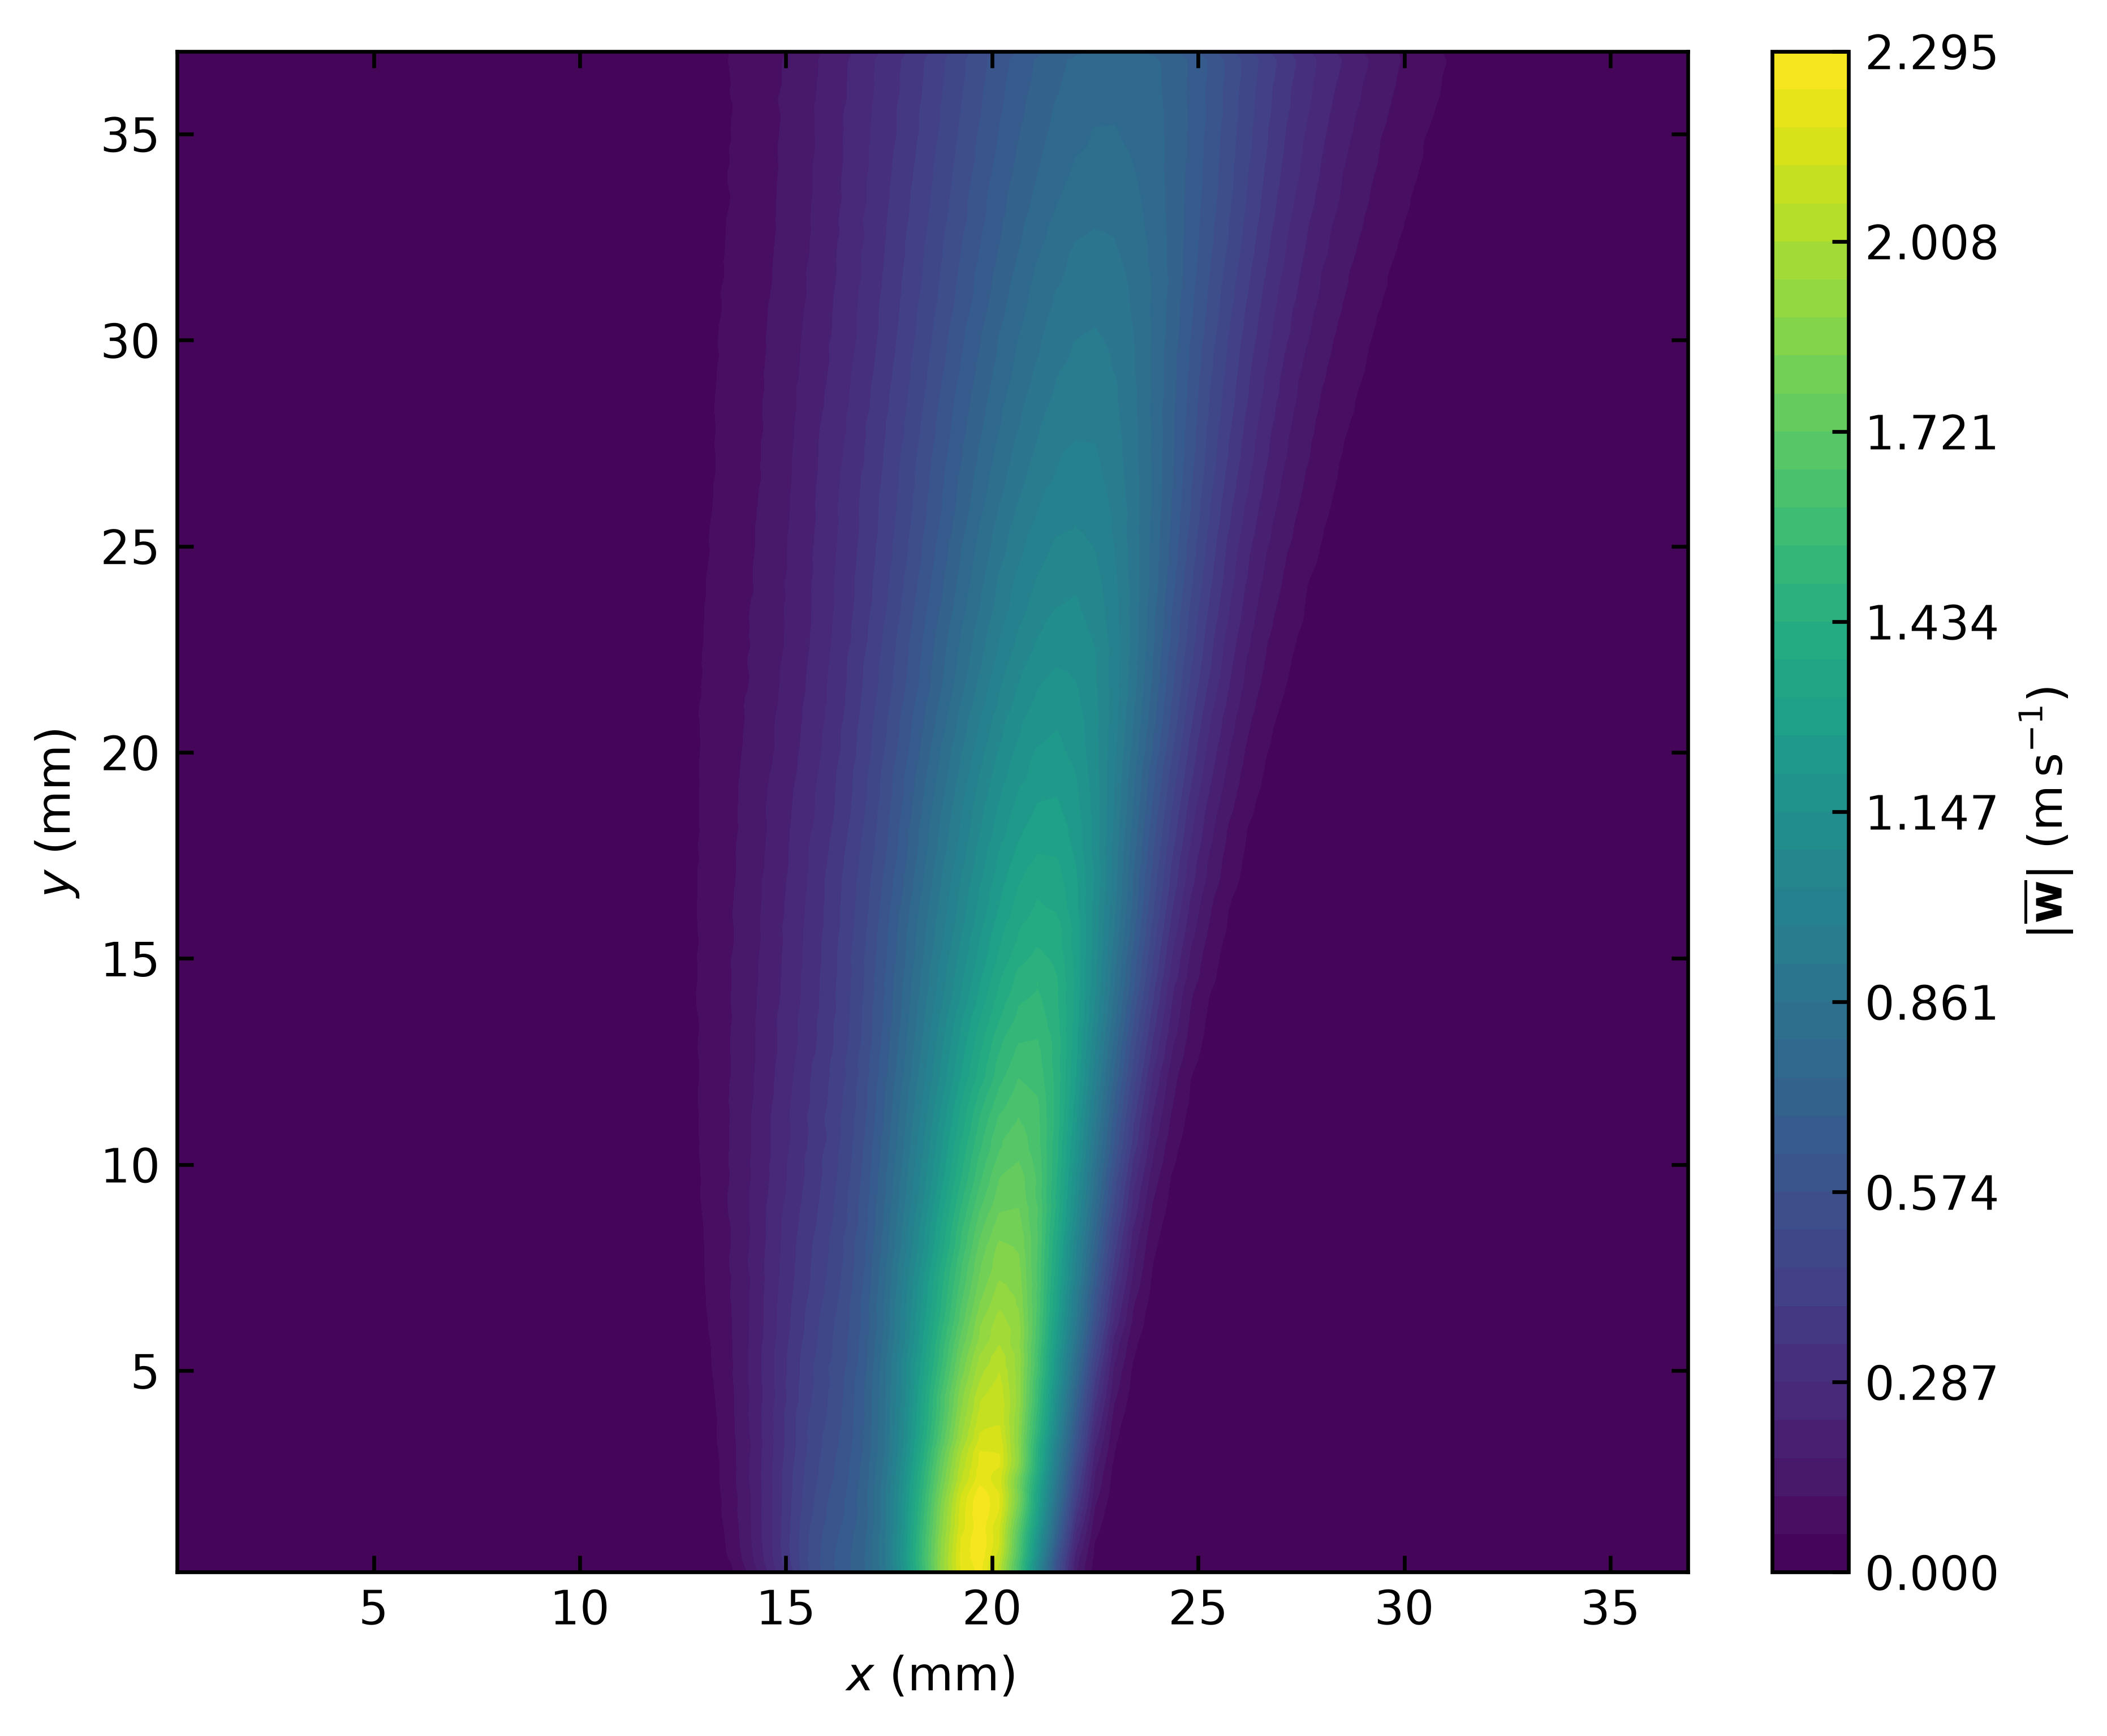

mean_instantaneous_velocity_magnitude


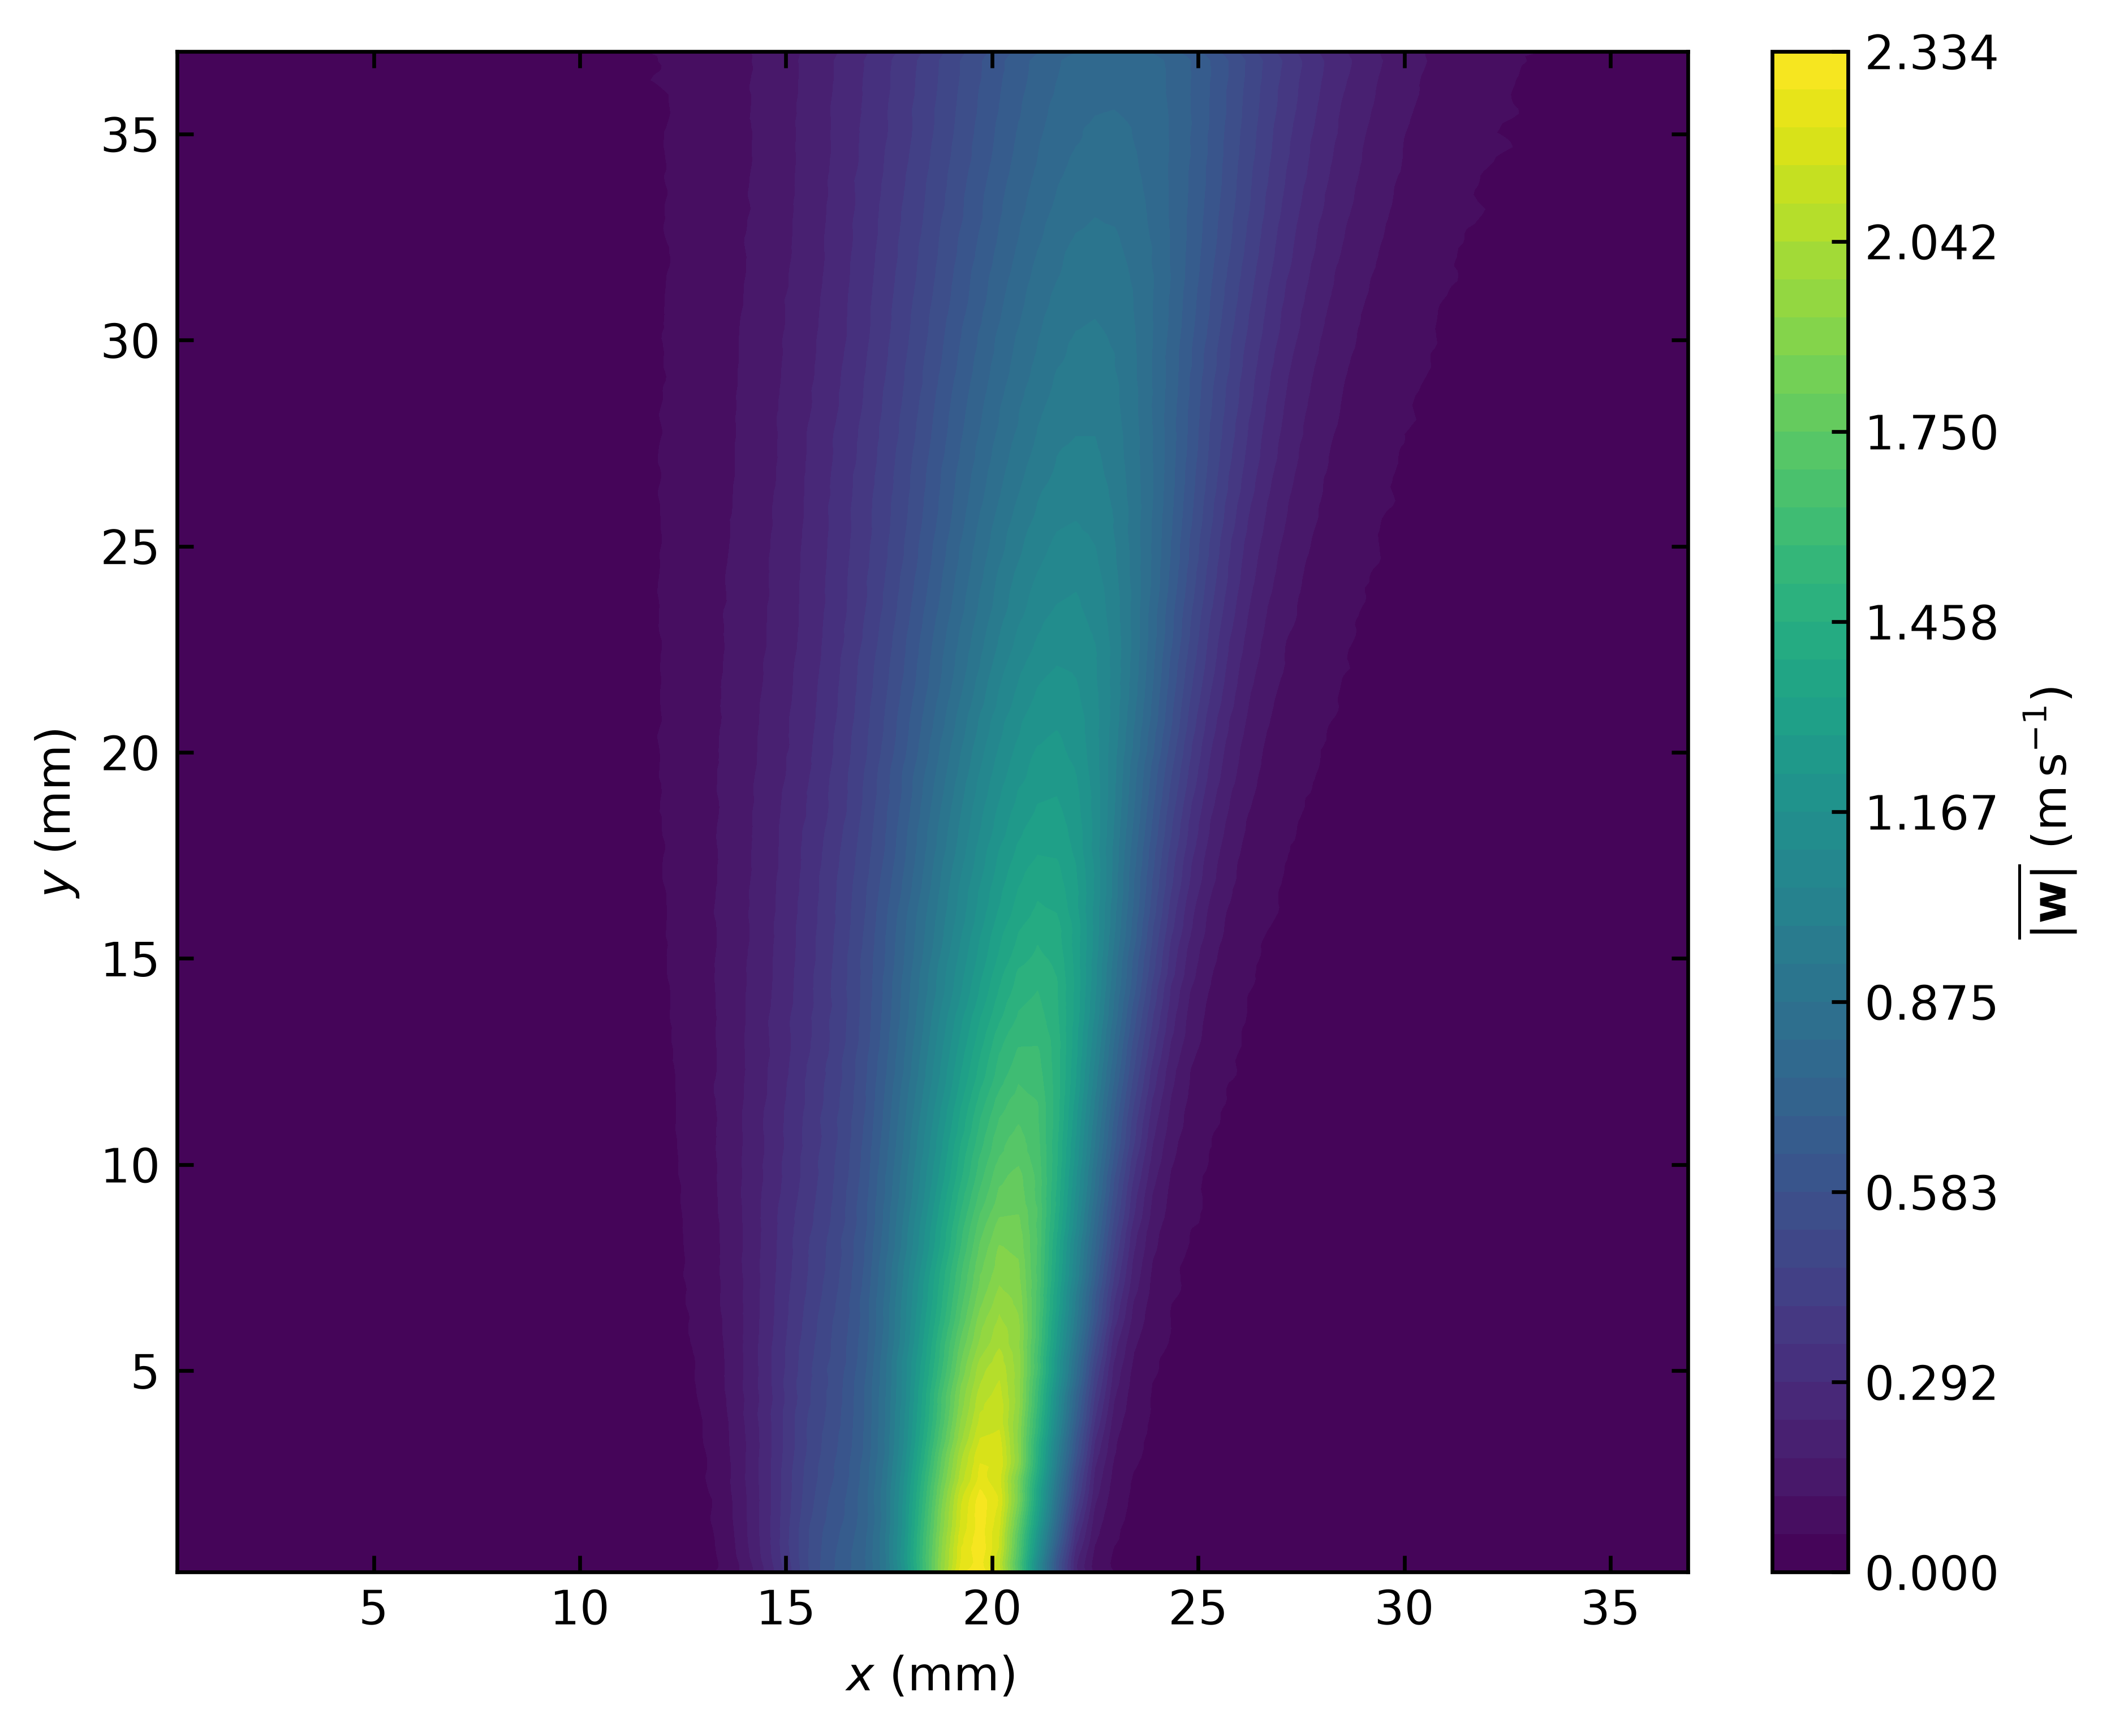

velocity_magnitude_pdf


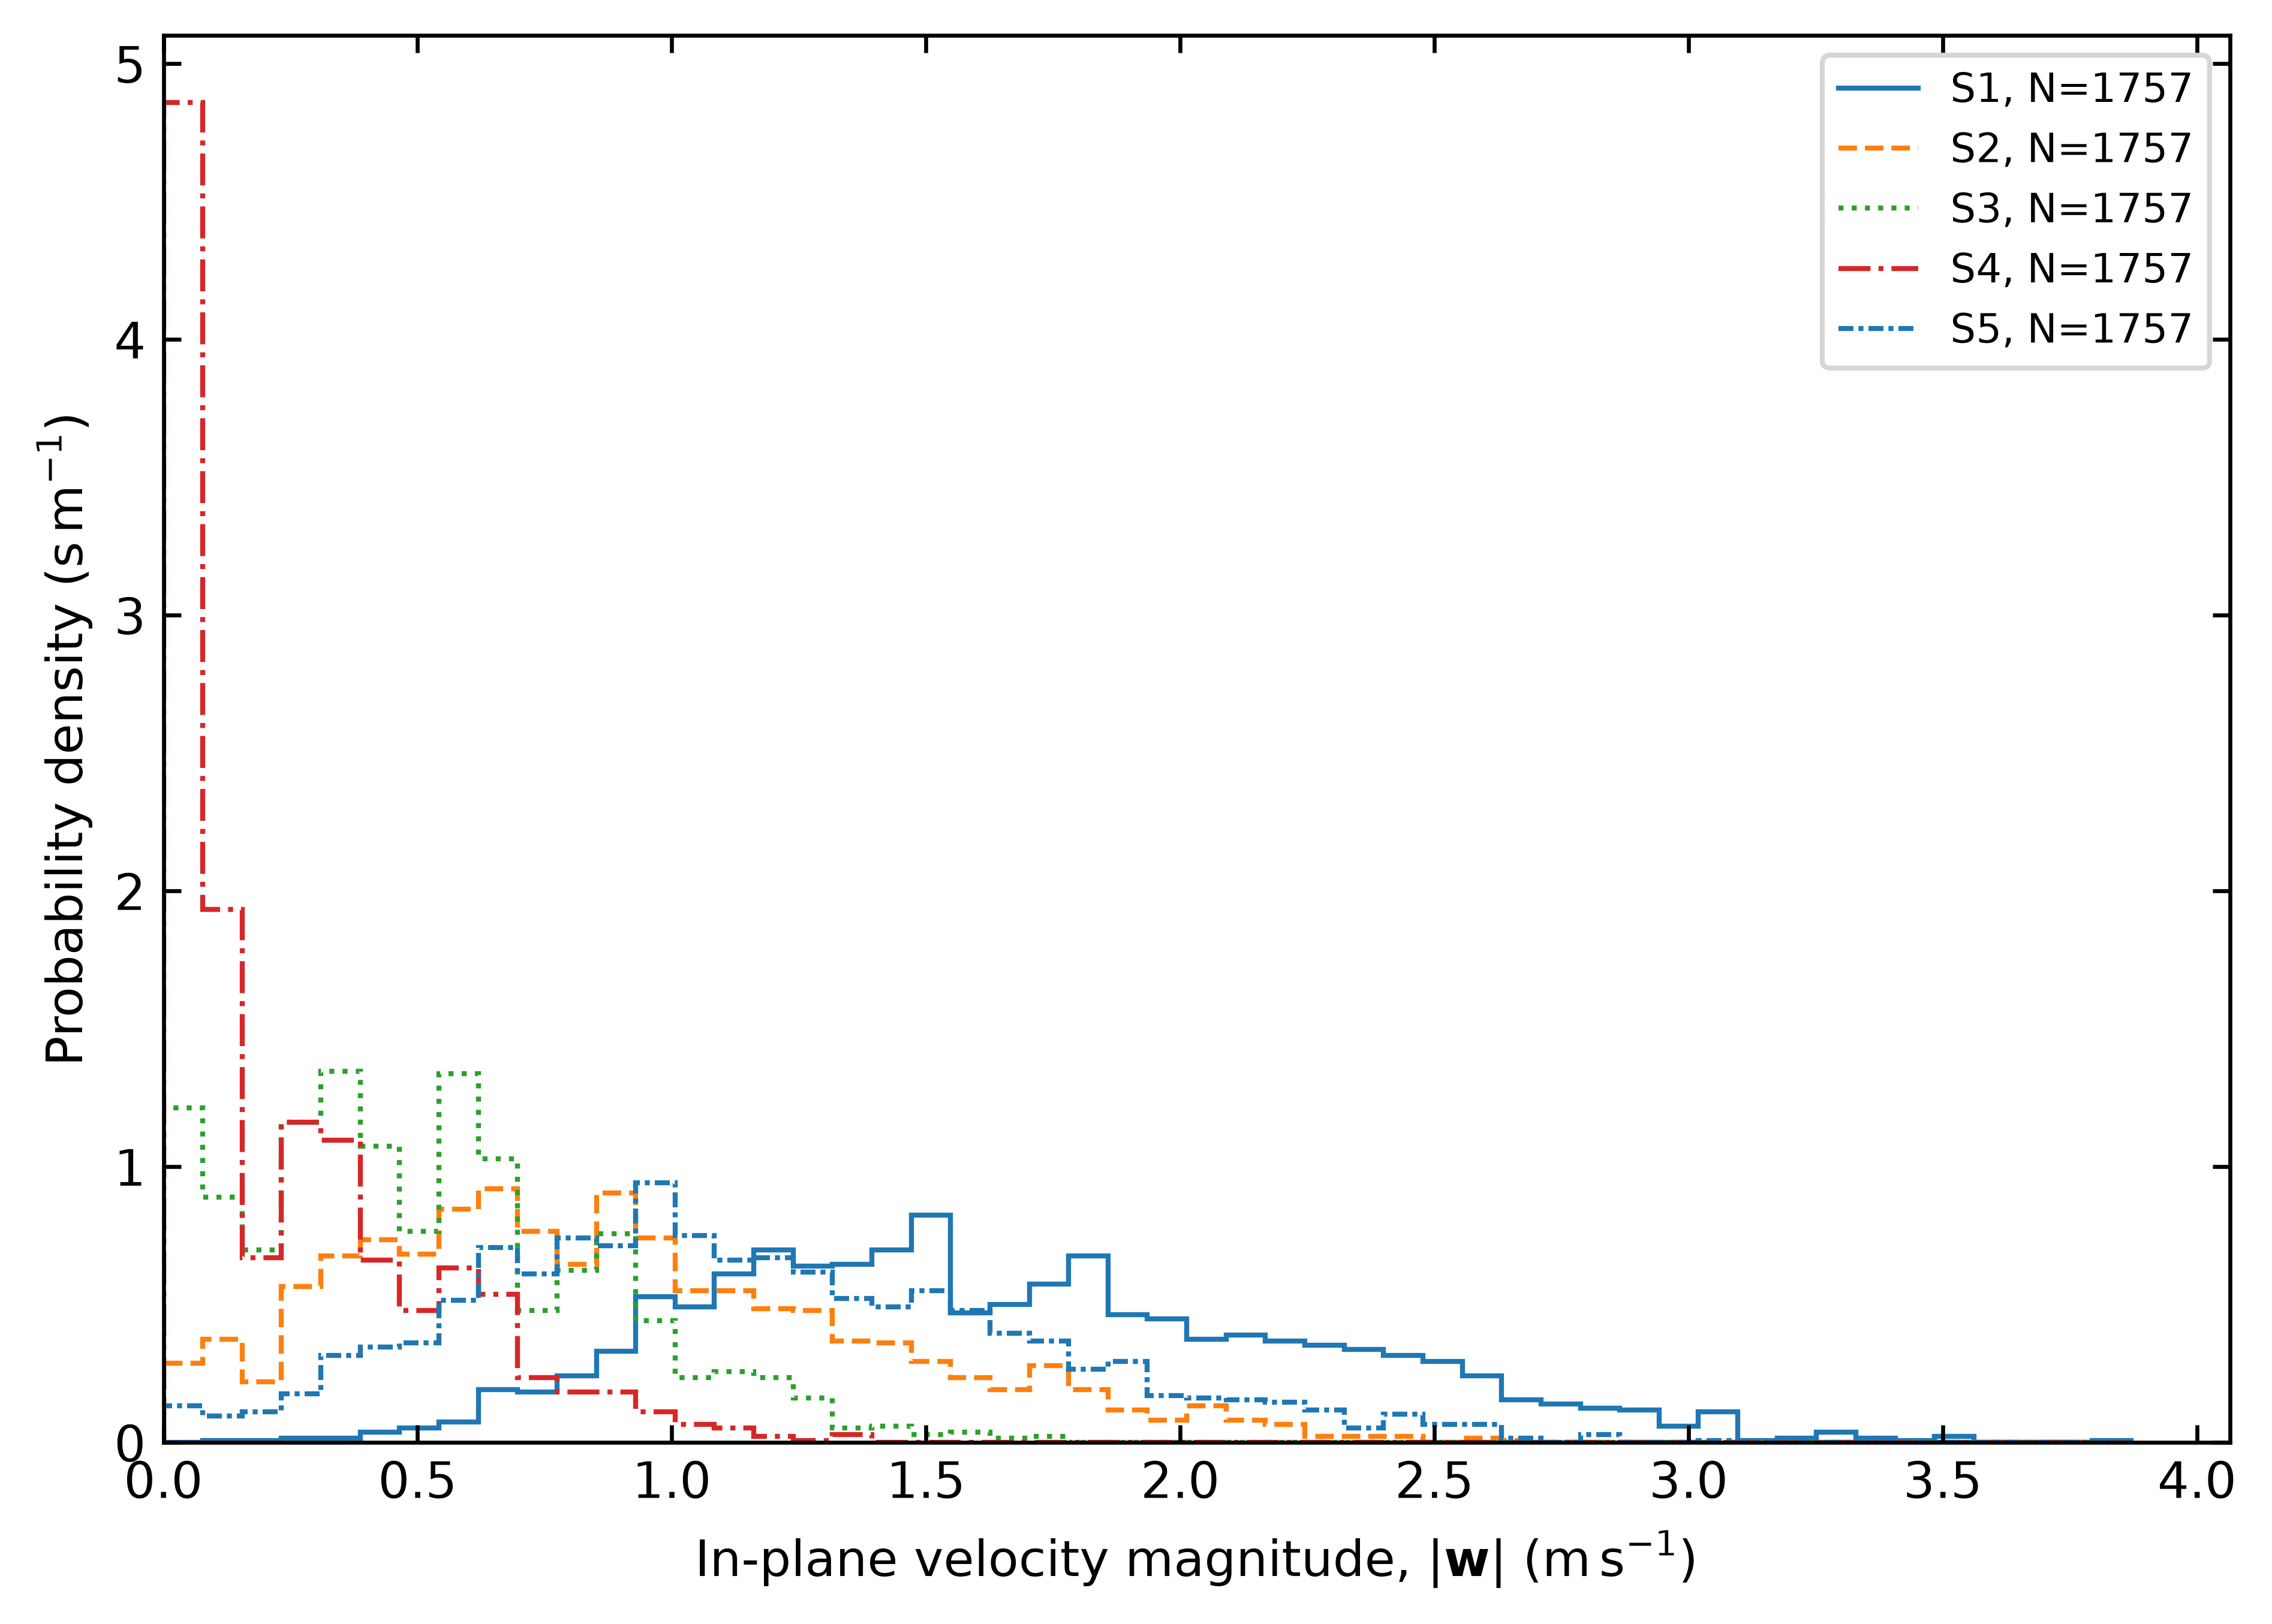

In [3]:
from IPython.display import display,Image,Markdown
display(Markdown((output/'methods/METHODS.md').read_text(encoding='utf-8')))
display(Markdown('## Primary mean-component contours'))
for name in ['mean_v','mean_u']:
    display(Image(filename=str(output/'figures'/(name+'.png')),width=600))
display(Markdown('## Component fluctuations, profiles and distributions'))
for name in ['rms_v','rms_u','covariance','correlation','sampling_stations',
             'profile_mean_v','profile_rms_v','profile_rms_u','profile_covariance',
             'v_pdf','u_pdf','v_cdf','u_cdf','frame_879_v','frame_879_u','frame_879_quiver']:
    print(name)
    display(Image(filename=str(output/'figures'/(name+'.png')),width=600))
display(Markdown('## Supplementary in-plane velocity magnitude'))
for name in ['magnitude_mean_vector','mean_instantaneous_velocity_magnitude','velocity_magnitude_pdf']:
    print(name)
    display(Image(filename=str(output/'figures'/(name+'.png')),width=600))


In [4]:
print('Measured extrema and display limits are reported separately:')
print((output/'methods/summary.json').read_text())
print((output/'methods/validation.json').read_text())
import csv
with (output/'data/vector_comparison.csv').open() as f: rows=list(csv.DictReader(f))
columns=list(rows[0])
table=[' | '.join(columns),' | '.join(['---']*len(columns))]
table+=[' | '.join(row[c] for c in columns) for row in rows]
display(Markdown(chr(10).join(table)))


Measured extrema and display limits are reported separately:
{
  "mean_axial_velocity_measured_range_m_s": [
    -0.031319289573753975,
    2.2855091645694583
  ],
  "mean_axial_contour_colour_limits_m_s": [
    0.0,
    2.2855091645694583
  ],
  "negative_mean_axial_nodes": 14345,
  "figure_count": 51,
  "publication_figure_count": 37,
  "diagnostic_figure_count": 14,
  "local_N_range": [
    1757,
    1757
  ],
  "selected_frame_keys": [
    "1",
    "879",
    "1757"
  ],
  "observed_grid_node_maximum": {
    "row": 304,
    "column": 42,
    "x_mm": 19.71275,
    "y_mm": 1.74,
    "N": 1757,
    "mean_v_m_s": 2.2855091645694583
  }
}
{
  "calibration_ratio": 1.4356435643564356,
  "scaling_max_absolute_errors": {
    "mean_v": 9.325873406851315e-15,
    "mean_u": 9.43689570931383e-16,
    "rms_v": 2.55351295663786e-15,
    "rms_u": 8.326672684688674e-16,
    "magnitude_mean_vector": 9.325873406851315e-15,
    "mean_instantaneous_velocity_magnitude": 9.547918011776346e-15,
    "covar

frame_key | row | column | exported_x | exported_y | x_mm | y_mm | stored_us | stored_vs | u_m_s | v_m_s | flag
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
1 | 287 | 40 | 2591.0 | 512.0 | 18.784750000000003 | 3.712 | 0.4987640380859375 | 3.8663787841796875 | 0.14464157104492187 | 1.1212498474121093 | 1
1 | 159 | 40 | 2591.0 | 2560.0 | 18.784750000000003 | 18.560000000000002 | 1.2717132568359375 | 3.8921127319335938 | 0.36879684448242184 | 1.128712692260742 | 1
1 | 32 | 40 | 2591.0 | 4592.0 | 18.784750000000003 | 33.292 | 0.582421600818634 | 1.4049326181411743 | 0.16890226423740387 | 0.4074304592609405 | 1
879 | 287 | 40 | 2591.0 | 512.0 | 18.784750000000003 | 3.712 | 0.093841552734375 | 9.051025390625 | 0.027214050292968747 | 2.62479736328125 | 1
879 | 159 | 40 | 2591.0 | 2560.0 | 18.784750000000003 | 18.560000000000002 | 0.9984893798828125 | 3.986347198486328 | 0.2895619201660156 | 1.1560406875610352 | 1
879 | 32 | 40 | 2591.0 | 4592.0 | 18.784750000000003 | 33.292 | -0.02629205584526062 | 3.080951452255249 | -0.007624696195125579 | 0.8934759211540222 | 1
1757 | 287 | 40 | 2591.0 | 512.0 | 18.784750000000003 | 3.712 | 0.660736083984375 | 3.685882568359375 | 0.19161346435546875 | 1.0689059448242186 | 1
1757 | 159 | 40 | 2591.0 | 2560.0 | 18.784750000000003 | 18.560000000000002 | -0.10408401489257812 | 1.0812339782714844 | -0.030184364318847655 | 0.31355785369873046 | 1
1757 | 32 | 40 | 2591.0 | 4592.0 | 18.784750000000003 | 33.292 | -0.05423635244369507 | 0.2963275909423828 | -0.015728542208671568 | 0.085935001373291 | 1

## Reuse

Edit config/analysis.json and rerun. The same command-line entry point calls
the same reusable accumulator and plotting functions. The eight signed
statistics and numerical figure sources are saved separately from their
display masks. See methods/figure_manifest.json for every export/data link,
methods/colour_limits.json for shared limits, and methods/CAPTIONS.md or .tex
for captions. Previous calibrated archives and original HDF5 files are retained.
